In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

pd.set_option("display.max_columns", None)
%config InlineBackend.figure_format = "png2x"

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
COLORS = {
    "aqua": "#3EAFBD",
    "light_aqua": "#83D5DF",
    "pale_aqua": "#C5F0F0",
    "apricot": "#F6B477",
    "lavender": "#A8B6E5"
}

PALETTE = list(COLORS.values())


PRIMARY_COLOR = COLORS["aqua"]
SECONDARY_COLOR = COLORS["apricot"]
ACCENT_COLOR = COLORS["light_aqua"]
NEUTRAL_COLOR = COLORS["lavender"]


sns.set_theme(
    style="whitegrid",
    palette=PALETTE,
    font_scale=1.0,
    rc={
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.titleweight": "bold",
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.18,
        "grid.linestyle": "--",
        "legend.frameon": False,
        "figure.dpi": 110
    }
)


HEATMAP_CMAP = sns.light_palette(
    PRIMARY_COLOR,
    as_cmap=True
)

# 1. Data Loading

In [ ]:
spend = pd.read_pickle('/content/drive/MyDrive/Final_Project/spend_cleaned.pkl')
contacts = pd.read_pickle('/content/drive/MyDrive/Final_Project/contacts_cleaned.pkl')
calls = pd.read_pickle('/content/drive/MyDrive/Final_Project/calls_cleaned.pkl')
deals = pd.read_pickle('/content/drive/MyDrive/Final_Project/deals_cleaned.pkl')

In [ ]:
print(f"SPEND — {spend.shape[0]} rows, {spend.shape[1]} columns\n")
spend.info()
print()
display(spend.head())

SPEND — 20517 rows, 8 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20517 entries, 0 to 20516
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         20517 non-null  datetime64[ns]
 1   Source       20517 non-null  object        
 2   Campaign     14616 non-null  object        
 3   Impressions  20517 non-null  int64         
 4   Spend        20517 non-null  float64       
 5   Clicks       20517 non-null  int64         
 6   AdGroup      13782 non-null  object        
 7   Ad           13782 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(4)
memory usage: 1.3+ MB



,Date,Source,Campaign,Impressions,Spend,Clicks,AdGroup,Ad
0,2023-07-03,Google Ads,gen_analyst_DE,6,0.00,0,NaN,NaN
1,2023-07-03,Google Ads,performancemax_eng_DE,4,0.01,1,NaN,NaN
2,2023-07-03,Facebook Ads,NaN,0,0.00,0,NaN,NaN
3,2023-07-03,Google Ads,NaN,0,0.00,0,NaN,NaN
4,2023-07-03,CRM,NaN,0,0.00,0,NaN,NaN


In [ ]:
print(f"CONTACTS — {contacts.shape[0]} rows, {contacts.shape[1]} columns\n")
contacts.info()
print()
display(contacts.head())

CONTACTS — 18548 rows, 4 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18548 entries, 0 to 18547
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Id                  18548 non-null  object        
 1   Contact Owner Name  18547 non-null  object        
 2   Created Time        18548 non-null  datetime64[ns]
 3   Modified Time       18548 non-null  datetime64[ns]
dtypes: datetime64[ns](2), object(2)
memory usage: 579.8+ KB



,Id,Contact Owner Name,Created Time,Modified Time
0,5805028000000645014,Rachel White,2023-06-27 11:28:00,2023-12-22 13:34:00
1,5805028000000872003,Charlie Davis,2023-07-03 11:31:00,2024-05-21 10:23:00
2,5805028000000889001,Bob Brown,2023-07-02 22:37:00,2023-12-21 13:17:00
3,5805028000000907006,Bob Brown,2023-07-03 05:44:00,2023-12-29 15:20:00
4,5805028000000939010,Nina Scott,2023-07-04 10:11:00,2024-04-16 16:14:00


In [ ]:
print(f"CALLS — {calls.shape[0]} rows, {calls.shape[1]} columns\n")
calls.info()
print()
display(calls.head())

CALLS — 95594 rows, 9 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95594 entries, 0 to 95593
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Id                          95594 non-null  object        
 1   Call Start Time             95594 non-null  datetime64[ns]
 2   Call Owner Name             95594 non-null  object        
 3   CONTACTID                   91684 non-null  object        
 4   Call Type                   95594 non-null  object        
 5   Call Duration (in seconds)  95511 non-null  float64       
 6   Call Status                 95594 non-null  object        
 7   Outgoing Call Status        86633 non-null  object        
 8   Scheduled in CRM            86633 non-null  float64       
dtypes: datetime64[ns](1), float64(2), object(6)
memory usage: 6.6+ MB



,Id,Call Start Time,Call Owner Name,CONTACTID,Call Type,Call Duration (in seconds),Call Status,Outgoing Call Status,Scheduled in CRM
0,5805028000000805001,2023-06-30 08:43:00,John Doe,NaN,Inbound,171.0,Received,NaN,NaN
1,5805028000000768006,2023-06-30 08:46:00,John Doe,NaN,Outbound,28.0,Attended Dialled,Completed,0.0
2,5805028000000764027,2023-06-30 08:59:00,John Doe,NaN,Outbound,24.0,Attended Dialled,Completed,0.0
3,5805028000000787003,2023-06-30 09:20:00,John Doe,5805028000000645014,Outbound,6.0,Attended Dialled,Completed,0.0
4,5805028000000768019,2023-06-30 09:30:00,John Doe,5805028000000645014,Outbound,11.0,Attended Dialled,Completed,0.0


In [ ]:
print(f"DEALS — {deals.shape[0]} rows, {deals.shape[1]} columns\n")
deals.info()
print()
display(deals.head())

DEALS — 19610 rows, 24 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19610 entries, 0 to 19609
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Id                   19610 non-null  object        
 1   Deal Owner Name      19610 non-null  object        
 2   Closing Date         12990 non-null  datetime64[ns]
 3   Quality              17380 non-null  object        
 4   Stage                19610 non-null  object        
 5   Lost Reason          14236 non-null  object        
 6   Page                 19610 non-null  object        
 7   Campaign             15454 non-null  object        
 8   Content              13637 non-null  object        
 9   Term                 11940 non-null  object        
 10  Source               19610 non-null  object        
 11  Payment Type         485 non-null    object        
 12  Product              3490 non-null   object        
 13 

,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch,Demo Access,SLA Seconds
0,5805028000056864695,Ben Hall,NaT,NaN,New Lead,NaN,/eng/test,03.07.23women,v16,women,Facebook Ads,NaN,NaN,NaN,2024-06-21 15:30:00,<NA>,<NA>,<NA>,<NA>,5805028000056849495,NaN,NaN,False,NaN
1,5805028000056859489,Ulysses Adams,NaT,NaN,New Lead,NaN,/at-eng,NaN,NaN,NaN,Organic,NaN,Web Developer,Morning,2024-06-21 15:23:00,6,<NA>,0,2000,5805028000056834471,NaN,NaN,True,NaN
2,5805028000056832357,Ulysses Adams,2024-06-21,D - Non Target,Lost,Non target,/at-eng,engwien_AT,b1-at,21_06_2024,Telegram posts,NaN,NaN,NaN,2024-06-21 14:45:00,<NA>,<NA>,<NA>,<NA>,5805028000056854421,NaN,NaN,False,1603.0
3,5805028000056824246,Eva Kent,2024-06-21,E - Non Qualified,Lost,Invalid number,/eng,04.07.23recentlymoved_DE,bloggersvideo14com,recentlymoved,Facebook Ads,NaN,NaN,NaN,2024-06-21 13:32:00,<NA>,<NA>,<NA>,<NA>,5805028000056889351,NaN,NaN,False,3604.0
4,5805028000056873292,Ben Hall,2024-06-21,D - Non Target,Lost,Non target,/eng,discovery_DE,website,NaN,Google Ads,NaN,NaN,NaN,2024-06-21 13:21:00,<NA>,<NA>,<NA>,<NA>,5805028000056876176,NaN,NaN,False,3192.0


# 2. Time Series Analysis

In [ ]:
deals_created = (
    deals.set_index("Created Time")
    .resample("D")
    .size()
)

monthly_deals = deals_created.resample("MS").sum()
weekly_deals = deals_created.resample("W-SUN").sum()
daily_deals = deals_created

In [ ]:
periods = [
    (monthly_deals, "Monthly Deal Creation Trend"),
    (weekly_deals, "Weekly Deal Creation Trend"),
    (daily_deals, "Daily Deal Creation Trend")
]

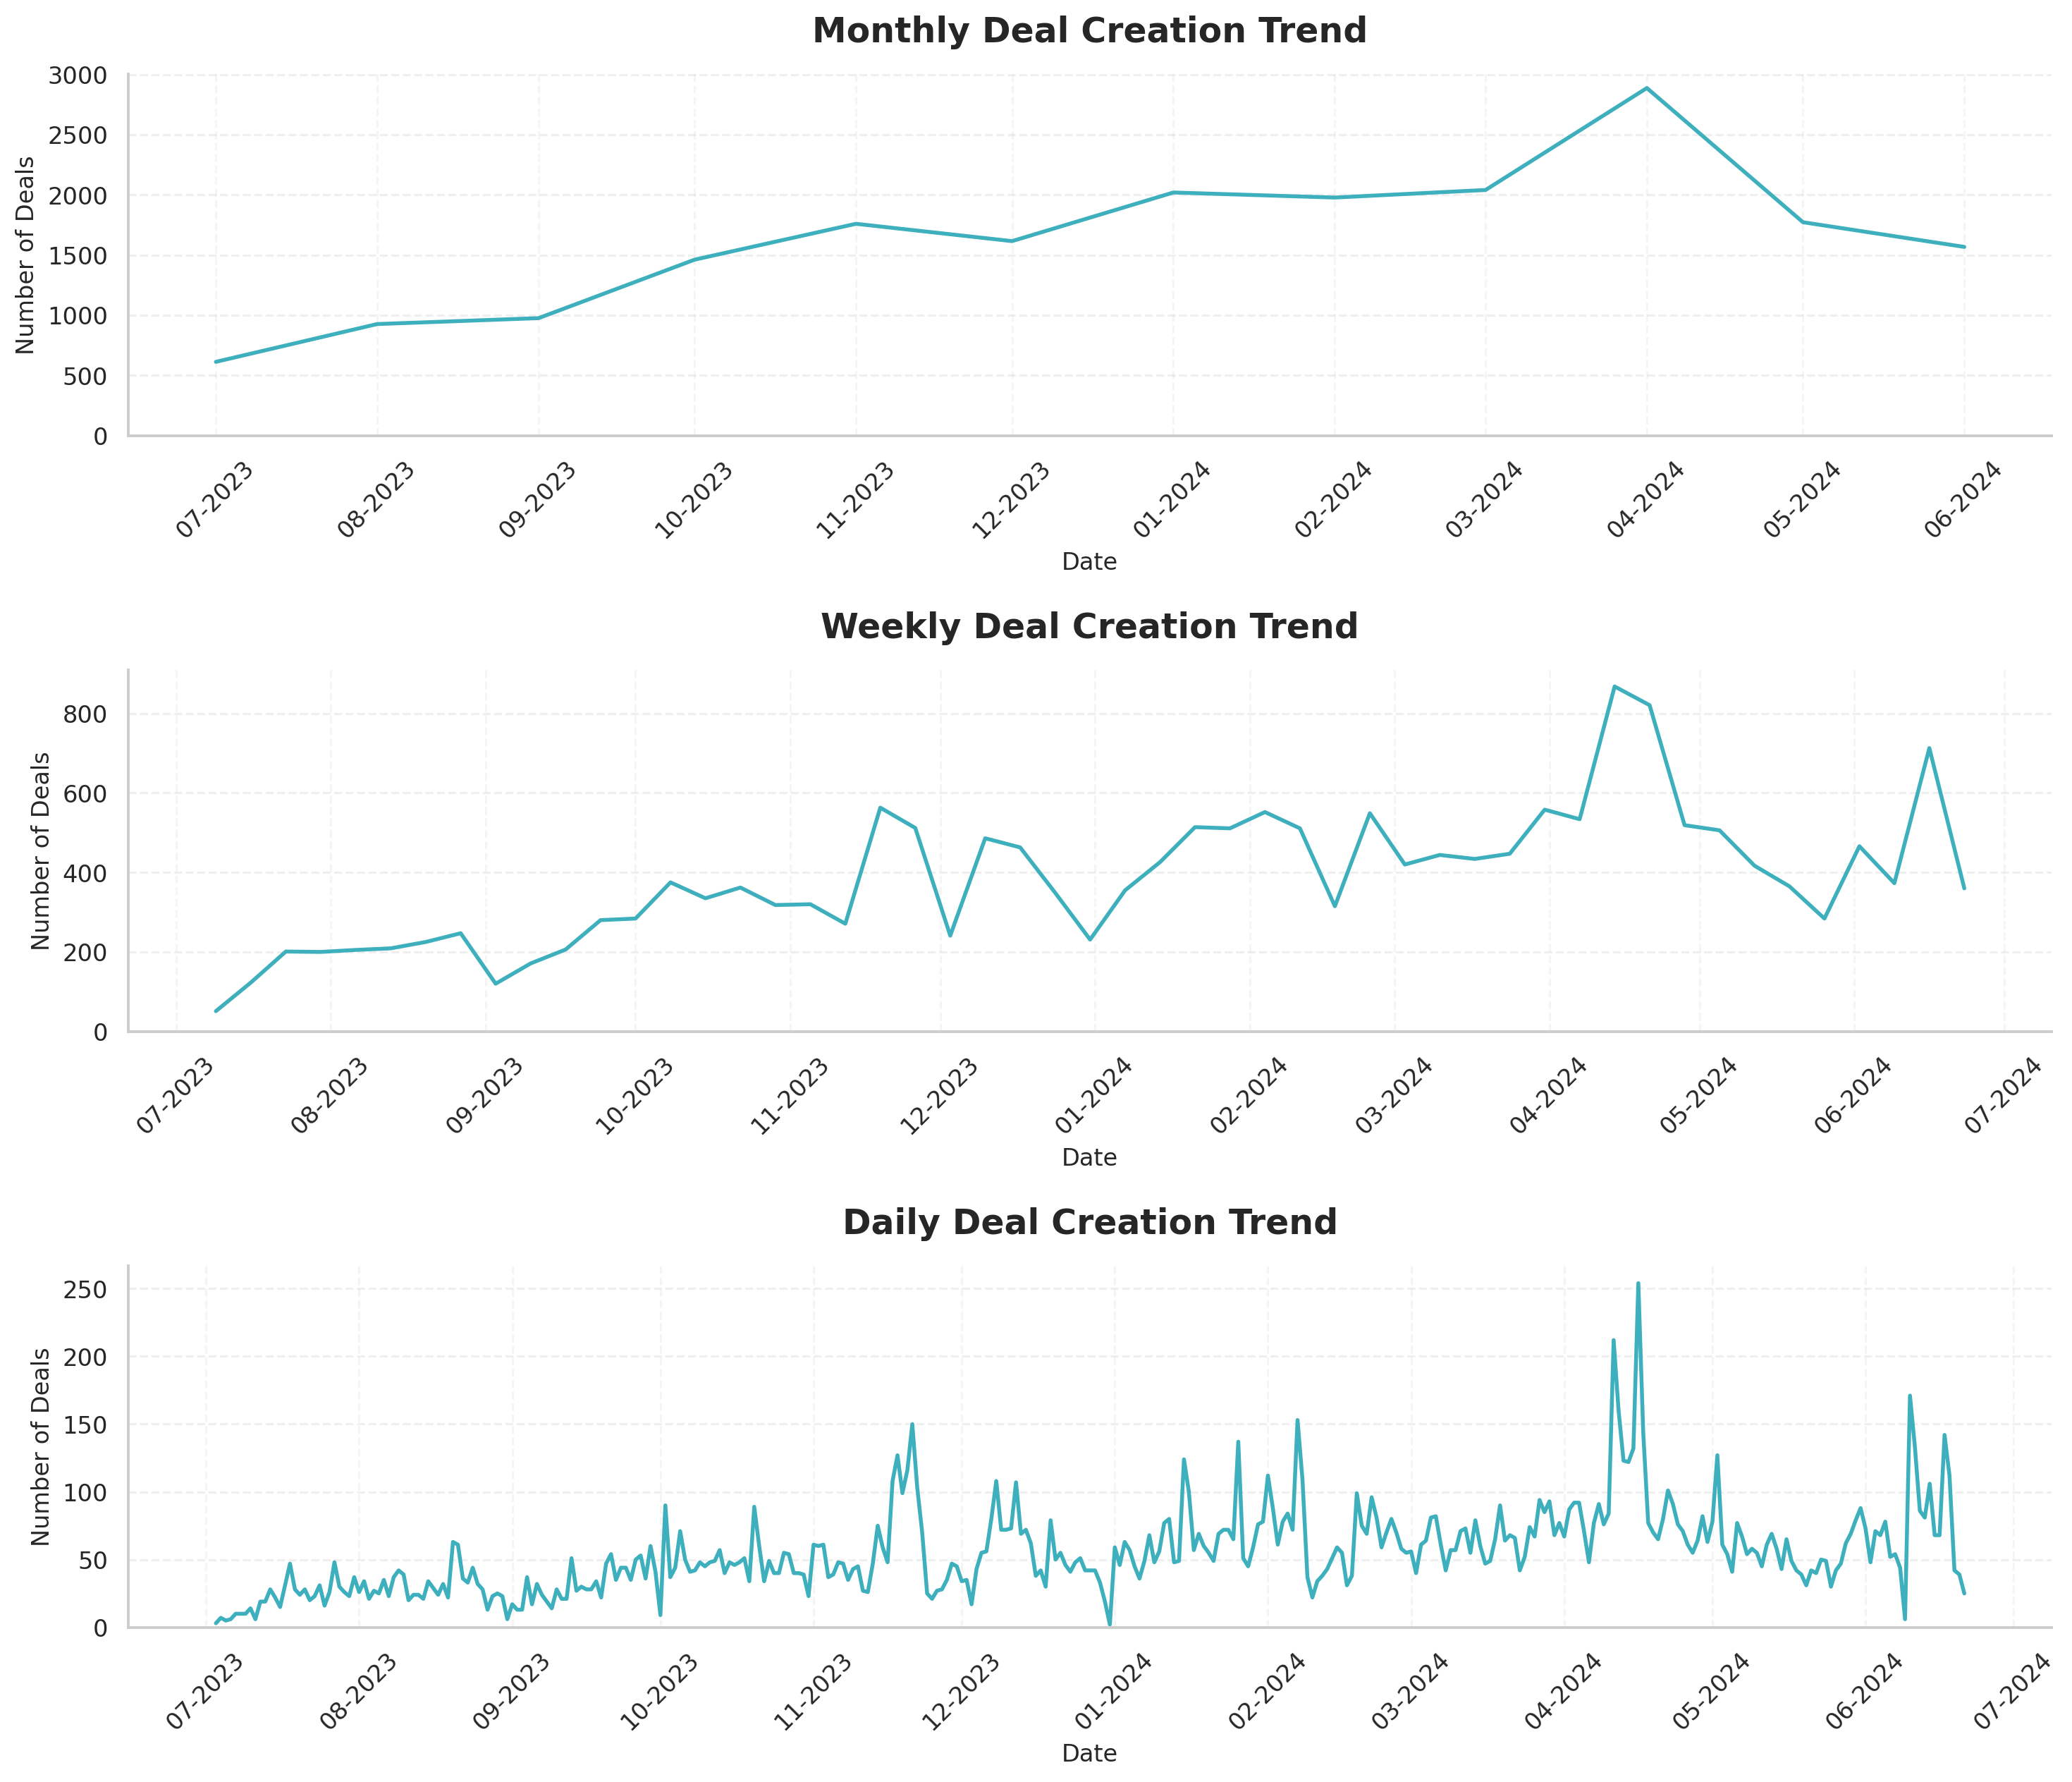

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(16, 13))


for ax, (data, title) in zip(axes, periods):
    sns.lineplot(
        x=data.index,
        y=data.values,
        ax=ax,
        color=PRIMARY_COLOR,
        linewidth=1.8
    )

    ax.set_title(title, fontsize=16, fontweight="bold", pad=15)
    ax.set_xlabel("Date")
    ax.set_ylabel("Number of Deals")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.3)

    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%Y"))
    ax.tick_params(axis="x", rotation=45)

plt.subplots_adjust(hspace=0.65)
plt.show()

Conclusion

Deal creation shows an overall upward trend from July 2023 to spring 2024, with higher activity in early 2024 compared with the second half of 2023. The most significant peak occurs in April 2024, with another noticeable increase in late November 2023.

Monthly aggregation highlights the overall trend but smooths out short-term fluctuations, while daily data is highly volatile. Weekly aggregation provides the best balance between detail and readability and will therefore be used in subsequent time series analyses.

The sharp decline at the end of the charts is explained by incomplete data for the final period, as the dataset ends on June 21, 2024. Therefore, this decline should not be interpreted as an actual decrease in business activity.

In [ ]:
weekly_calls = (
    calls.set_index("Call Start Time")
    .resample("W-SUN")
    .size()
    .rename("Calls")
)

weekly_closed = (
    deals.dropna(subset=["Closing Date"])
    .set_index("Closing Date")
    .resample("W-SUN")
    .size()
    .rename("Closed Deals")
)

In [ ]:
weekly_activity = pd.concat(
    [
        weekly_deals.rename("New Deals"),
        weekly_closed,
        weekly_calls
    ],
    axis=1
).fillna(0)

In [ ]:
start_date = max(
    deals["Created Time"].min(),
    calls["Call Start Time"].min()
).normalize()

end_date = min(
    deals["Created Time"].max(),
    calls["Call Start Time"].max()
).normalize()

In [ ]:
weekly_activity = weekly_activity.loc[
    (weekly_activity.index - pd.Timedelta(days=6) >= start_date)
    & (weekly_activity.index <= end_date)
]

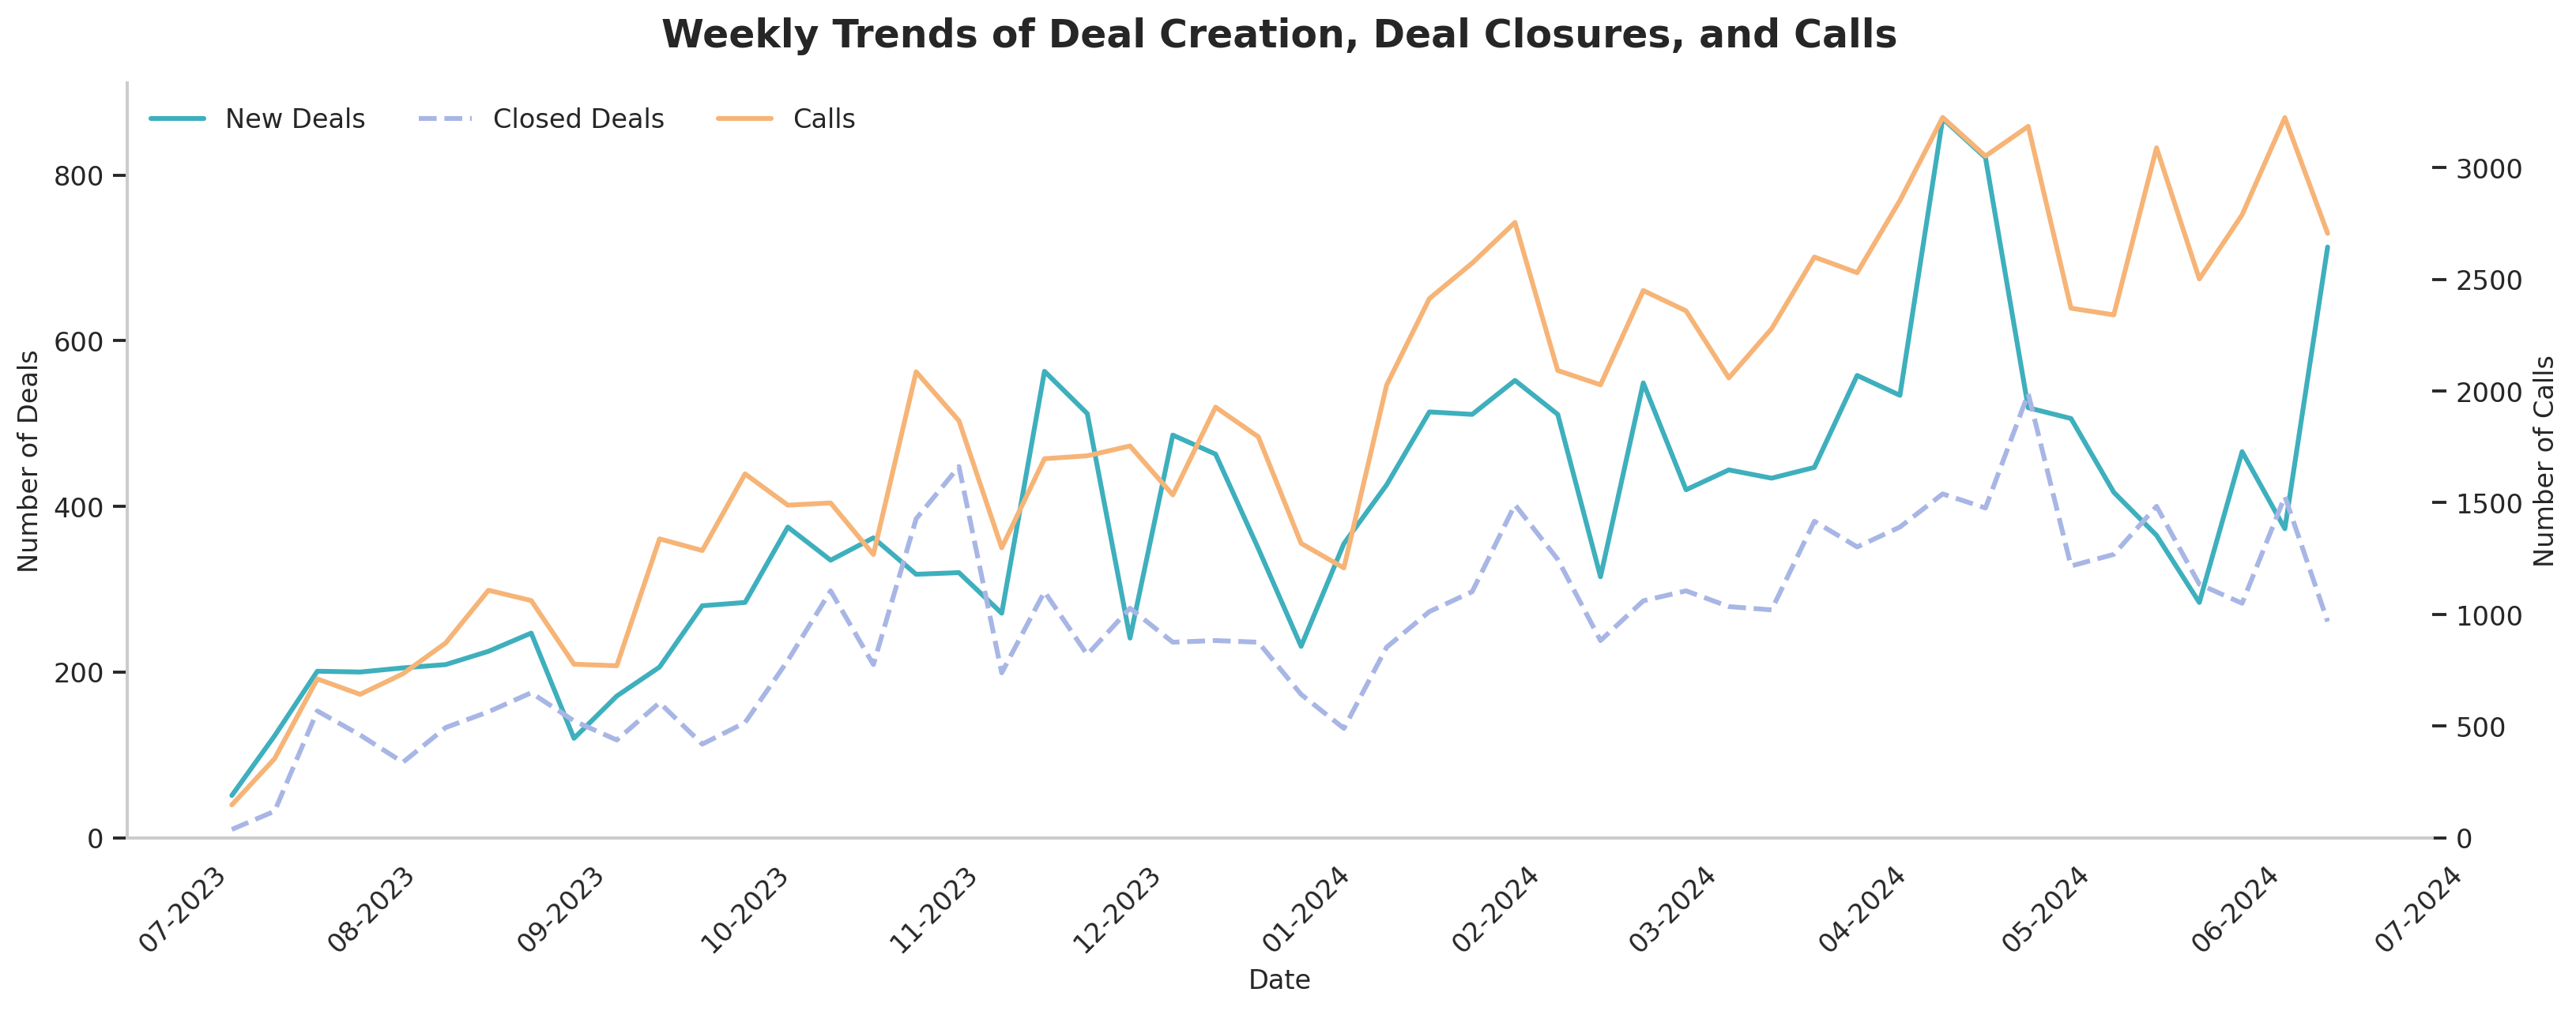

WEEKLY CORRELATIONS WITH CALLS
New Deals vs Calls: 0.792
Closed Deals vs Calls: 0.886


In [ ]:
fig, ax1 = plt.subplots(figsize=(15, 6))
ax2 = ax1.twinx()

sns.lineplot(
    data=weekly_activity,
    x=weekly_activity.index,
    y="New Deals",
    ax=ax1,
    color=PRIMARY_COLOR,
    linewidth=2,
    label="New Deals"
)

sns.lineplot(
    data=weekly_activity,
    x=weekly_activity.index,
    y="Closed Deals",
    ax=ax1,
    color=NEUTRAL_COLOR,
    linewidth=2,
    linestyle="--",
    label="Closed Deals"
)

sns.lineplot(
    data=weekly_activity,
    x=weekly_activity.index,
    y="Calls",
    ax=ax2,
    color=SECONDARY_COLOR,
    linewidth=2,
    label="Calls"
)

ax1.set_title(
    "Weekly Trends of Deal Creation, Deal Closures, and Calls",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Number of Deals")
ax2.set_ylabel("Number of Calls")

ax1.set_ylim(bottom=0)
ax2.set_ylim(bottom=0)

ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%m-%Y"))
ax1.tick_params(axis="x", rotation=45)

ax1.grid(False)
ax2.grid(False)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left",
    ncol=3,
    frameon=False
)

if ax2.get_legend() is not None:
    ax2.get_legend().remove()

plt.tight_layout()
plt.show()


correlations = weekly_activity[
    ["New Deals", "Closed Deals", "Calls"]
].corr()["Calls"]

print("WEEKLY CORRELATIONS WITH CALLS")
print(f"New Deals vs Calls: {correlations['New Deals']:.3f}")
print(f"Closed Deals vs Calls: {correlations['Closed Deals']:.3f}")

Conclusion

Weekly deal creation, deal closures, and call activity generally show an upward trend, with particularly noticeable peaks in spring 2024. Call activity has a strong positive correlation with both new deals (r = 0.792) and closed deals (r = 0.886), with a stronger relationship observed for deal closures.

The stronger correlation with closed deals suggests that phone calls may play an important role in the sales process. Managers may help customers make decisions by answering questions, addressing concerns, and following up on existing deals. However, increased call activity may also result from a higher volume of deals requiring follow-up.

Deal closures generally remain below new deal creation and show somewhat different weekly fluctuations. This may be because deals take time to process and close.

In [ ]:
closed_deals = deals.dropna(subset=["Closing Date"]).copy()

closed_deals["Closing Duration"] = (
    closed_deals["Closing Date"].dt.normalize()
    - closed_deals["Created Time"].dt.normalize()
).dt.days

In [ ]:
median_duration = closed_deals["Closing Duration"].median()
mean_duration = closed_deals["Closing Duration"].mean()

In [ ]:
duration_counts = (
    closed_deals["Closing Duration"]
    .value_counts()
    .sort_index()
)

In [ ]:
fig = go.Figure()

fig.add_trace(
    go.Bar(
        x=duration_counts.index,
        y=duration_counts.values,
        marker_color=PRIMARY_COLOR,
        hovertemplate=(
            "Closing Duration: %{x} days"
            "<br>Number of Deals: %{y}<extra></extra>"
        )
    )
)

fig.add_vline(
    x=median_duration,
    line_color=SECONDARY_COLOR,
    line_dash="dash",
    line_width=2
)

fig.add_vline(
    x=mean_duration,
    line_color=NEUTRAL_COLOR,
    line_dash="dash",
    line_width=2
)

fig.add_annotation(
    x=median_duration,
    y=0.95,
    yref="paper",
    text=f"Median: {median_duration:.0f} days",
    textangle=-90,
    showarrow=False,
    font=dict(color=SECONDARY_COLOR, size=12),
    xanchor="left"
)

fig.add_annotation(
    x=mean_duration,
    y=0.95,
    yref="paper",
    text=f"Mean: {mean_duration:.1f} days",
    textangle=-90,
    showarrow=False,
    font=dict(color=NEUTRAL_COLOR, size=12),
    xanchor="left"
)

fig.update_layout(
    title=dict(
        text="<b>Deal Closing Duration Distribution</b>",
        x=0.5,
        xanchor="center",
        y=0.93,
        font=dict(size=17, color="#263238")
    ),
    xaxis_title="Closing Duration (Days)",
    yaxis_title="Number of Deals",
    height=650,
    autosize=True,
    bargap=0.05,
    dragmode="zoom",
    showlegend=False,
    plot_bgcolor="white",
    paper_bgcolor="white",
    font=dict(size=12),
    margin=dict(l=65, r=40, t=80, b=65)
)

fig.update_xaxes(showgrid=False, rangemode="tozero")
fig.update_yaxes(showgrid=False, range=[0, 2500], dtick=500)

fig.show(config={"responsive": True})

print("CLOSING DURATION SUMMARY")
print(f"Median: {median_duration:.0f} days")
print(f"Mean: {mean_duration:.1f} days")
print(f"Maximum: {closed_deals['Closing Duration'].max()} days")

CLOSING DURATION SUMMARY
Median: 4 days
Mean: 16.1 days
Maximum: 335 days


In [ ]:
final_deals = closed_deals.loc[
    closed_deals["Stage"].isin(["Payment Done", "Lost"])
].copy()

In [ ]:
duration_stats = (
    final_deals.groupby("Stage")["Closing Duration"]
    .agg(["count", "mean", "median"])
)

In [ ]:
x_max = 100

plot_deals = final_deals.loc[
    final_deals["Closing Duration"] <= x_max
].copy()

In [ ]:
tail_summary = (
    final_deals.assign(
        Over_100_Days=final_deals["Closing Duration"] > 100
    )
    .groupby("Stage")["Over_100_Days"]
    .agg(["sum", "count", "mean"])
    .rename(columns={
        "sum": "Deals Over 100 Days",
        "count": "Total Deals",
        "mean": "Share Over 100 Days"
    })
)

tail_summary["Share Over 100 Days"] = (
    tail_summary["Share Over 100 Days"] * 100
).round(2)

CLOSING DURATION BY STAGE


,count,mean,median
Stage,,,
Lost,12229,15.20,4.0
Payment Done,506,33.49,17.0


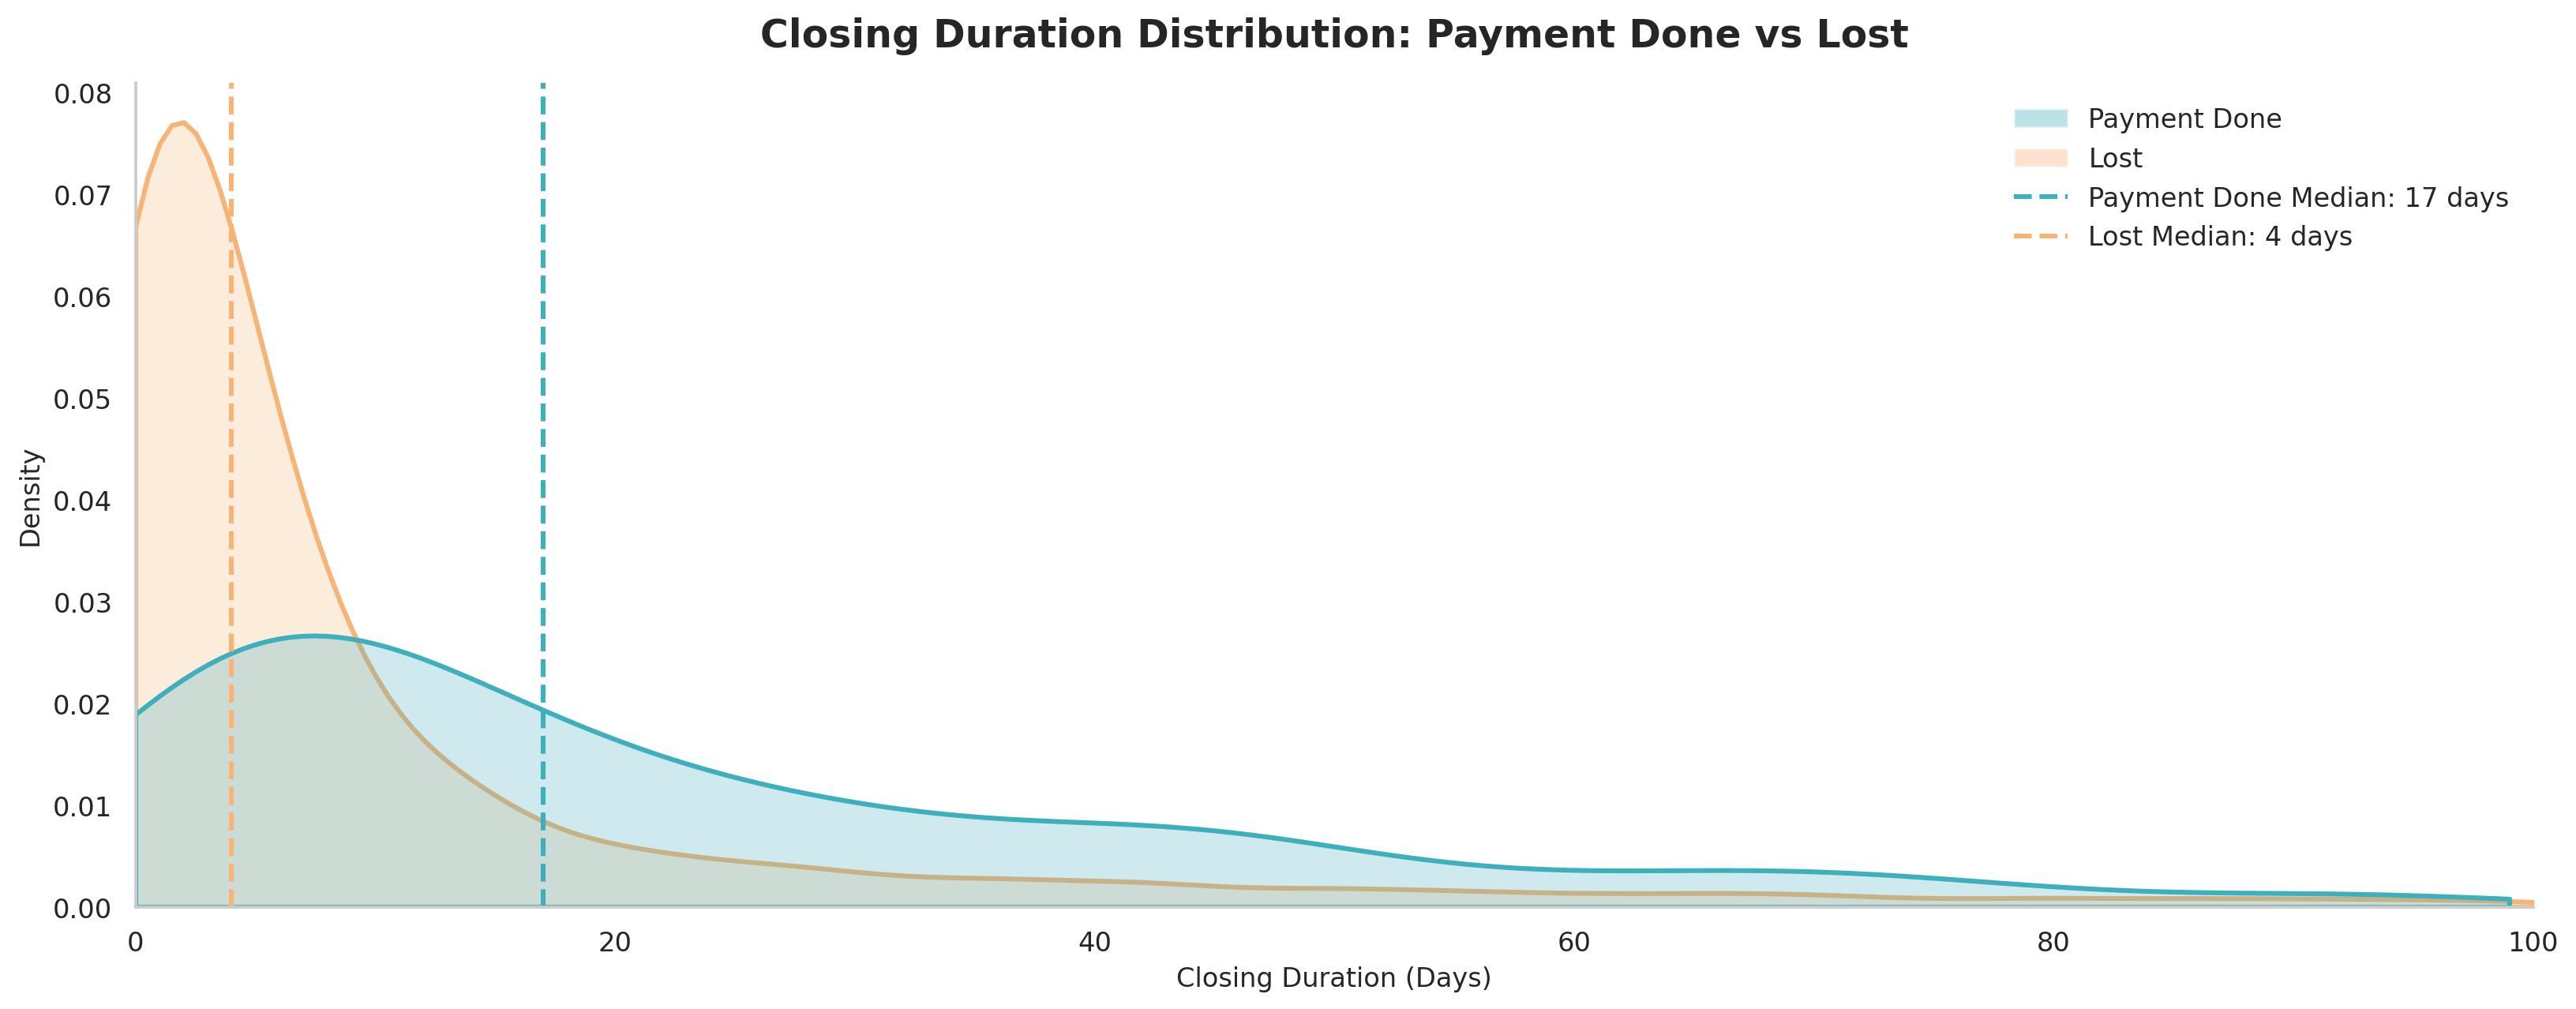

TAIL SUMMARY


,Deals Over 100 Days,Total Deals,Share Over 100 Days
Stage,,,
Lost,404,12229,3.3
Payment Done,41,506,8.1


In [ ]:
print("CLOSING DURATION BY STAGE")
display(duration_stats.round(2))


fig, ax = plt.subplots(figsize=(15, 6))

sns.kdeplot(
    data=plot_deals,
    x="Closing Duration",
    hue="Stage",
    hue_order=["Payment Done", "Lost"],
    palette={
        "Payment Done": PRIMARY_COLOR,
        "Lost": SECONDARY_COLOR
    },
    common_norm=False,
    fill=True,
    alpha=0.25,
    linewidth=2,
    cut=0,
    ax=ax
)

for stage, color in [
    ("Payment Done", PRIMARY_COLOR),
    ("Lost", SECONDARY_COLOR)
]:
    ax.axvline(
        duration_stats.loc[stage, "median"],
        color=color,
        linestyle="--",
        linewidth=2
    )

legend_handles = [
    Patch(
        facecolor=PRIMARY_COLOR,
        alpha=0.35,
        label="Payment Done"
    ),
    Patch(
        facecolor=SECONDARY_COLOR,
        alpha=0.35,
        label="Lost"
    ),
    Line2D(
        [0], [0],
        color=PRIMARY_COLOR,
        linestyle="--",
        linewidth=2,
        label=f"Payment Done Median: {duration_stats.loc['Payment Done', 'median']:.0f} days"
    ),
    Line2D(
        [0], [0],
        color=SECONDARY_COLOR,
        linestyle="--",
        linewidth=2,
        label=f"Lost Median: {duration_stats.loc['Lost', 'median']:.0f} days"
    )
]

ax.legend(
    handles=legend_handles,
    loc="upper right",
    frameon=False
)

ax.set_title(
    "Closing Duration Distribution: Payment Done vs Lost",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Closing Duration (Days)")
ax.set_ylabel("Density")
ax.set_xlim(0, x_max)
ax.grid(False)

plt.tight_layout()
plt.show()



print("TAIL SUMMARY")
display(tail_summary)

Conclusion

Deal closing duration is strongly right-skewed: most deals close within the first few days, while some take considerably longer. The overall median is 4 days, compared with a mean of approximately 16 days.

`Payment Done` deals take significantly longer to close than `Lost` deals. The median closing duration is 17 days for paid deals versus 4 days for lost deals, while the means are 33.49 and 15.20 days, respectively.

The long tail also differs between the groups. Among paid deals, 41 out of 506 (8.1%) took more than 100 days to close, compared with 404 out of 12,229 lost deals (3.3%). Although the absolute number of long-lasting lost deals is higher, their proportion is much smaller. This means that closing durations above 100 days are approximately 2.5 times more common among paid deals.

These results suggest that successful sales may require more time for consultations, follow-ups, and customer decision-making, while many unsuccessful deals are closed relatively quickly.

# 3. Marketing Campaign Effectiveness

In [ ]:
contacts_ids = set(contacts["Id"].dropna())
deals_ids = set(deals["Contact Name"].dropna())
calls_ids = set(calls["CONTACTID"].dropna())

print("UNIQUE CONTACT IDS")
print(f"Contacts: {len(contacts_ids)}")
print(f"Deals: {len(deals_ids)}")

print("\nCONTACTS VS DEALS")
print(f"In Contacts, not in Deals: {len(contacts_ids - deals_ids)}")
print(f"In Deals, not in Contacts: {len(deals_ids - contacts_ids)}")
print(f"In both datasets: {len(contacts_ids & deals_ids)}")

UNIQUE CONTACT IDS
Contacts: 18548
Deals: 16868

CONTACTS VS DEALS
In Contacts, not in Deals: 1680
In Deals, not in Contacts: 0
In both datasets: 16868


In [ ]:
print("TOTAL UNIQUE CONTACTS IN DEALS")
print(deals["Contact Name"].nunique())

print("\nCONTACTS WITH CAMPAIGN")
print(deals.loc[deals["Campaign"].notna(), "Contact Name"].nunique())

print("\nCONTACTS WITH SOURCE")
print(deals.loc[deals["Source"].notna(), "Contact Name"].nunique())

campaigns_per_contact = (
    deals.dropna(subset=["Campaign"])
    .groupby("Contact Name")["Campaign"]
    .nunique()
)

print("\nNUMBER OF CAMPAIGNS PER CONTACT")
display(campaigns_per_contact.value_counts().sort_index())

print("\nCONTACTS WITH MULTIPLE CAMPAIGNS")
print((campaigns_per_contact > 1).sum())

sources_per_contact = (
    deals.dropna(subset=["Source"])
    .groupby("Contact Name")["Source"]
    .nunique()
)

print("\nNUMBER OF SOURCES PER CONTACT")
display(sources_per_contact.value_counts().sort_index())

print("\nCONTACTS WITH MULTIPLE SOURCES")
print((sources_per_contact > 1).sum())

attribution = (
    deals[["Contact Name", "Source", "Campaign"]]
    .dropna(subset=["Contact Name", "Source", "Campaign"])
    .drop_duplicates()
)

combinations_per_contact = (
    attribution.groupby("Contact Name")
    .size()
)

print("\nCONTACTS WITH SOURCE + CAMPAIGN")
print(attribution["Contact Name"].nunique())

print("\nNUMBER OF SOURCE + CAMPAIGN COMBINATIONS PER CONTACT")
display(combinations_per_contact.value_counts().sort_index())

print("\nCONTACTS WITH MULTIPLE SOURCE + CAMPAIGN COMBINATIONS")
print((combinations_per_contact > 1).sum())

TOTAL UNIQUE CONTACTS IN DEALS
16868

CONTACTS WITH CAMPAIGN
13738

CONTACTS WITH SOURCE
16868

NUMBER OF CAMPAIGNS PER CONTACT


,count
Campaign,
1,12587
2,1032
3,94
4,21
5,2
6,1
8,1



CONTACTS WITH MULTIPLE CAMPAIGNS
1151

NUMBER OF SOURCES PER CONTACT


,count
Source,
1,15233
2,1538
3,85
4,12



CONTACTS WITH MULTIPLE SOURCES
1635

CONTACTS WITH SOURCE + CAMPAIGN
13738

NUMBER OF SOURCE + CAMPAIGN COMBINATIONS PER CONTACT


,count
1,12582
2,1030
3,98
4,24
5,2
6,1
8,1



CONTACTS WITH MULTIPLE SOURCE + CAMPAIGN COMBINATIONS
1156


In [ ]:
contacts_without_deals = (
    contacts.loc[
        ~contacts["Id"].isin(deals["Contact Name"])
    ]
    .sort_values("Created Time")
    .copy()
)

print("CONTACTS WITHOUT DEALS:", len(contacts_without_deals))

print("\nCREATION DATE RANGE")
print("Earliest:", contacts_without_deals["Created Time"].min())
print("Latest:", contacts_without_deals["Created Time"].max())

print("\nCONTACTS WITHOUT DEALS BY CREATION MONTH")
display(
    contacts_without_deals
    .groupby(contacts_without_deals["Created Time"].dt.to_period("M"))
    .size()
    .rename("Contacts")
    .to_frame()
)

print("\nEARLIEST 5 CONTACTS WITHOUT DEALS")
display(contacts_without_deals.head())

print("\nLATEST 5 CONTACTS WITHOUT DEALS")
display(contacts_without_deals.tail(5))

CONTACTS WITHOUT DEALS: 1680

CREATION DATE RANGE
Earliest: 2023-06-27 11:28:00
Latest: 2024-06-21 12:40:00

CONTACTS WITHOUT DEALS BY CREATION MONTH


,Contacts
Created Time,
2023-06,1
2023-07,31
2023-08,65
2023-09,56
2023-10,86
2023-11,141
2023-12,163
2024-01,216
2024-02,167



EARLIEST 5 CONTACTS WITHOUT DEALS


,Id,Contact Owner Name,Created Time,Modified Time
0,5805028000000645014,Rachel White,2023-06-27 11:28:00,2023-12-22 13:34:00
2,5805028000000889001,Bob Brown,2023-07-02 22:37:00,2023-12-21 13:17:00
13,5805028000000983083,Rachel White,2023-07-04 14:06:00,2024-06-10 13:29:00
14,5805028000000983158,Alice Johnson,2023-07-05 11:06:00,2023-07-17 19:21:00
28,5805028000001072065,Bob Brown,2023-07-06 10:49:00,2023-07-06 10:54:00



LATEST 5 CONTACTS WITHOUT DEALS


,Id,Contact Owner Name,Created Time,Modified Time
18519,5805028000056727001,Ulysses Adams,2024-06-20 12:50:00,2024-06-20 19:36:00
18547,5805028000056907001,Ben Hall,2024-06-21 10:56:00,2024-06-21 12:56:00
18525,5805028000056824095,Rachel White,2024-06-21 11:44:00,2024-06-21 13:44:00
18526,5805028000056828292,Ulysses Adams,2024-06-21 12:32:00,2024-06-21 15:04:00
18536,5805028000056849237,Rachel White,2024-06-21 12:40:00,2024-06-21 14:40:00


In [ ]:
deal_keys = ["Contact Name", "Product"]

deals_sorted = deals.sort_values("Created Time", kind="stable")

latest_deals_check = deals_sorted.drop_duplicates(
    subset=deal_keys, keep="last"
)

paid_deals_check = (
    deals_sorted[deals_sorted["Stage"].eq("Payment Done")]
    .drop_duplicates(subset=deal_keys, keep="last")
)

payment_conflicts = (
    latest_deals_check[
        deal_keys + ["Created Time", "Stage"]
    ]
    .merge(
        paid_deals_check[
            deal_keys + ["Created Time"]
        ].rename(columns={"Created Time": "Paid Deal Created Time"}),
        on=deal_keys,
        how="inner",
        validate="one_to_one"
    )
)

payment_conflicts = payment_conflicts[
    payment_conflicts["Stage"].ne("Payment Done")
]

print("CONTACT-PRODUCT PAIRS:", len(latest_deals_check))
print("PAIRS WITH AT LEAST ONE PAYMENT:", len(paid_deals_check))
print("PAID PAIRS LOST BY PREVIOUS LAST-DEAL RULE:", len(payment_conflicts))

print("\nEXAMPLES")
display(payment_conflicts.head(10))

CONTACT-PRODUCT PAIRS: 17549
PAIRS WITH AT LEAST ONE PAYMENT: 840
PAID PAIRS LOST BY PREVIOUS LAST-DEAL RULE: 6

EXAMPLES


,Contact Name,Product,Created Time,Stage,Paid Deal Created Time
242,5805028000010421724,NaN,2023-11-18 12:38:00,Registered on Webinar,2023-10-08 11:07:00
254,5805028000012014001,NaN,2023-11-21 12:19:00,Registered on Webinar,2023-10-17 08:44:00
295,5805028000012765088,UX/UI Design,2023-11-30 15:22:00,Lost,2023-10-20 12:07:00
304,5805028000003473428,Digital Marketing,2023-12-04 11:18:00,Lost,2023-07-30 22:33:00
727,5805028000003597256,Digital Marketing,2024-04-20 06:19:00,Lost,2023-08-02 10:39:00
814,5805028000051532564,Web Developer,2024-05-31 18:09:00,Waiting For Payment,2024-05-24 11:32:00


**Note — Data Availability and Attribution Rules**

The Contacts dataset contains 18,548 unique contacts, of which 16,868 are represented in Deals. The remaining 1,680 contacts have no associated deals, so their marketing attribution cannot be determined from the available data. These contacts were created throughout the observation period, from June 27, 2023, to June 21, 2024. Therefore, their absence from Deals cannot be explained solely by recent registration, and the actual reasons remain unknown.

Among contacts represented in `Deals`, all 16,868 have a known `Source`, while 13,738 have a recorded `Campaign`. Additionally, 1,635 contacts are associated with multiple sources, and 1,156 with multiple `Source` + `Campaign` combinations.

Further checks identified 17,549 contact-product combinations, including 840 with at least one `Payment Done` deal. In 6 cases, a payment was recorded in an earlier deal, while the latest deal had a different `Stage`. Two of these cases have a missing `Product`.

The following rules will be applied:

- Each advertising campaign is identified by the combination of `Source` and `Campaign`.
- A lead is defined as a unique combination of `Contact Name` and `Product`. One contact may therefore represent multiple leads when associated with different products.
- If multiple deals exist for the same contact and product and none has `Stage = Payment Done`, only the latest deal by `Created Time` is retained.
- If one or more deals have `Stage = Payment Done`, **all paid deals are retained**. Other deal statuses within the same contact-product combination are not counted as additional leads.
- Marketing attribution is determined separately for each retained deal. If its `Campaign` is missing, the most recent previously recorded `Source` + `Campaign` combination for the same contact and product is used.
- Leads without identifiable campaign information are excluded from campaign-level comparisons but retained in overall statistics.
- Conversion rates are calculated using unique leads and unique paying leads, while the total number of paid deals is tracked separately to preserve multiple purchases.

This approach avoids duplicate counting of leads while preserving all recorded payments.

In [ ]:
deals_sorted = deals.sort_values("Created Time", kind="stable").copy()

missing_product = deals_sorted["Product"].isna()

deals_sorted["Product"] = (
    deals_sorted.groupby("Contact Name")["Product"]
    .transform(lambda x: x.ffill().bfill())
    .fillna("Unknown Product")
)

/tmp/ipykernel_1374/3326373707.py:7: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



In [ ]:
known_campaign = (
    deals_sorted["Source"].notna()
    & deals_sorted["Campaign"].notna()
)

deals_sorted["Attributed_Source"] = deals_sorted["Source"].where(known_campaign)
deals_sorted["Attributed_Campaign"] = deals_sorted["Campaign"].where(known_campaign)

deals_sorted[["Attributed_Source", "Attributed_Campaign"]] = (
    deals_sorted
    .groupby(["Contact Name", "Product"])[
        ["Attributed_Source", "Attributed_Campaign"]
    ]
    .ffill()
)

In [ ]:
is_paid = deals_sorted["Stage"].eq("Payment Done")

has_payment = (
    is_paid
    .groupby([deals_sorted["Contact Name"], deals_sorted["Product"]])
    .transform("any")
)

In [ ]:
is_latest = ~deals_sorted.duplicated(
    subset=["Contact Name", "Product"],
    keep="last"
)

deals_selected = deals_sorted.loc[
    is_paid | (~has_payment & is_latest)
].copy()

In [ ]:
campaign_deals = deals_selected.dropna(
    subset=["Attributed_Source", "Attributed_Campaign"]
).copy()

lead_level = (
    campaign_deals
    .groupby([
        "Attributed_Source",
        "Attributed_Campaign",
        "Contact Name",
        "Product"
    ])
    .agg(
        Paid_Lead=("Stage", lambda x: x.eq("Payment Done").any()),
        Paid_Deals=("Stage", lambda x: x.eq("Payment Done").sum())
    )
    .reset_index()
)

In [ ]:
campaign_performance = (
    lead_level
    .groupby(["Attributed_Source", "Attributed_Campaign"])
    .agg(
        Leads=("Contact Name", "size"),
        Paid_Leads=("Paid_Lead", "sum"),
        Paid_Deals=("Paid_Deals", "sum")
    )
    .reset_index()
)

campaign_performance["Conversion_Rate"] = (
    campaign_performance["Paid_Leads"]
    / campaign_performance["Leads"] * 100
).round(2)

campaign_performance = campaign_performance.sort_values(
    "Leads", ascending=False
).reset_index(drop=True)

In [ ]:
print("PRODUCTS RECOVERED:", (
    missing_product & deals_sorted["Product"].ne("Unknown Product")
).sum())

print("SELECTED LEADS:", len(deals_selected))
print("TOTAL PAID DEALS:", is_paid.sum())
print("PAID DEALS RETAINED:", deals_selected["Stage"].eq("Payment Done").sum())
print("SELECTED DEALS WITH KNOWN CAMPAIGN:", len(campaign_deals))
print("SELECTED DEALS WITHOUT KNOWN CAMPAIGN:", len(deals_selected) - len(campaign_deals))

print("\nCAMPAIGN PERFORMANCE OVERVIEW")
display(campaign_performance.head(15))

PRODUCTS RECOVERED: 843
SELECTED LEADS: 16883
TOTAL PAID DEALS: 842
PAID DEALS RETAINED: 842
SELECTED DEALS WITH KNOWN CAMPAIGN: 13716
SELECTED DEALS WITHOUT KNOWN CAMPAIGN: 3167

CAMPAIGN PERFORMANCE OVERVIEW


,Attributed_Source,Attributed_Campaign,Leads,Paid_Leads,Paid_Deals,Conversion_Rate
0,Google Ads,performancemax_digitalmarkt_ru_DE,2292,113,113,4.93
1,Youtube Ads,youtube_shorts_DE,1366,53,53,3.88
2,Tiktok Ads,12.07.2023wide_DE,1360,49,49,3.60
3,Facebook Ads,02.07.23wide_DE,827,51,52,6.17
4,Facebook Ads,04.07.23recentlymoved_DE,645,31,31,4.81
5,Facebook Ads,03.07.23women,518,31,31,5.98
6,Google Ads,Dis_DE,506,31,31,6.13
7,Facebook Ads,07.07.23LAL_DE,465,29,29,6.24
8,Facebook Ads,12.09.23interests_Uxui_DE,446,27,27,6.05
9,Facebook Ads,24.09.23retargeting_DE,434,19,19,4.38


In [ ]:
multiple_payments = (
    deals_selected.loc[deals_selected["Stage"].eq("Payment Done")]
    .groupby(["Contact Name", "Product"], dropna=False)
    .size()
    .loc[lambda x: x > 1]
    .sort_values(ascending=False)
    .rename("Paid_Deals")
)

print("CONTACT-PRODUCT COMBINATIONS WITH MULTIPLE PAYMENTS:",
      len(multiple_payments)
)

print("\nTOTAL PAID DEALS IN THESE COMBINATIONS:",
      multiple_payments.sum()
)

print("\nADDITIONAL PAYMENTS BEYOND THE FIRST:",
    (multiple_payments - 1).sum()
)

print("\nEXAMPLES")
display(multiple_payments.head(20))

CONTACT-PRODUCT COMBINATIONS WITH MULTIPLE PAYMENTS: 2

TOTAL PAID DEALS IN THESE COMBINATIONS: 4

ADDITIONAL PAYMENTS BEYOND THE FIRST: 2

EXAMPLES


,,Paid_Deals
Contact Name,Product,
5805028000017756471,UX/UI Design,2
5805028000033276868,Web Developer,2


In [ ]:
facebook_paid = campaign_deals.loc[
    (campaign_deals["Attributed_Source"] == "Facebook Ads")
    & (campaign_deals["Attributed_Campaign"] == "02.07.23wide_DE")
    & (campaign_deals["Stage"] == "Payment Done")
]

repeated_paid = (
    facebook_paid
    .groupby(["Contact Name", "Product"], dropna=False)
    .filter(lambda x: len(x) > 1)
)

print("PAID DEALS FOR REPEATED CONTACT-PRODUCT COMBINATIONS:")
display(repeated_paid)

print("\nORIGINAL DEAL RECORDS:")
display(
    deals.loc[
        deals["Contact Name"].isin(repeated_paid["Contact Name"])
    ].sort_values(["Contact Name", "Created Time"])
)

PAID DEALS FOR REPEATED CONTACT-PRODUCT COMBINATIONS:


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch,Demo Access,SLA Seconds,Attributed_Source,Attributed_Campaign
14581,5805028000017724596,Julia Nelson,2023-11-29,C - Low,Payment Done,NaN,/eng,02.07.23wide_DE,bloggersvideo6blackfriday,wide,Facebook Ads,Recurring Payments,UX/UI Design,Evening,2023-11-19 15:55:00,11,4,350,3500,5805028000017756471,Oberhausen,A2,False,2156.0,Facebook Ads,02.07.23wide_DE
9795,5805028000030302188,Julia Nelson,NaT,C - Low,Payment Done,NaN,/eng,02.07.23wide_DE,bloggersvideo6blackfriday,wide,Facebook Ads,NaN,UX/UI Design,Morning,2024-02-06 11:54:00,11,5,1000,11000,5805028000017756471,Oberhausen,A2,False,626677.0,Facebook Ads,02.07.23wide_DE



ORIGINAL DEAL RECORDS:


,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch,Demo Access,SLA Seconds
14581,5805028000017724596,Julia Nelson,2023-11-29,C - Low,Payment Done,NaN,/eng,02.07.23wide_DE,bloggersvideo6blackfriday,wide,Facebook Ads,Recurring Payments,UX/UI Design,Evening,2023-11-19 15:55:00,11,4,350,3500,5805028000017756471,Oberhausen,A2,False,2156.0
14276,5805028000018253028,Julia Nelson,NaT,NaN,Registered on Webinar,NaN,/workshop,14.11.23wide_webinar_DE,bloggersvideo8webinar,wide,Facebook Ads,NaN,NaN,NaN,2023-11-22 00:11:00,<NA>,<NA>,<NA>,<NA>,5805028000017756471,Oberhausen,A2,False,NaN
9795,5805028000030302188,Julia Nelson,NaT,C - Low,Payment Done,NaN,/eng,02.07.23wide_DE,bloggersvideo6blackfriday,wide,Facebook Ads,NaN,UX/UI Design,Morning,2024-02-06 11:54:00,11,5,1000,11000,5805028000017756471,Oberhausen,A2,False,626677.0


Conclusion


- 843 missing `Product` values were recovered from other deals belonging to the same contacts.
- After consolidation, 16,883 deal records were retained, including all 842 `Payment Done` deals.
- Of the retained records, 13,716 have identifiable campaign attribution, while 3,167 cannot be assigned to a specific campaign.
- Two contact-product combinations contain two paid deals each, resulting in four paid deals for two leads.
- A detailed examination of cases revealed differences in `Education Type` and payment amounts, indicating that these records are not exact duplicates and may reflect changes in enrollment conditions or separate purchases.

In [ ]:
top_campaigns = (
    campaign_performance
    .loc[campaign_performance["Leads"] >= 30]
    .nlargest(10, "Leads")
    .copy()
)

top_campaigns["Campaign_Label"] = (
    top_campaigns["Attributed_Source"]
    + "\n"
    + top_campaigns["Attributed_Campaign"]
)

lead_width = top_campaigns["Leads"] / top_campaigns["Leads"].max()

conversion_max = max(top_campaigns["Conversion_Rate"].max(), 1)
conversion_width = top_campaigns["Conversion_Rate"] / conversion_max

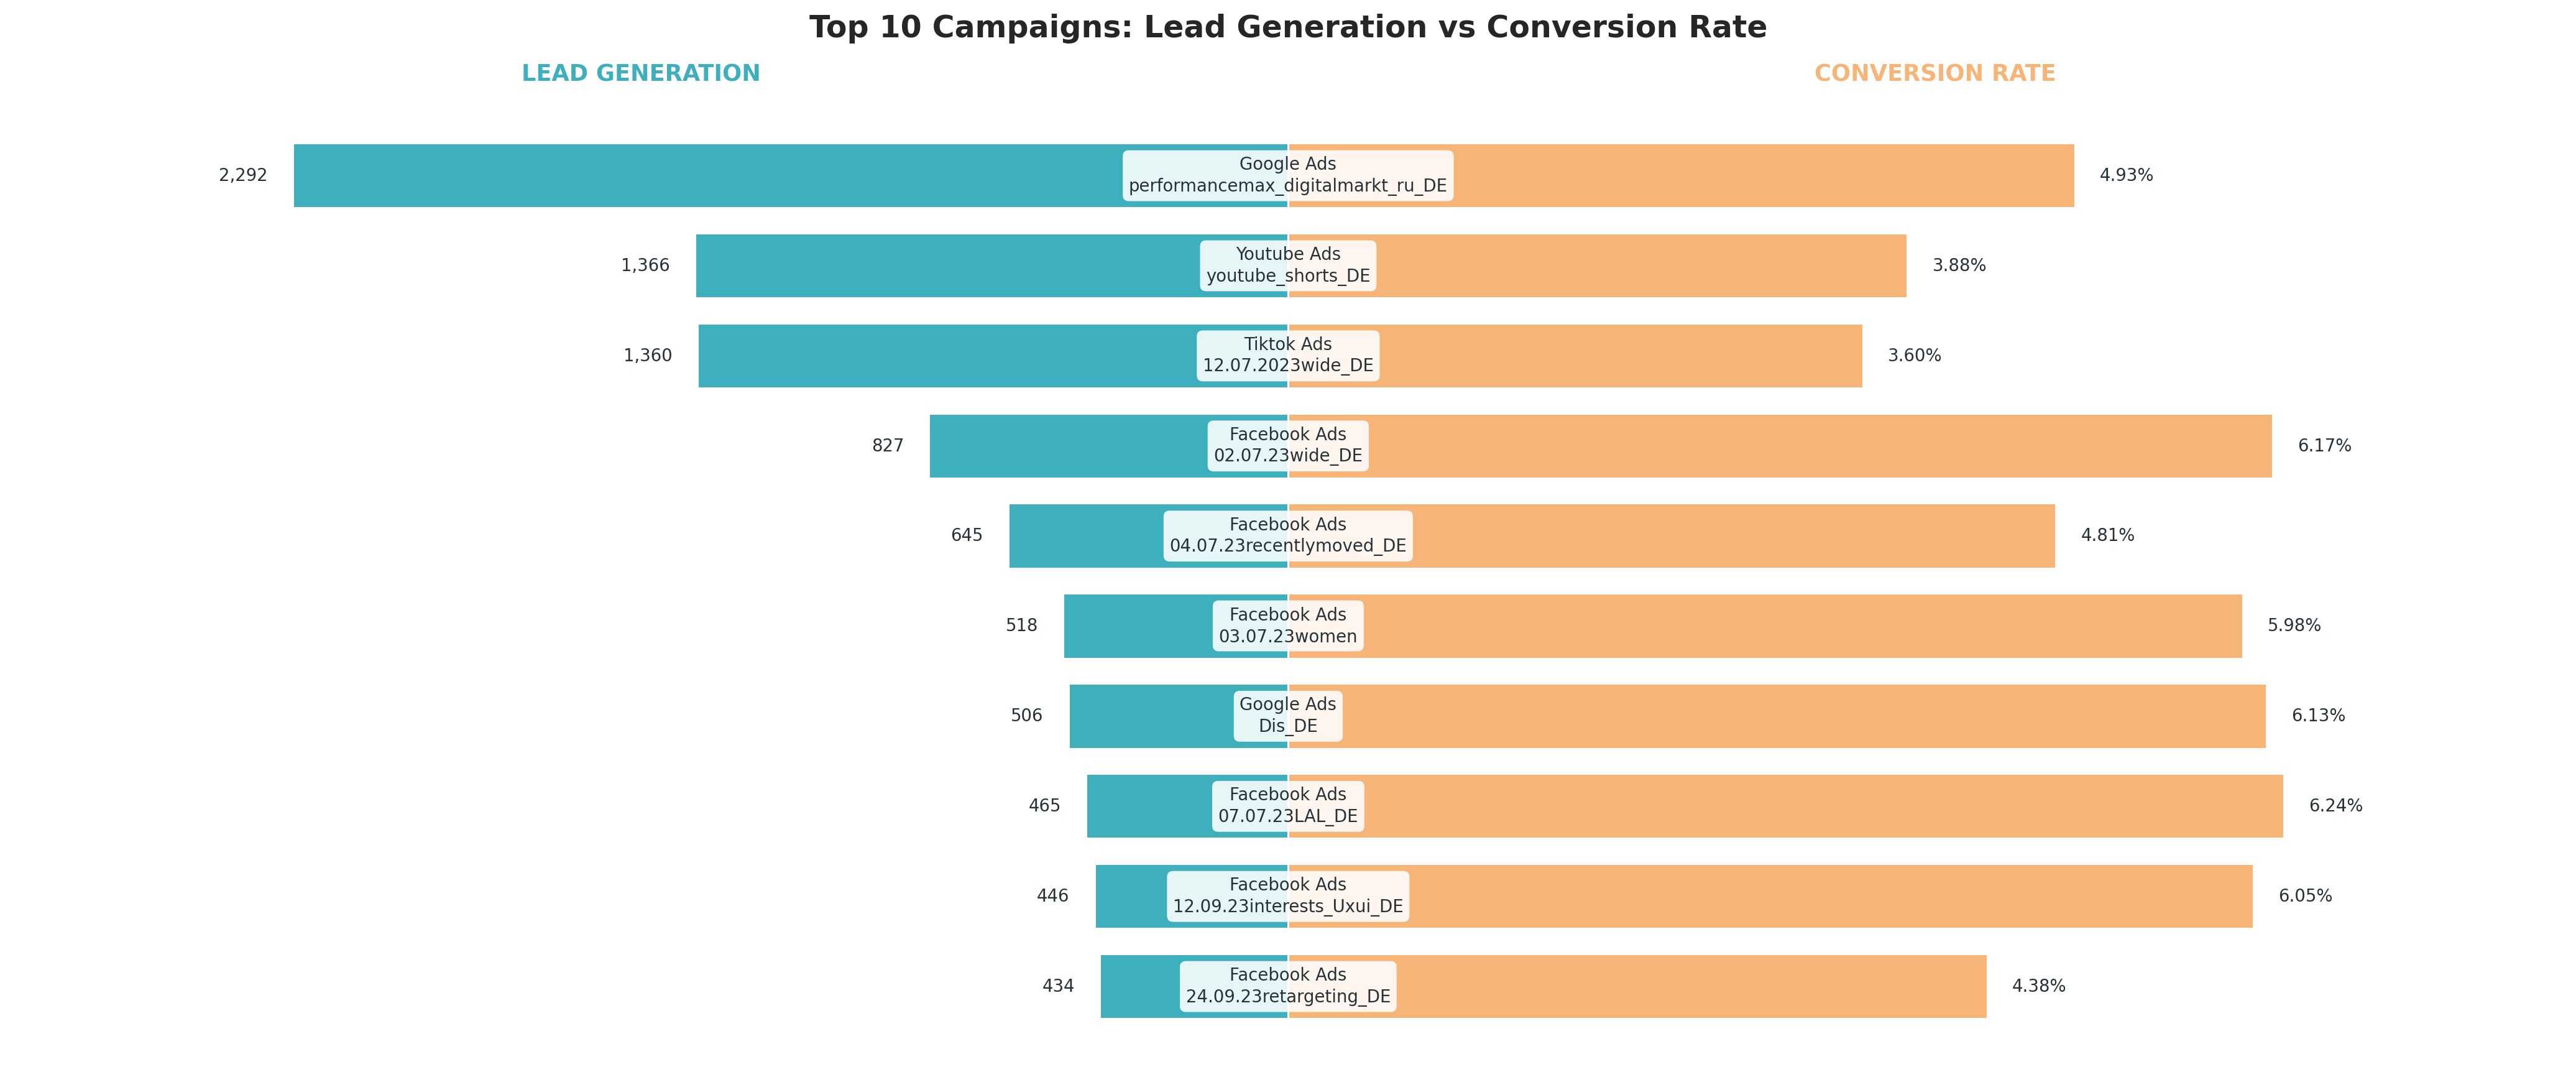

In [ ]:
y = np.arange(len(top_campaigns))

fig, ax = plt.subplots(figsize=(19, 8))

ax.barh(
    y,
    -lead_width,
    color=PRIMARY_COLOR,
    height=0.72
)

ax.barh(
    y,
    conversion_width,
    color=SECONDARY_COLOR,
    height=0.72
)

for i, (_, row) in enumerate(top_campaigns.iterrows()):
    ax.text(
        0,
        i,
        row["Campaign_Label"],
        ha="center",
        va="center",
        fontsize=9,
        fontweight="medium",
        linespacing=1.3,
        color="#263238",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.88,
            boxstyle="round,pad=0.35"
        ),
        zorder=5
    )

    ax.text(
        -lead_width.iloc[i] - 0.025,
        i,
        f'{row["Leads"]:,.0f}',
        ha="right",
        va="center",
        fontsize=9,
        color="#263238"
    )

    ax.text(
        conversion_width.iloc[i] + 0.025,
        i,
        f'{row["Conversion_Rate"]:.2f}%',
        ha="left",
        va="center",
        fontsize=9,
        color="#263238"
    )

ax.set_xlim(-1.28, 1.28)
ax.set_ylim(-0.8, len(top_campaigns) - 0.2)
ax.invert_yaxis()

ax.set_xticks([])
ax.set_yticks([])

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.text(
    -0.65,
    -1.05,
    "LEAD GENERATION",
    ha="center",
    fontsize=12,
    fontweight="bold",
    color=PRIMARY_COLOR
)

ax.text(
    0.65,
    -1.05,
    "CONVERSION RATE",
    ha="center",
    fontsize=12,
    fontweight="bold",
    color=SECONDARY_COLOR
)

ax.set_title(
    "Top 10 Campaigns: Lead Generation vs Conversion Rate",
    fontsize=16,
    fontweight="bold",
    pad=35
)

plt.tight_layout()
plt.show()

Conclusion


Google Ads (`performancemax_digitalmarkt_ru_DE`) clearly dominates in lead generation while maintaining a relatively strong conversion rate. However, several smaller Facebook Ads campaigns, particularly `07.07.23LAL_DE` and `02.07.23wide_DE`, demonstrate even higher conversion rates.

This suggests that campaigns generating fewer leads may attract a higher proportion of potential customers who eventually make a purchase. Therefore, high lead volume does not necessarily translate into higher conversion efficiency. Nevertheless, Google Ads compensates for its slightly lower conversion rate through a significantly larger lead volume, resulting in the highest absolute number of buyers among the analyzed campaigns. Both metrics should therefore be considered when evaluating campaign performance.

In [ ]:
quality_latest = (
    deals_sorted
    .dropna(subset=["Quality"])
    .drop_duplicates(subset=["Contact Name", "Product"], keep="last")
    [["Contact Name", "Product", "Quality"]]
    .rename(columns={"Quality": "Final_Quality"})
)

source_leads = (
    deals_selected
    .sort_values("Created Time", kind="stable")
    .drop_duplicates(subset=["Contact Name", "Product"], keep="last")
    [["Contact Name", "Product", "Source"]]
    .merge(
        quality_latest,
        on=["Contact Name", "Product"],
        how="left",
        validate="one_to_one"
    )
)

In [ ]:
quality_mapping = {
    "A - High": "Qualified",
    "B - Medium": "Qualified",
    "C - Low": "Low Quality",
    "D - Non Target": "Unqualified",
    "E - Non Qualified": "Unqualified"
}

source_leads["Quality_Group"] = (
    source_leads["Final_Quality"]
    .map(quality_mapping)
    .fillna("Not Rated")
)

In [ ]:
quality_order = [
    "Qualified",
    "Low Quality",
    "Unqualified",
    "Not Rated"
]

source_quality = (
    source_leads
    .groupby(["Source", "Quality_Group"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=quality_order, fill_value=0)
)

In [ ]:
source_quality["Total_Leads"] = source_quality[quality_order].sum(axis=1)
source_quality["Rated_Leads"] = (
    source_quality["Total_Leads"] - source_quality["Not Rated"]
)

source_quality["Qualified_Share"] = (
    source_quality["Qualified"]
    / source_quality["Rated_Leads"].replace(0, np.nan)
    * 100
)

In [ ]:
source_quality["Rating_Coverage"] = (
    source_quality["Rated_Leads"]
    / source_quality["Total_Leads"]
    * 100
)

source_quality = (
    source_quality
    .loc[
        (source_quality["Total_Leads"] >= 30)
        & (source_quality["Rated_Leads"] >= 30)
        & (source_quality["Rating_Coverage"] >= 30)
    ]
    .sort_values("Qualified_Share", ascending=False)
)


quality_percent = (
    source_quality[quality_order]
    .div(source_quality["Total_Leads"], axis=0)
    * 100
)

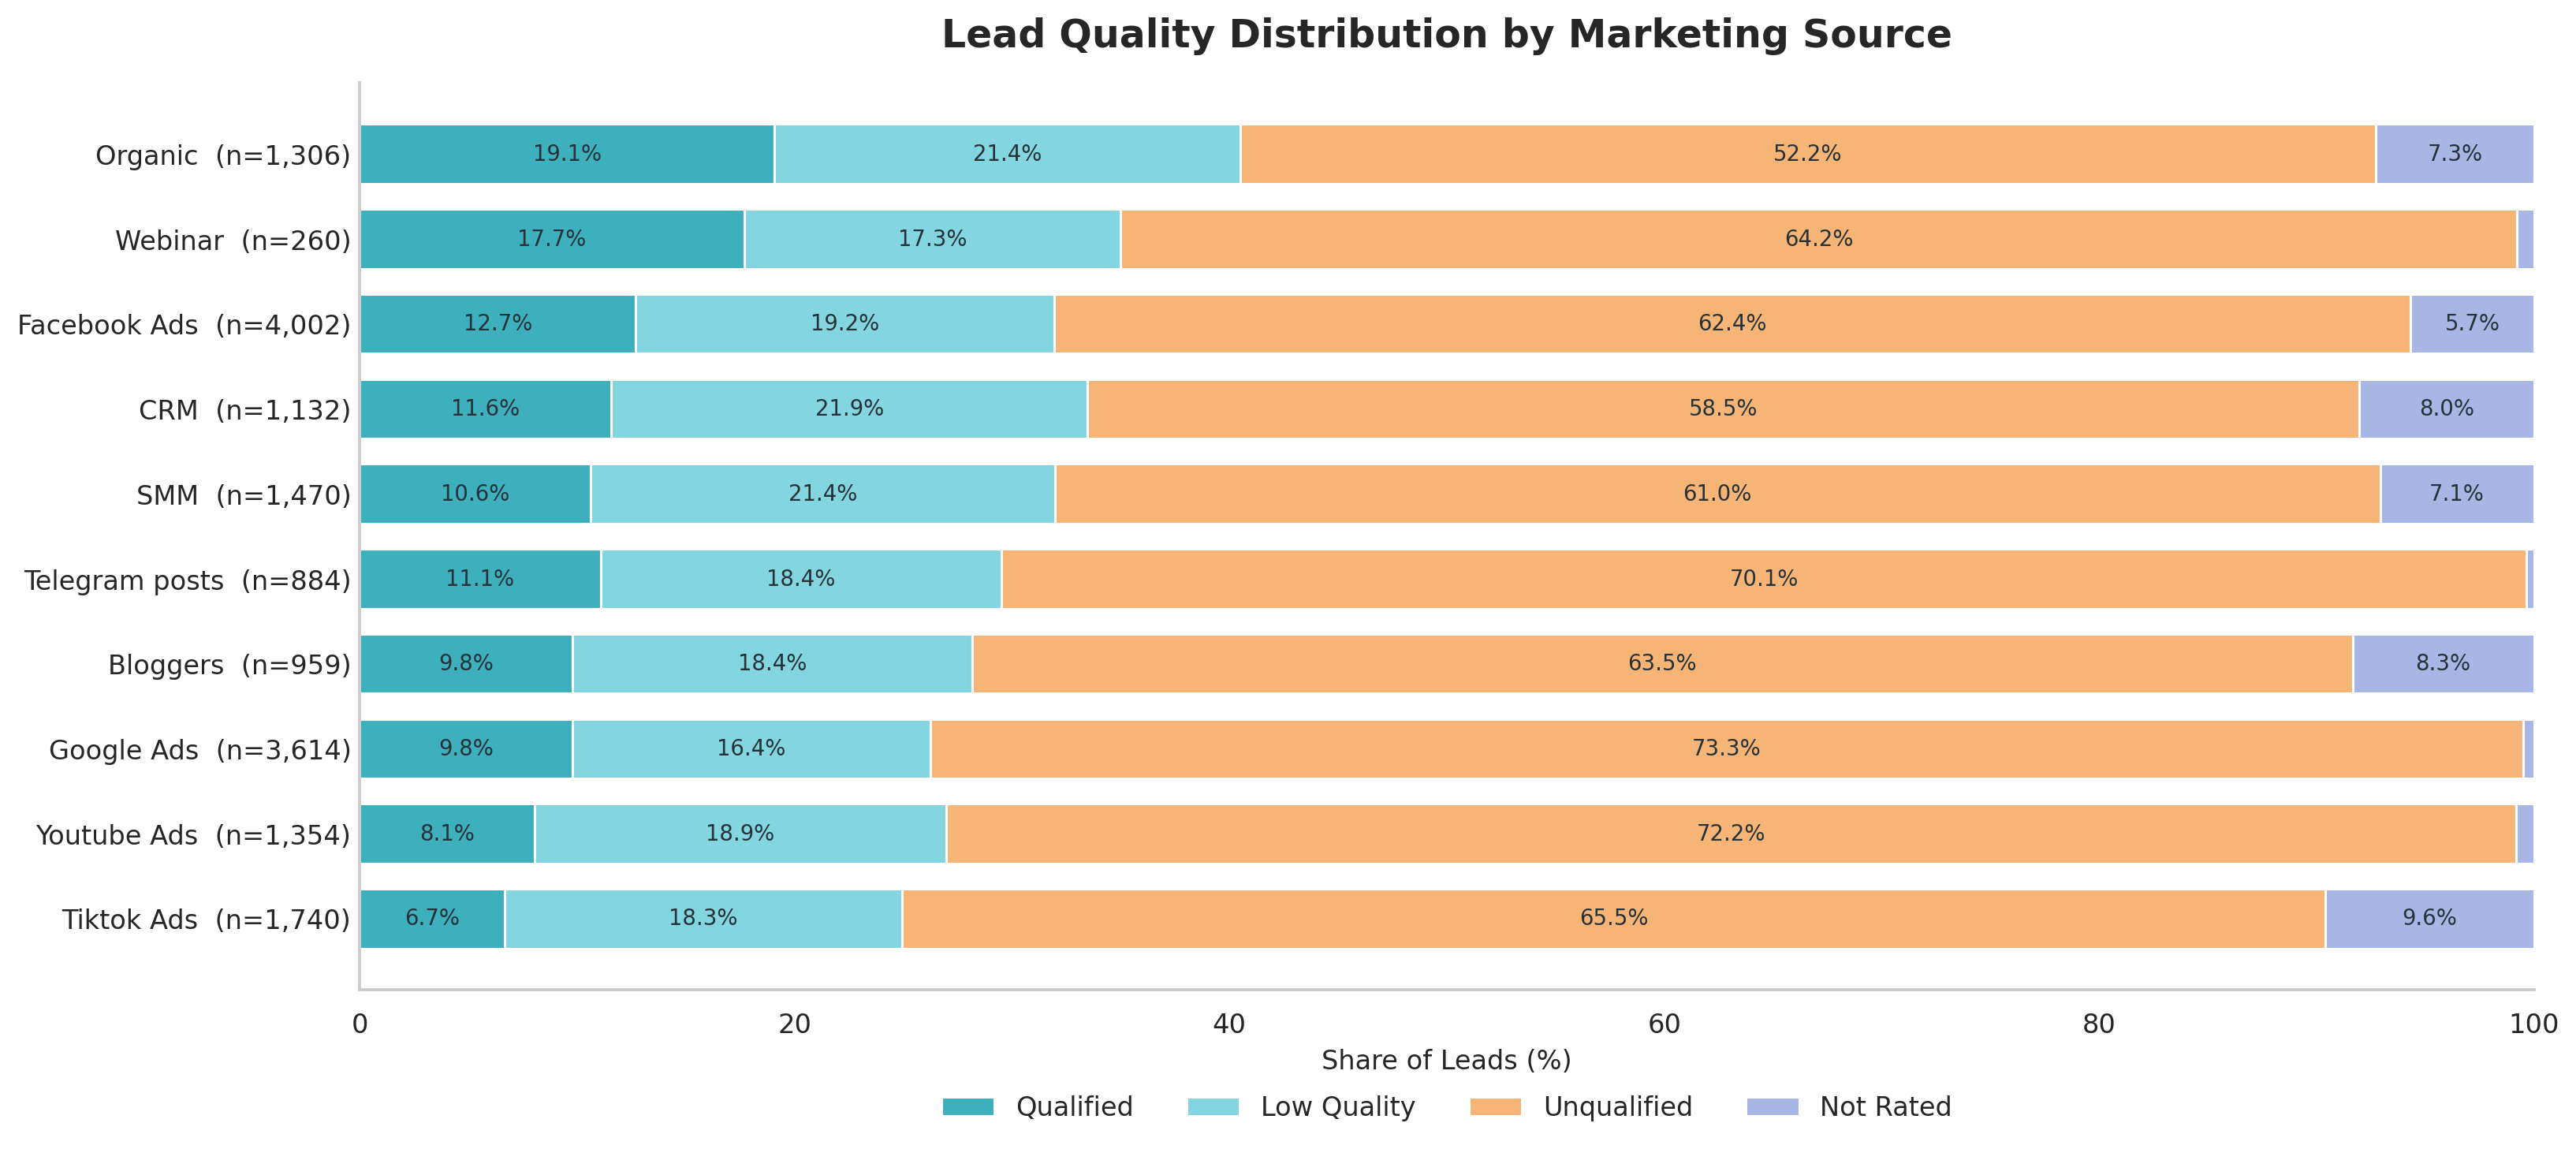

SOURCE QUALITY SUMMARY


Quality_Group,Qualified,Low Quality,Unqualified,Not Rated,Total_Leads,Rated_Leads,Qualified_Share
Source,,,,,,,
Organic,249,280,682,95,1306,1211,20.56
Webinar,46,45,167,2,260,258,17.83
Facebook Ads,508,770,2497,227,4002,3775,13.46
CRM,131,248,662,91,1132,1041,12.58
SMM,156,314,896,104,1470,1366,11.42
Telegram posts,98,163,620,3,884,881,11.12
Bloggers,94,176,609,80,959,879,10.69
Google Ads,354,594,2648,18,3614,3596,9.84
Youtube Ads,109,256,978,11,1354,1343,8.12


In [ ]:
quality_colors = [
    PRIMARY_COLOR,
    ACCENT_COLOR,
    SECONDARY_COLOR,
    NEUTRAL_COLOR
]

fig, ax = plt.subplots(
    figsize=(15, max(6, len(source_quality) * 0.48 + 2))
)

left = np.zeros(len(source_quality))
y = np.arange(len(source_quality))

for category, color in zip(quality_order, quality_colors):
    values = quality_percent[category].to_numpy()

    ax.barh(
        y,
        values,
        left=left,
        height=0.7,
        color=color,
        label=category
    )

    for i, value in enumerate(values):
        if value >= 5:
            ax.text(
                left[i] + value / 2,
                i,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=9,
                color="#263238"
            )

    left += values

ax.set_yticks(y)
ax.set_yticklabels(
    [
        f"{source}  (n={total:,})"
        for source, total in zip(
            source_quality.index,
            source_quality["Total_Leads"]
        )
    ]
)

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of Leads (%)")
ax.set_ylabel("")
ax.set_title(
    "Lead Quality Distribution by Marketing Source",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.09),
    ncol=4
)

ax.grid(False)
ax.tick_params(axis="y", length=0)

plt.tight_layout()
plt.show()

print("SOURCE QUALITY SUMMARY")
display(
    source_quality[
        quality_order + [
            "Total_Leads",
            "Rated_Leads",
            "Qualified_Share"
        ]
    ].round(2)
)

In [ ]:
payment_by_lead = (
    deals_selected
    .assign(Is_Paid=deals_selected["Stage"].eq("Payment Done"))
    .groupby(["Contact Name", "Product"], as_index=False)
    .agg(Paid_Lead=("Is_Paid", "max"))
)

quality_conversion = (
    source_leads
    .merge(
        payment_by_lead,
        on=["Contact Name", "Product"],
        how="left",
        validate="one_to_one"
    )
    .groupby("Quality_Group")
    .agg(
        Leads=("Contact Name", "size"),
        Buyers=("Paid_Lead", "sum")
    )
    .reindex(quality_order)
)

quality_conversion["Conversion_Rate"] = (
    quality_conversion["Buyers"]
    / quality_conversion["Leads"]
    * 100
).round(2)

print("LEAD QUALITY VS PAYMENT CONVERSION")
display(quality_conversion)

LEAD QUALITY VS PAYMENT CONVERSION


,Leads,Buyers,Conversion_Rate
Quality_Group,,,
Qualified,1864,459,24.62
Low Quality,3169,342,10.79
Unqualified,10918,39,0.36
Not Rated,930,0,0.00


Conclusion

**English**

The additional analysis of payment conversion by lead quality confirms a strong relationship between managers' quality assessments and actual purchases. Leads rated `A - High` or `B - Medium` have the highest conversion rate (24.62%), followed by `C - Low` (10.79%), while `D - Non Target` and `E - Non Qualified` rarely convert (0.36%). This indicates that although `Quality` is based on subjective managerial assessments, these ratings are generally consistent with actual customer behavior and can be used as a meaningful indicator of lead potential.

No purchases were recorded among leads without a `Quality` rating. These contacts may still be at an early stage of the sales process, or they may have exited before receiving an assessment.

**An important distinction in the calculations:** the 100% stacked bar chart shows each quality group's share of **all leads** from a source, including those without a `Quality` rating (`Not Rated`). In contrast, the `Qualified_Share` metric in the summary table is calculated using **only rated leads**, excluding missing assessments. This is intentional: unrated leads cannot automatically be classified as low-quality. At the same time, displaying `Not Rated` on the chart makes missing assessments visible and helps evaluate the completeness of the data. Sources with fewer than 30 rated leads, or a Quality assessment coverage below 30% were excluded from the visual comparison to ensure a more reliable evaluation.

The source analysis reveals several important differences:

- **Organic leads in quality share.** It has the highest proportion of `A + B` leads among rated contacts (20.56%), while also generating a substantial lead volume. This suggests that organic acquisition attracts a comparatively high proportion of promising potential customers.
- **Facebook Ads leads in the absolute number of qualified leads.** It generates the largest overall lead volume in the source-level analysis and the highest number of `A + B` leads (508). Although its qualified share is lower than Organic's, its considerably larger scale results in more qualified leads overall. Together with the relatively strong conversion rates observed for several Facebook campaigns in the earlier analysis, this indicates that Facebook Ads is an important source of both lead volume and promising customers.
- **Google Ads generates a large volume but a lower proportion of qualified leads.** It ranks among the largest sources by lead volume, consistent with the earlier campaign analysis, but its qualified share is noticeably lower than Organic's and Facebook Ads'. A substantial majority of its leads are classified as unqualified. Nevertheless, the earlier analysis showed that some Google Ads campaigns achieve reasonable lead-to-customer conversion rates, highlighting differences in performance between individual campaigns within the same source.
- **YouTube Ads and TikTok Ads have relatively low qualified shares.** Despite generating substantial lead volumes, they attract a smaller proportion of highly or moderately rated leads. This may indicate differences in audience targeting or lead intent, although the available data does not establish the causes.

Overall, the analysis shows that **lead volume, assessed lead quality, and actual conversion are related but distinct indicators of marketing performance**. Organic performs best in the proportion of qualified leads, Facebook Ads combines large-scale acquisition with the highest absolute number of qualified leads, and Google Ads demonstrates that high acquisition volume can coexist with a relatively low share of qualified leads. Evaluating these indicators together provides a more complete understanding of the effectiveness of different marketing sources.

In [ ]:
source_performance = (
    source_leads
    .merge(
        payment_by_lead,
        on=["Contact Name", "Product"],
        how="left",
        validate="one_to_one"
    )
    .groupby("Source", as_index=False)
    .agg(
        Leads=("Contact Name", "size"),
        Buyers=("Paid_Lead", "sum"),
        Qualified_Leads=("Quality_Group", lambda x: x.eq("Qualified").sum()),
        Rated_Leads=("Quality_Group", lambda x: x.ne("Not Rated").sum())
    )
)

source_spend = (
    spend
    .groupby("Source", as_index=False)
    .agg(AC=("Spend", "sum"))
)

In [ ]:
source_cost_performance = source_performance.merge(
    source_spend,
    on="Source",
    how="outer",
    validate="one_to_one",
    indicator=True
)

source_cost_performance["Conversion_Rate"] = (
    source_cost_performance["Buyers"]
    / source_cost_performance["Leads"]
    * 100
)

source_cost_performance["Qualified_Share"] = (
    source_cost_performance["Qualified_Leads"]
    / source_cost_performance["Rated_Leads"].replace(0, np.nan)
    * 100
)

source_cost_performance["CPA"] = (
    source_cost_performance["AC"]
    / source_cost_performance["Leads"].replace(0, np.nan)
)

source_cost_performance["CAC"] = (
    source_cost_performance["AC"]
    / source_cost_performance["Buyers"].replace(0, np.nan)
)

source_cost_performance = source_cost_performance.sort_values(
    "Leads", ascending=False, na_position="last"
).reset_index(drop=True)

In [ ]:
print("SOURCE MATCHING RESULTS")
display(source_cost_performance["_merge"].value_counts())

print("\nTOTAL SPEND:", f'€{spend["Spend"].sum():,.2f}')
print(
    "MATCHED SOURCE SPEND:",
    f'€{source_cost_performance.loc[source_cost_performance["_merge"].eq("both"), "AC"].sum():,.2f}'
)

SOURCE MATCHING RESULTS


,count
_merge,
both,12
right_only,1
left_only,0



TOTAL SPEND: €148,915.24
MATCHED SOURCE SPEND: €148,615.24


In [ ]:
paid_sources = (
    source_cost_performance.loc[
        (source_cost_performance["_merge"] == "both")
        & (source_cost_performance["AC"] > 0)
        & (source_cost_performance["Leads"] > 0)
        & (source_cost_performance["Buyers"] > 0)
    ]
    .sort_values("CAC")
    .reset_index(drop=True)
)

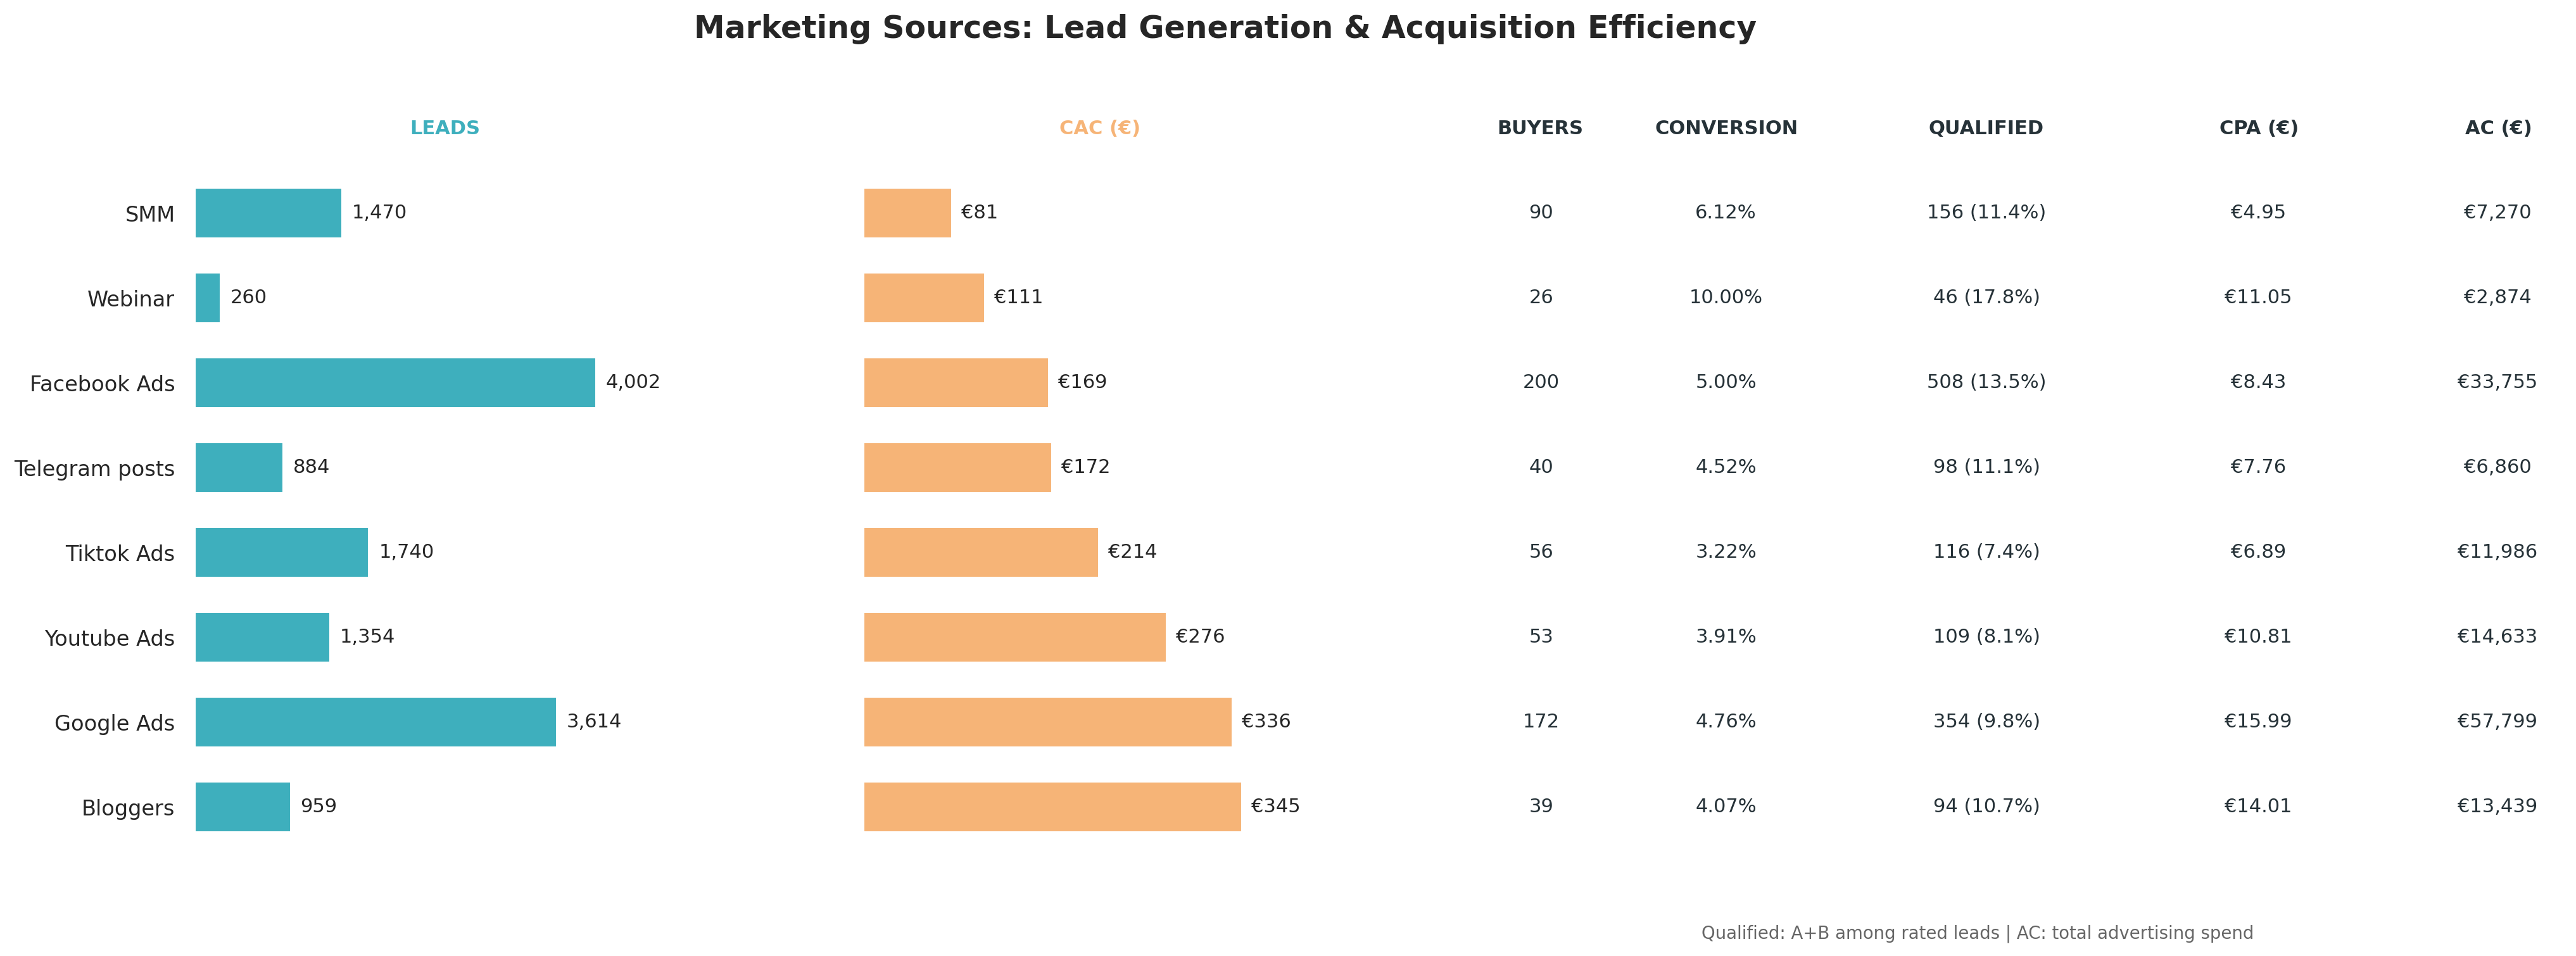

In [ ]:
fig = plt.figure(figsize=(20, 7.5))

ax_leads = fig.add_axes([0.13, 0.16, 0.18, 0.65])
ax_cac = fig.add_axes([0.37, 0.16, 0.17, 0.65], sharey=ax_leads)
ax_metrics = fig.add_axes([0.59, 0.16, 0.39, 0.65], sharey=ax_leads)

y = np.arange(len(paid_sources))

ax_leads.barh(
    y,
    paid_sources["Leads"],
    color=PRIMARY_COLOR,
    height=0.6
)

ax_cac.barh(
    y,
    paid_sources["CAC"],
    color=SECONDARY_COLOR,
    height=0.6
)

ax_leads.set_xlim(0, paid_sources["Leads"].max() * 1.25)
ax_cac.set_xlim(0, paid_sources["CAC"].max() * 1.25)

ax_leads.set_yticks(y)
ax_leads.set_yticklabels(paid_sources["Source"], fontsize=11)

ax_leads.set_ylim(len(paid_sources) - 0.5, -0.5)

for i, row in paid_sources.iterrows():
    ax_leads.text(
        row["Leads"] + paid_sources["Leads"].max() * 0.025,
        i,
        f'{row["Leads"]:,.0f}',
        va="center",
        fontsize=10
    )

    ax_cac.text(
        row["CAC"] + paid_sources["CAC"].max() * 0.025,
        i,
        f'€{row["CAC"]:,.0f}',
        va="center",
        fontsize=10
    )

    values = [
        f'{row["Buyers"]:,.0f}',
        f'{row["Conversion_Rate"]:.2f}%',
        f'{row["Qualified_Leads"]:,.0f} ({row["Qualified_Share"]:.1f}%)',
        f'€{row["CPA"]:,.2f}',
        f'€{row["AC"]:,.0f}'
    ]

    for x, value in zip([0.06, 0.23, 0.47, 0.72, 0.94], values):
        ax_metrics.text(
            x, i, value,
            transform=ax_metrics.get_yaxis_transform(),
            ha="center",
            va="center",
            fontsize=10,
            color="#263238"
        )

for ax in [ax_leads, ax_cac, ax_metrics]:
    ax.grid(False)
    ax.tick_params(axis="x", bottom=False, labelbottom=False)
    ax.spines[["top", "right", "bottom", "left"]].set_visible(False)

ax_leads.tick_params(axis="y", length=0, pad=10)
ax_cac.tick_params(axis="y", left=False, labelleft=False)
ax_metrics.tick_params(axis="y", left=False, labelleft=False)
ax_metrics.set_xlim(0, 1)
ax_metrics.set_xticks([])

fig.suptitle(
    "Marketing Sources: Lead Generation & Acquisition Efficiency",
    fontsize=16,
    fontweight="bold",
    y=0.96
)

headers = [
    (0.22, "LEADS", PRIMARY_COLOR),
    (0.455, "CAC (€)", SECONDARY_COLOR),
    (0.613, "BUYERS", "#263238"),
    (0.68, "CONVERSION", "#263238"),
    (0.773, "QUALIFIED", "#263238"),
    (0.871, "CPA (€)", "#263238"),
    (0.957, "AC (€)", "#263238")
]

for x, label, color in headers:
    fig.text(
        x, 0.845, label,
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=color
    )

fig.text(
    0.77, 0.075,
    "Qualified: A+B among rated leads | AC: total advertising spend",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.show()

In [ ]:
lead_first_dates = (
    deals_sorted
    .groupby(["Contact Name", "Product"], as_index=False)
    .agg(First_Deal_Time=("Created Time", "min"))
)

In [ ]:
source_leads_time = (
    source_leads
    .merge(
        lead_first_dates,
        on=["Contact Name", "Product"],
        how="left",
        validate="one_to_one"
    )
    .dropna(subset=["First_Deal_Time", "Source"])
    .copy()
)

source_leads_time["Lead_Month"] = (
    source_leads_time["First_Deal_Time"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

In [ ]:
top_6_sources = (
    source_performance
    .sort_values("Leads", ascending=False)["Source"]
    .head(6)
    .tolist()
)

monthly_leads = (
    source_leads_time.loc[source_leads_time["Source"].isin(top_6_sources)]
    .groupby(["Lead_Month", "Source"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

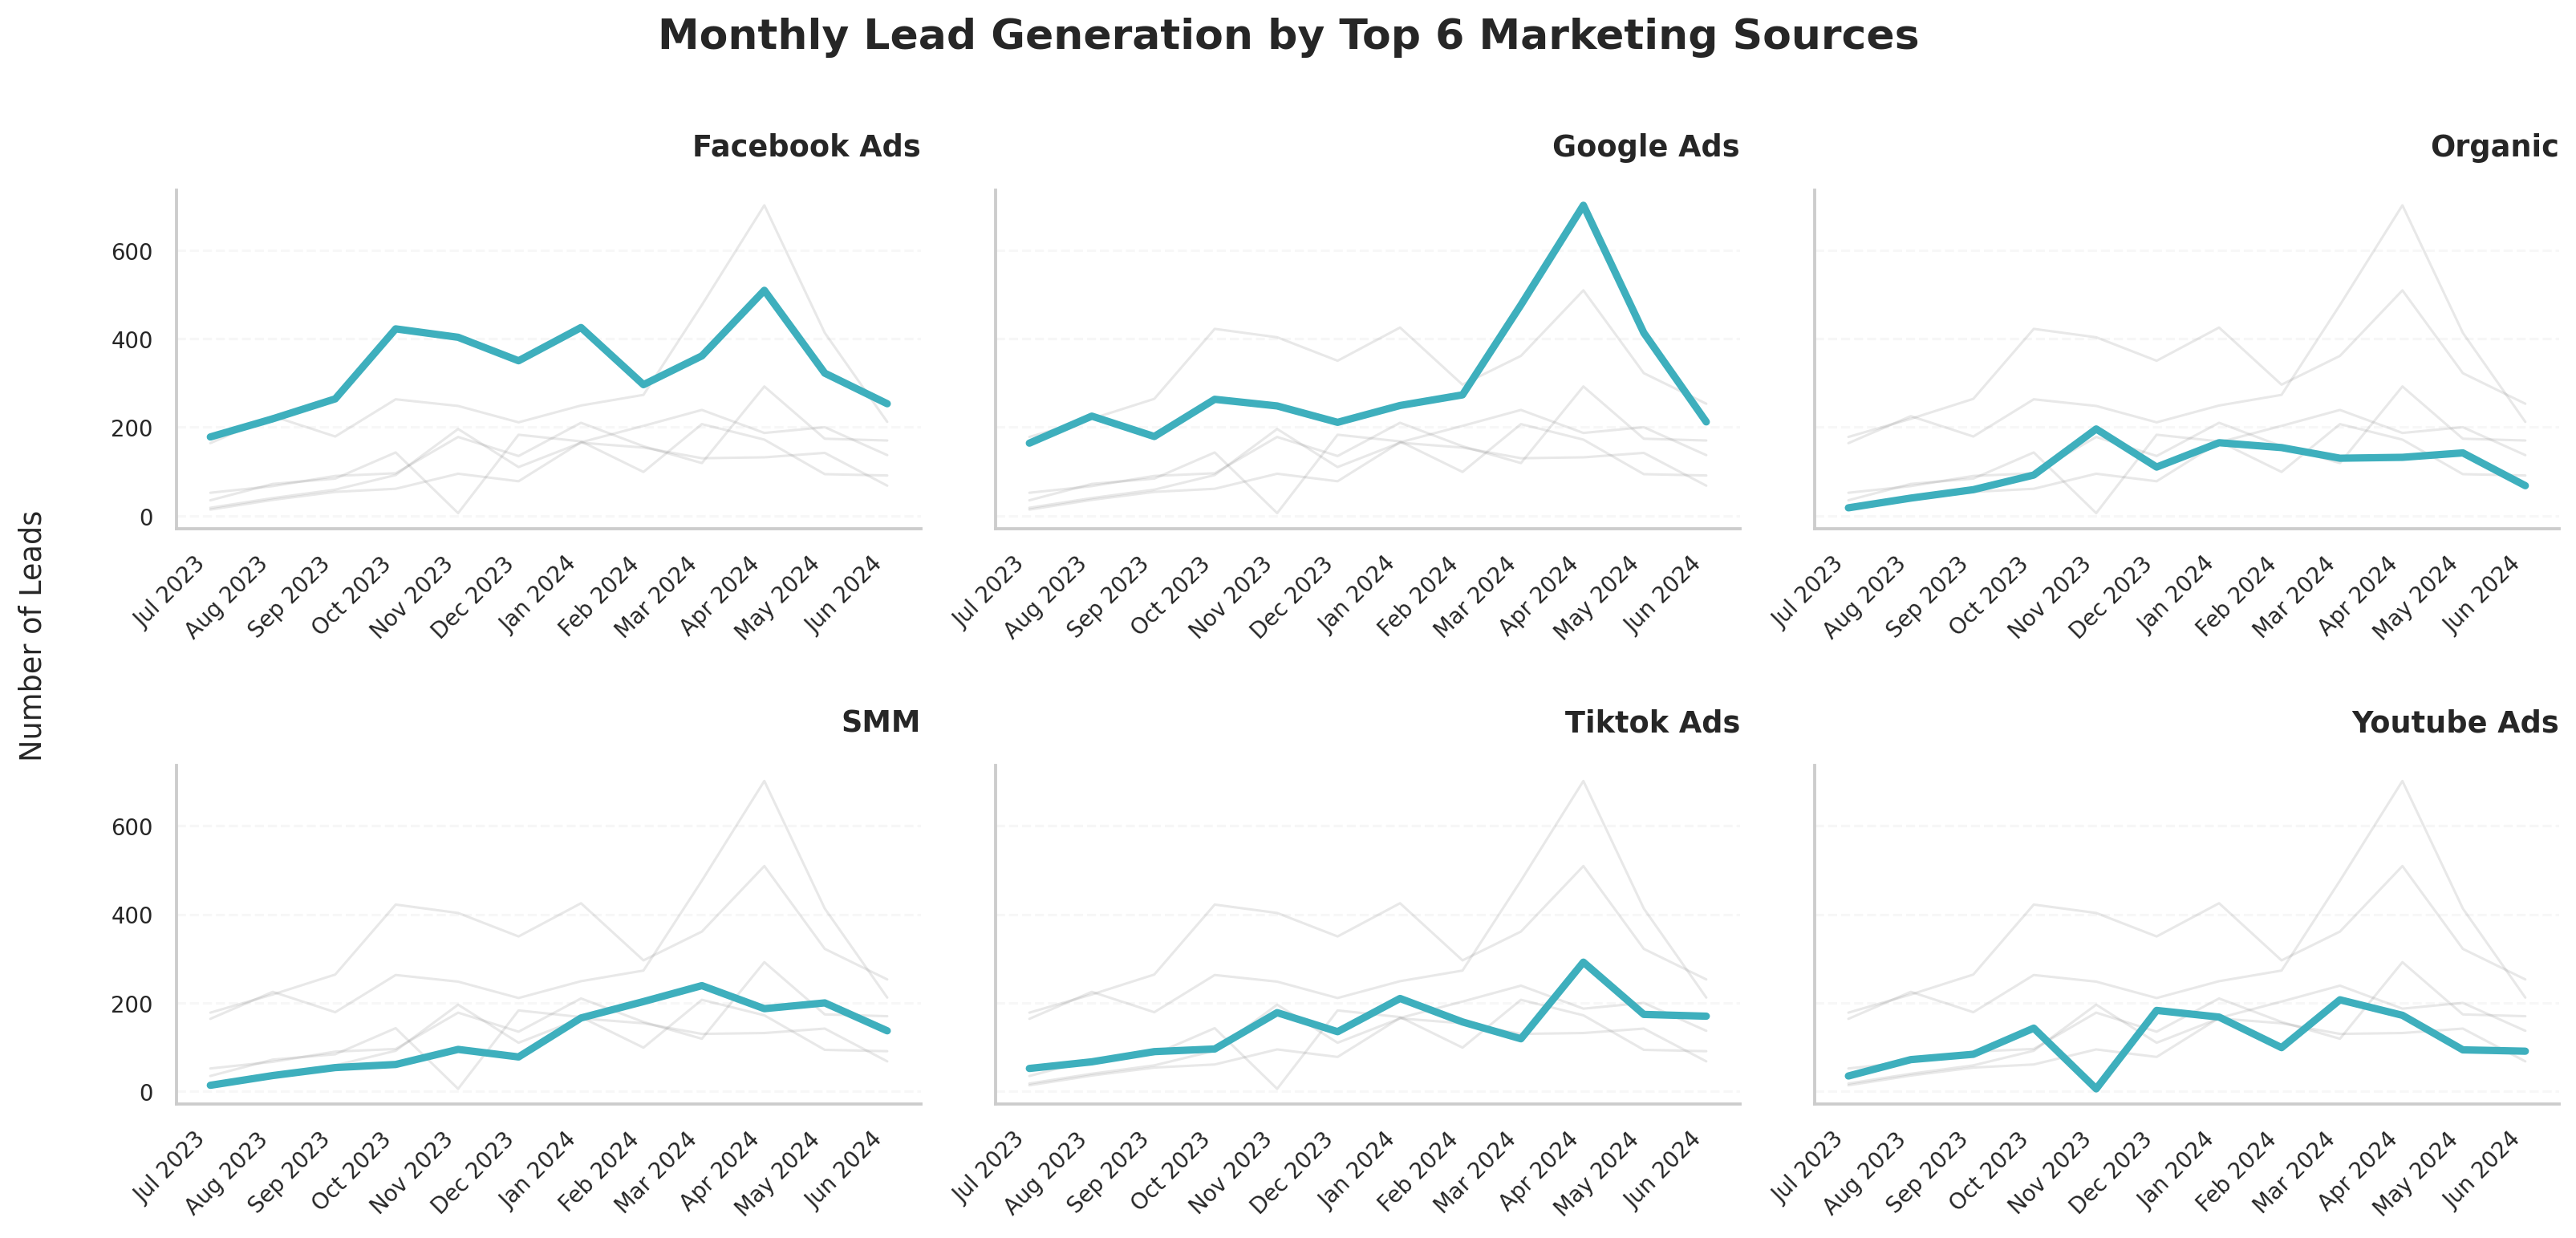

In [ ]:
n_cols = 3
n_rows = int(np.ceil(len(monthly_leads.columns) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 7),
    sharex=True,
    sharey=True
)

axes = np.array(axes).flatten()

for ax, source in zip(axes, monthly_leads.columns):
    for other_source in monthly_leads.columns:
        if other_source != source:
            ax.plot(
                monthly_leads.index,
                monthly_leads[other_source],
                color="gray",
                alpha=0.18,
                linewidth=1.0,
                zorder=1
            )

    ax.plot(
        monthly_leads.index,
        monthly_leads[source],
        color=PRIMARY_COLOR,
        linewidth=3,
        zorder=3
    )

    ax.set_title(
        source,
        fontsize=12,
        fontweight="bold",
        loc="right",
        pad=14
    )

    ax.grid(axis="y", alpha=0.15, linestyle="--")
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="both", labelsize=9)

for ax in axes[len(monthly_leads.columns):]:
    ax.set_visible(False)

for ax in axes[:len(monthly_leads.columns)]:
    ax.set_xticks(monthly_leads.index)
    ax.set_xticklabels(
        [date.strftime("%b %Y") for date in monthly_leads.index],
        rotation=45,
        ha="right"
    )
    ax.tick_params(axis="x", labelbottom=True)

fig.suptitle(
    "Monthly Lead Generation by Top 6 Marketing Sources",
    fontsize=17,
    fontweight="bold",
    y=1.0
)

fig.supylabel("Number of Leads", fontsize=12, x=0.02)

fig.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.86,
    bottom=0.12,
    wspace=0.10,
    hspace=0.7
)

plt.show()

Conclusion


Advertising expenses were matched to marketing sources almost completely: €148,615.24 out of €148,915.24. The analysis focuses on sources with recorded advertising costs and measurable acquisition results. Sources with zero recorded advertising spend were excluded from the financial comparison, as this does not necessarily mean that customer acquisition was free.

**SMM demonstrates the lowest CAC among paid sources** while maintaining a relatively strong conversion rate and attracting a substantial number of leads. Webinar also performs well, combining a high conversion rate with a comparatively low CAC. However, its smaller lead volume suggests that these results should be interpreted in the context of its limited scale.

**Facebook Ads demonstrates the strongest balance between acquisition volume and cost efficiency.** It generates the highest number of leads and buyers among paid sources, as well as the largest absolute number of qualified leads. Compared with Google Ads, Facebook Ads achieves slightly higher conversion and a higher qualified lead share, while its CAC is approximately half as high.

**Google Ads, despite its substantial lead volume, shows significantly weaker cost efficiency.** It accounts for the highest advertising expenditure but generates fewer buyers than Facebook Ads, with a lower qualified lead share and a considerably higher CAC. This suggests that the large scale of Google Ads does not translate into proportionally strong acquisition results.

TikTok Ads attracts leads at a relatively low CPA, but its higher CAC and lower conversion indicate that inexpensive leads do not necessarily result in inexpensive customers. YouTube Ads and Bloggers also demonstrate relatively high acquisition costs, making them less attractive from a CAC perspective.

**The monthly lead generation analysis** reveals additional differences in acquisition dynamics. Facebook Ads maintains consistently high lead volumes, with notable peaks in October 2023 and April 2024. Google Ads shows a particularly sharp increase in April 2024, reaching the highest monthly lead volume among the six sources. SMM demonstrates gradual growth into early 2024, while TikTok Ads shows more pronounced fluctuations, including a peak in April 2024. Organic grows during the second half of 2023 before stabilizing at a moderate level, whereas YouTube Ads exhibits a less consistent monthly pattern. These trends highlight differences in acquisition stability and fluctuations over time.

Overall, the combined analysis of campaign performance, lead quality, and acquisition costs shows that **high lead volume alone is not a sufficient indicator of marketing effectiveness**. Facebook Ads offers a particularly strong combination of scale, lead quality, and acquisition cost efficiency, while SMM stands out for its low CAC. These results highlight the importance of evaluating marketing sources using several complementary metrics rather than relying on lead volume or conversion alone.

# 4. Sales Department Performance

## 4.1. Sales Managers Performance

In [ ]:
manager_performance = (
    deals
    .assign(
        Owner=deals["Deal Owner Name"],
        Is_Paid=deals["Stage"].eq("Payment Done"),
        Sales_Amount=deals["Offer Total Amount"].where(
            deals["Stage"].eq("Payment Done"), 0
        )
    )
    .groupby("Owner", as_index=False)
    .agg(
        Total_Deals=("Id", "size"),
        Paid_Deals=("Is_Paid", "sum"),
        Total_Sales=("Sales_Amount", "sum")
    )
)

In [ ]:
manager_performance["Conversion_Rate"] = (
    manager_performance["Paid_Deals"]
    / manager_performance["Total_Deals"]
    * 100
).round(2)

manager_performance = manager_performance.sort_values(
    "Total_Deals", ascending=False
).reset_index(drop=True)

print("TOTAL MANAGERS:", manager_performance["Owner"].ne("Unknown").sum())
print("TOTAL DEALS:", manager_performance["Total_Deals"].sum())
print("TOTAL PAID DEALS:", manager_performance["Paid_Deals"].sum())
print("TOTAL CONTRACTED SALES:", f'€{manager_performance["Total_Sales"].sum():,.2f}')

TOTAL MANAGERS: 27
TOTAL DEALS: 19610
TOTAL PAID DEALS: 842
TOTAL CONTRACTED SALES: €6,257,600.00


In [ ]:
managers_plot = (
    manager_performance.loc[
        (manager_performance["Owner"] != "Unknown")
        & (manager_performance["Total_Deals"] >= 30)
    ]
    .copy()
)

avg_conversion = managers_plot["Conversion_Rate"].mean()
max_sales = managers_plot["Total_Sales"].max()

In [ ]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=managers_plot["Total_Deals"],
        y=managers_plot["Conversion_Rate"],
        mode="markers",
        marker=dict(
            size=managers_plot["Total_Sales"],
            sizemode="area",
            sizeref=2 * max_sales / 55**2,
            sizemin=8,
            color=managers_plot["Paid_Deals"],
            colorscale=[
                [0.0, COLORS["pale_aqua"]],
                [0.5, ACCENT_COLOR],
                [1.0, PRIMARY_COLOR]
            ],
            opacity=0.85,
            line=dict(color="white", width=1.5),
            colorbar=dict(
                title="Paid Deals",
                thickness=14,
                len=0.65,
                y=0.5
            )
        ),
        customdata=managers_plot[
            ["Owner", "Paid_Deals", "Total_Sales"]
        ].to_numpy(),
        hovertemplate=(
            "<b>%{customdata[0]}</b>"
            "<br>Total Deals: %{x:,}"
            "<br>Paid Deals: %{customdata[1]:,}"
            "<br>Conversion Rate: %{y:.2f}%"
            "<br>Total Sales: €%{customdata[2]:,.0f}"
            "<extra></extra>"
        )
    )
)

fig.add_hline(
    y=avg_conversion,
    line_dash="dash",
    line_color=SECONDARY_COLOR,
    line_width=2,
    annotation_text=f"Average conversion: {avg_conversion:.2f}%",
    annotation_position="top left",
    annotation_font=dict(size=11, color="#404B52")
)

fig.update_layout(
    title=dict(
        text="<b>Sales Managers: Deal Volume, Conversion, Paid Deals & Total Sales</b>",
        x=0.5,
        xanchor="center",
        y=0.91,
        font=dict(size=17, color="#263238")
    ),
    xaxis_title="Total Deals",
    yaxis_title="Conversion Rate (%)",
    template="plotly_white",
    height=720,
    width=1500,
    showlegend=False,
    margin=dict(l=80, r=100, t=110, b=80),
    font=dict(size=12, color="#404B52"),
    plot_bgcolor="white",
    paper_bgcolor="white"
)

fig.update_xaxes(
    range=[0, managers_plot["Total_Deals"].max() * 1.08],
    dtick=250,
    tick0=0,
    showgrid=True,
    gridcolor="rgba(64, 75, 82, 0.12)",
    gridwidth=1,
    zeroline=False
)

fig.update_yaxes(
    range=[0, managers_plot["Conversion_Rate"].max() * 1.12],
    dtick=5,
    showgrid=True,
    gridcolor="rgba(64, 75, 82, 0.12)",
    gridwidth=1,
    zeroline=False
)

fig.show()

In [ ]:
top_volume = manager_performance.nlargest(5, "Total_Deals")

top_conversion = (
    manager_performance.loc[
        (manager_performance["Owner"] != "Unknown")
        & (manager_performance["Total_Deals"] >= 30)
    ]
    .nlargest(1, "Conversion_Rate")
)

low_conversion = (
    manager_performance.loc[
        (manager_performance["Owner"] != "Unknown")
        & (manager_performance["Total_Deals"] >= 900)
    ]
    .nsmallest(1, "Conversion_Rate")
)

In [ ]:
selected_owners = (
    pd.concat([top_volume, top_conversion, low_conversion])["Owner"]
    .drop_duplicates()
)

selected_deals = deals.loc[
    deals["Deal Owner Name"].isin(selected_owners)
].copy()

In [ ]:
source_counts = pd.crosstab(
    selected_deals["Deal Owner Name"],
    selected_deals["Source"].fillna("Unknown")
).reindex(selected_owners)

source_counts = source_counts[
    source_counts.sum().sort_values(ascending=False).index
]

In [ ]:
source_percent = source_counts.div(
    source_counts.sum(axis=1), axis=0
).mul(100)

source_labels = source_percent.map(
    lambda value: f"{value:.1f}%" if value >= 3 else ""
)

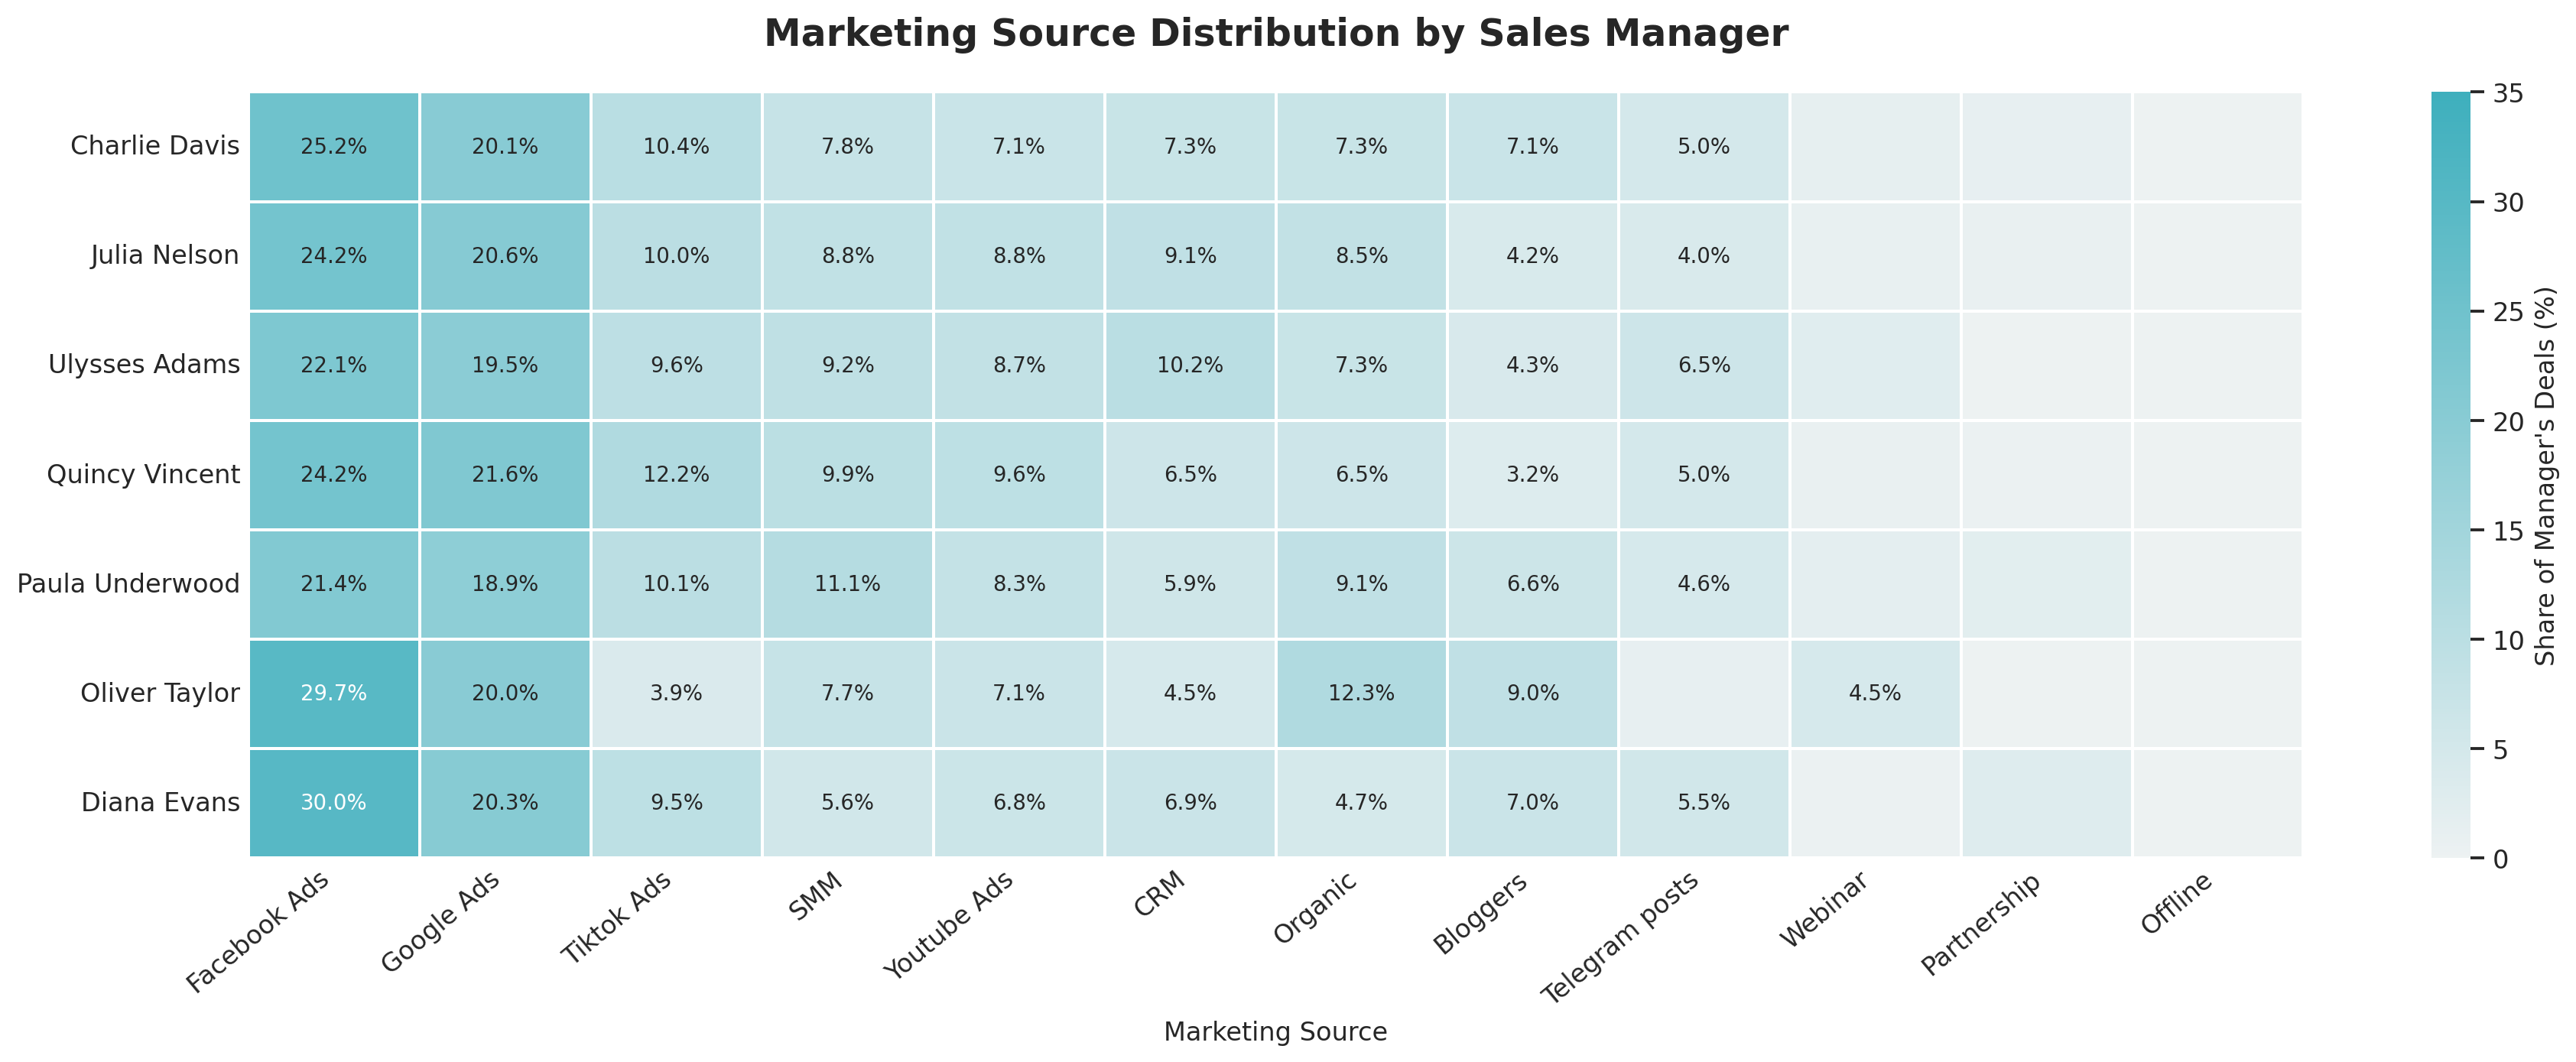

In [ ]:
fig, ax = plt.subplots(figsize=(17, 6.5))

sns.heatmap(
    source_percent,
    annot=source_labels,
    fmt="",
    cmap=HEATMAP_CMAP,
    vmin=0,
    vmax=35,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Share of Manager's Deals (%)"},
    annot_kws={"fontsize": 9},
    ax=ax
)

ax.set_title(
    "Marketing Source Distribution by Sales Manager",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Marketing Source")
ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
ax.tick_params(axis="both", length=0)

plt.tight_layout()
plt.show()

Conclusion


The analysis reveals substantial differences in sales managers' performance. Charlie Davis, Ulysses Adams, and Julia Nelson handle the largest deal volumes, with Charlie Davis and Ulysses Adams also generating the highest total contracted sales. Ulysses Adams achieves a higher conversion rate than the other high-volume managers, suggesting a stronger balance between workload and sales results.

Oliver Taylor stands out with an exceptionally high conversion rate (32.26%) despite handling considerably fewer deals. In contrast, Diana Evans processes a substantial number of deals but has an extremely low conversion rate (0.11%). These differences warrant further investigation rather than an immediate conclusion about individual employee performance.

The Heatmap shows that the five highest-volume managers work with relatively similar distributions of marketing sources, particularly Facebook Ads and Google Ads. Oliver Taylor and Diana Evans also receive comparable proportions of deals from these two major sources. Although Oliver has a higher share of Organic deals and a lower share of TikTok Ads deals, these differences alone do not adequately explain the substantial gap in conversion rates.

Overall, **the distribution of marketing sources does not provide a sufficient explanation for the differences in managers' performance**. Other factors, such as lead readiness, deal assignment practices, and response times, may also play a role.

In [ ]:
sla = deals["SLA Seconds"]

sla_quartiles = sla.quantile([0, 0.25, 0.50, 0.75, 1.00])

print("SLA OVERVIEW")
print("TOTAL DEALS:", len(deals))
print("DEALS WITH SLA:", sla.notna().sum())
print("DEALS WITHOUT SLA:", sla.isna().sum())

print("\nSLA DISTRIBUTION (SECONDS)")
display(sla.describe())

print("\nSLA QUARTILES")
display(
    pd.DataFrame({
        "Seconds": sla_quartiles,
        "Hours": sla_quartiles / 3600,
        "Readable Time": sla_quartiles.apply(
            lambda value: str(pd.Timedelta(seconds=value))
        )
    }).round(2)
)

SLA OVERVIEW
TOTAL DEALS: 19610
DEALS WITH SLA: 14814
DEALS WITHOUT SLA: 4796

SLA DISTRIBUTION (SECONDS)


,SLA Seconds
count,1.481400e+04
mean,1.120312e+05
std,7.302550e+05
min,3.000000e+00
25%,4.392000e+03
50%,1.974900e+04
75%,5.581375e+04
max,2.690846e+07



SLA QUARTILES


,Seconds,Hours,Readable Time
0.00,3.00,0.00,0 days 00:00:03
0.25,4392.00,1.22,0 days 01:13:12
0.50,19749.00,5.49,0 days 05:29:09
0.75,55813.75,15.50,0 days 15:30:13.750000
1.00,26908464.00,7474.57,311 days 10:34:24


In [ ]:
sla_bins = [
    -np.inf,
    sla_quartiles.loc[0.25],
    sla_quartiles.loc[0.50],
    sla_quartiles.loc[0.75],
    np.inf
]

sla_labels = [
    "Q1 | ≤ 1h 13m",
    "Q2 | 1h 13m – 5h 29m",
    "Q3 | 5h 29m – 15h 30m",
    "Q4 | > 15h 30m"
]

In [ ]:
manager_sla = deals[[
    "Deal Owner Name",
    "SLA Seconds"
]].copy()

manager_sla["SLA_Group"] = pd.cut(
    manager_sla["SLA Seconds"],
    bins=sla_bins,
    labels=sla_labels,
    include_lowest=True
)

In [ ]:
sla_counts = pd.crosstab(
    manager_sla["Deal Owner Name"],
    manager_sla["SLA_Group"]
).reindex(
    index=manager_performance["Owner"],
    columns=sla_labels,
    fill_value=0
)

In [ ]:
sla_known = sla_counts.sum(axis=1)

manager_totals = (
    manager_performance
    .set_index("Owner")["Total_Deals"]
    .reindex(sla_counts.index)
)

sla_missing = manager_totals - sla_known

sla_percent = (
    sla_counts
    .div(sla_known.replace(0, np.nan), axis=0)
    .mul(100)
)

In [ ]:
top_volume = manager_performance.nlargest(5, "Total_Deals")

top_conversion = (
    manager_performance.loc[
        (manager_performance["Owner"] != "Unknown")
        & (manager_performance["Total_Deals"] >= 30)
    ]
    .nlargest(1, "Conversion_Rate")
)

low_conversion = (
    manager_performance.loc[
        (manager_performance["Owner"] != "Unknown")
        & (manager_performance["Total_Deals"] >= 900)
    ]
    .nsmallest(1, "Conversion_Rate")
)

selected_owners = (
    pd.concat([top_volume, top_conversion, low_conversion])["Owner"]
    .drop_duplicates()
)

In [ ]:
sla_bins = [
    -np.inf,
    sla_quartiles.loc[0.25],
    sla_quartiles.loc[0.50],
    sla_quartiles.loc[0.75],
    np.inf
]

sla_labels = [
    "Q1 | ≤ 1h 13m",
    "Q2 | 1h 13m – 5h 29m",
    "Q3 | 5h 29m – 15h 30m",
    "Q4 | > 15h 30m"
]

manager_sla = deals[[
    "Deal Owner Name",
    "SLA Seconds"
]].copy()

manager_sla["SLA_Group"] = pd.cut(
    manager_sla["SLA Seconds"],
    bins=sla_bins,
    labels=sla_labels,
    include_lowest=True
)

sla_counts = pd.crosstab(
    manager_sla["Deal Owner Name"],
    manager_sla["SLA_Group"]
).reindex(
    index=manager_performance["Owner"],
    columns=sla_labels,
    fill_value=0
)

sla_known = sla_counts.sum(axis=1)

manager_totals = (
    manager_performance
    .set_index("Owner")["Total_Deals"]
    .reindex(sla_counts.index)
)

sla_missing = manager_totals - sla_known

sla_percent = (
    sla_counts
    .div(sla_known.replace(0, np.nan), axis=0)
    .mul(100)
)

top_volume = manager_performance.nlargest(5, "Total_Deals")

top_conversion = (
    manager_performance.loc[
        (manager_performance["Owner"] != "Unknown")
        & (manager_performance["Total_Deals"] >= 30)
    ]
    .nlargest(1, "Conversion_Rate")
)

low_conversion = (
    manager_performance.loc[
        (manager_performance["Owner"] != "Unknown")
        & (manager_performance["Total_Deals"] >= 900)
    ]
    .nsmallest(1, "Conversion_Rate")
)

selected_owners = (
    pd.concat([top_volume, top_conversion, low_conversion])["Owner"]
    .drop_duplicates()
)

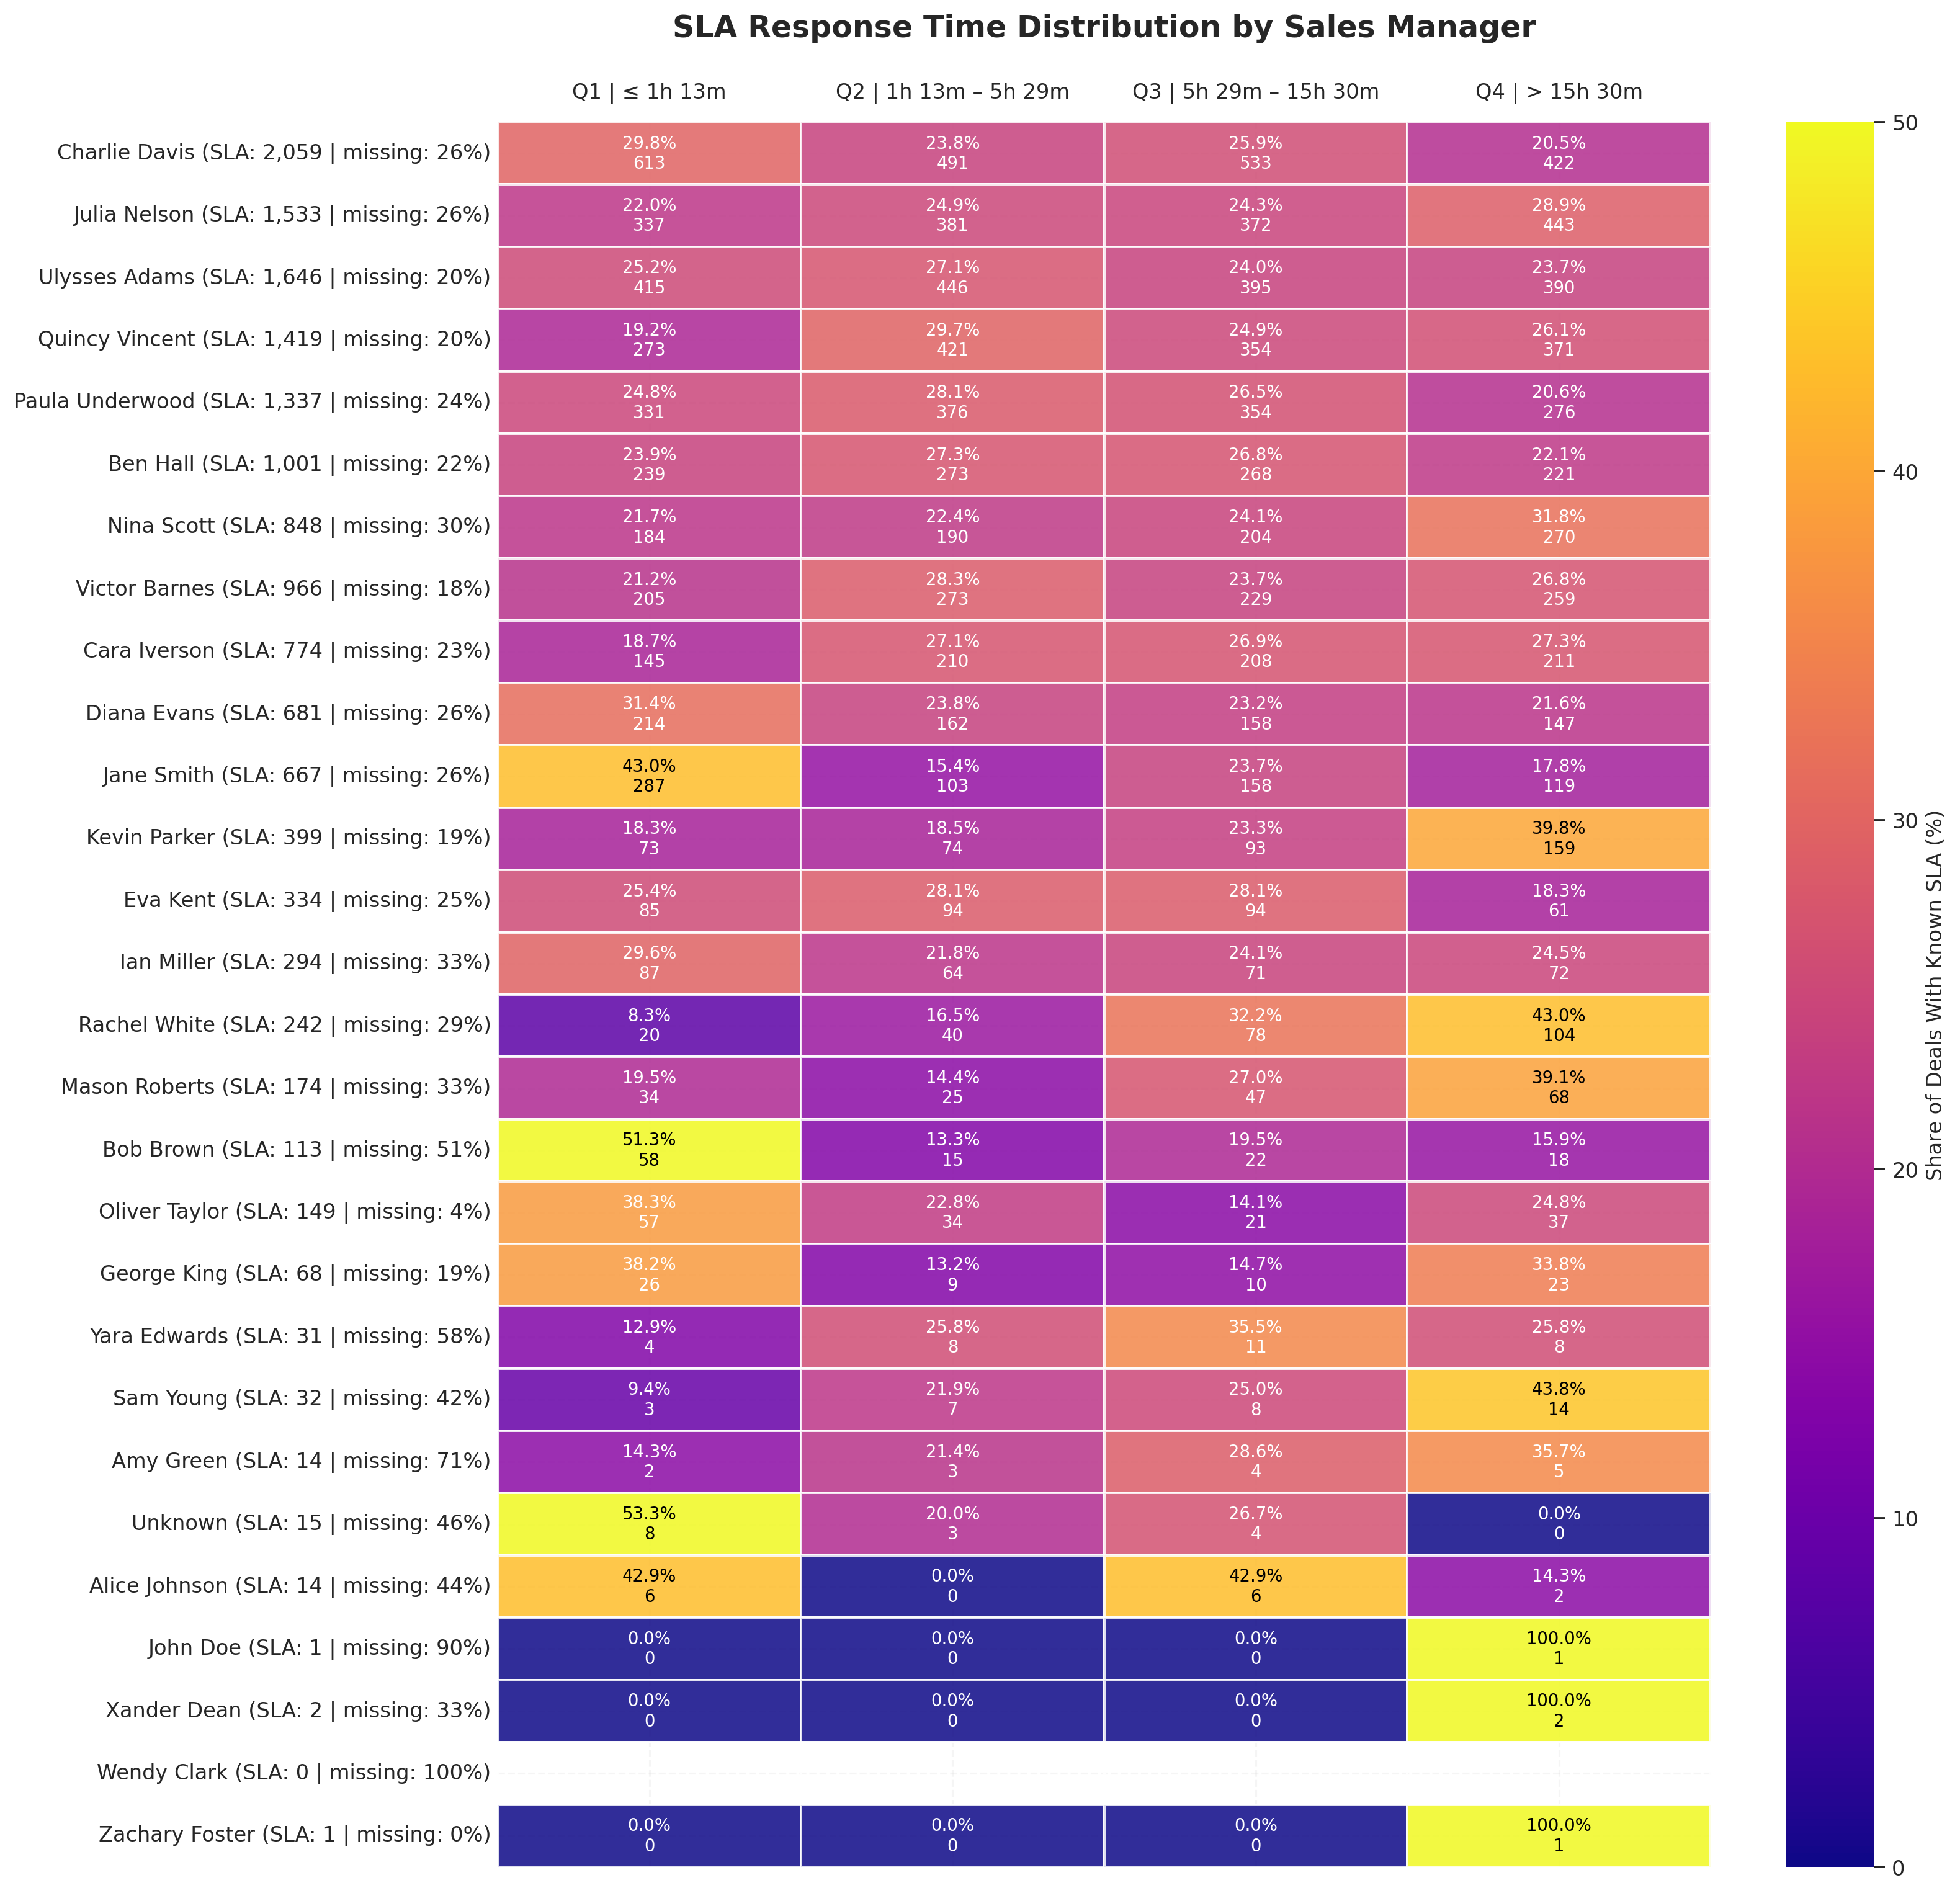

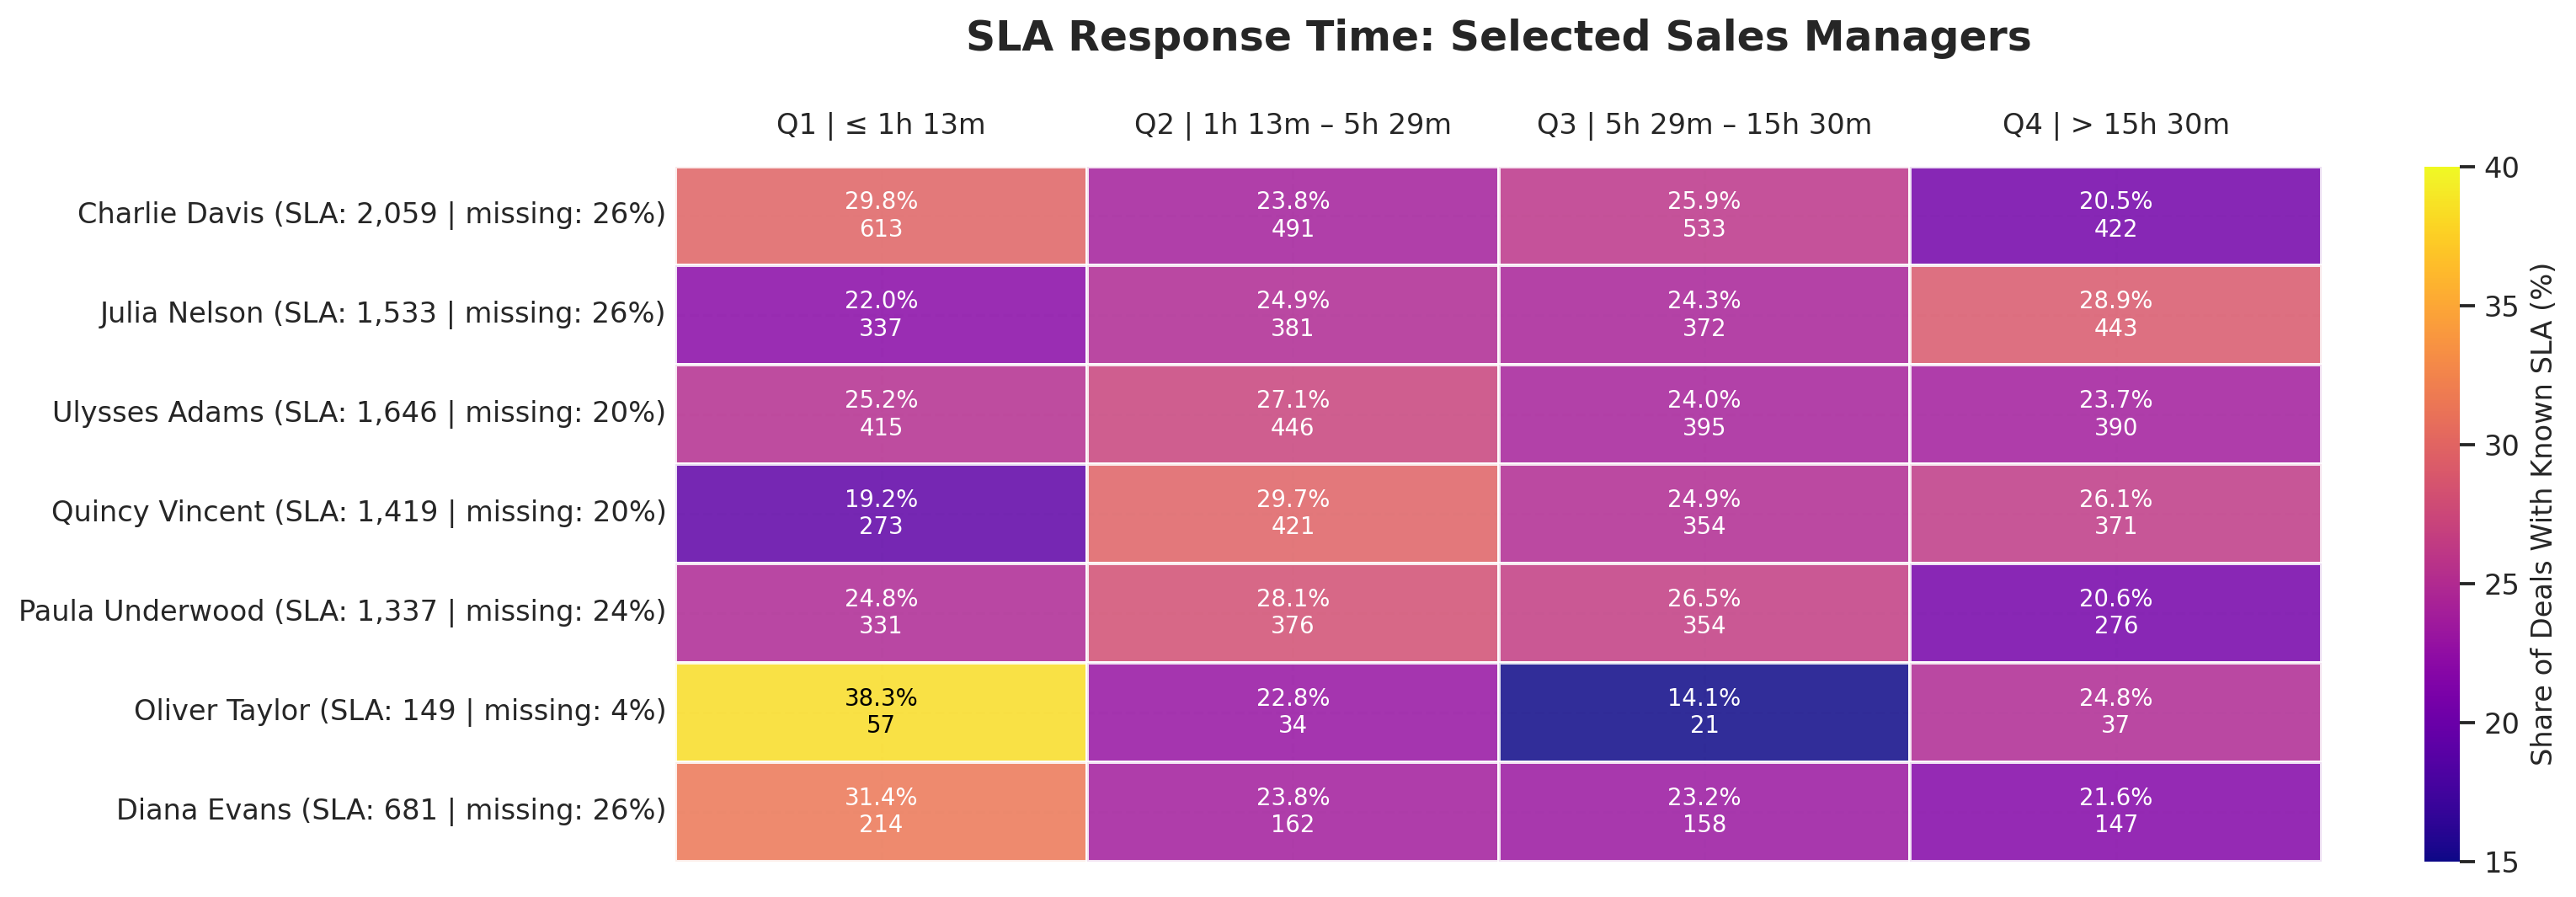

In [ ]:
HEATMAP_CMAP = "plasma"

for title, owners, vmin, vmax in [
    (
        "SLA Response Time Distribution by Sales Manager",
        sla_counts.index,
        0,
        50
    ),
    (
        "SLA Response Time: Selected Sales Managers",
        selected_owners,
        15,
        40
    )
]:
    percentages = sla_percent.reindex(owners)
    counts = sla_counts.reindex(owners)

    annotations = pd.DataFrame(
        [
            [
                f"{pct:.1f}%\n{count:,}" if pd.notna(pct) else "N/A"
                for pct, count in zip(pct_row, count_row)
            ]
            for pct_row, count_row in zip(
                percentages.to_numpy(),
                counts.to_numpy()
            )
        ],
        index=percentages.index,
        columns=percentages.columns
    )

    row_labels = [
        f"{owner} (SLA: {int(sla_known.loc[owner]):,} | "
        f"missing: {sla_missing.loc[owner] / manager_totals.loc[owner]:.0%})"
        for owner in owners
    ]

    fig, ax = plt.subplots(
        figsize=(15, max(5, len(owners) * 0.43 + 2))
    )

    sns.heatmap(
        percentages,
        annot=annotations,
        fmt="",
        cmap=HEATMAP_CMAP,
        vmin=vmin,
        vmax=vmax,
        mask=percentages.isna(),
        linewidths=0.8,
        linecolor="white",
        cbar_kws={"label": "Share of Deals With Known SLA (%)"},
        annot_kws={"fontsize": 9, "color": "white"},
        ax=ax
    )

    ax.collections[0].set_alpha(0.85)

    for text in ax.texts:
        row = int(text.get_position()[1])
        col = int(text.get_position()[0])

        value = percentages.iloc[row, col]

        if pd.notna(value):
            if value >= vmin + 0.78 * (vmax - vmin):
                text.set_color("black")
            else:
                text.set_color("white")

    ax.set_yticklabels(row_labels, rotation=0)
    ax.xaxis.tick_top()

    ax.tick_params(
        axis="x",
        top=True,
        labeltop=True,
        bottom=False,
        labelbottom=False,
        length=0,
        pad=10
    )

    ax.tick_params(axis="y", length=0)

    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold",
        pad=45
    )

    plt.tight_layout()
    plt.show()

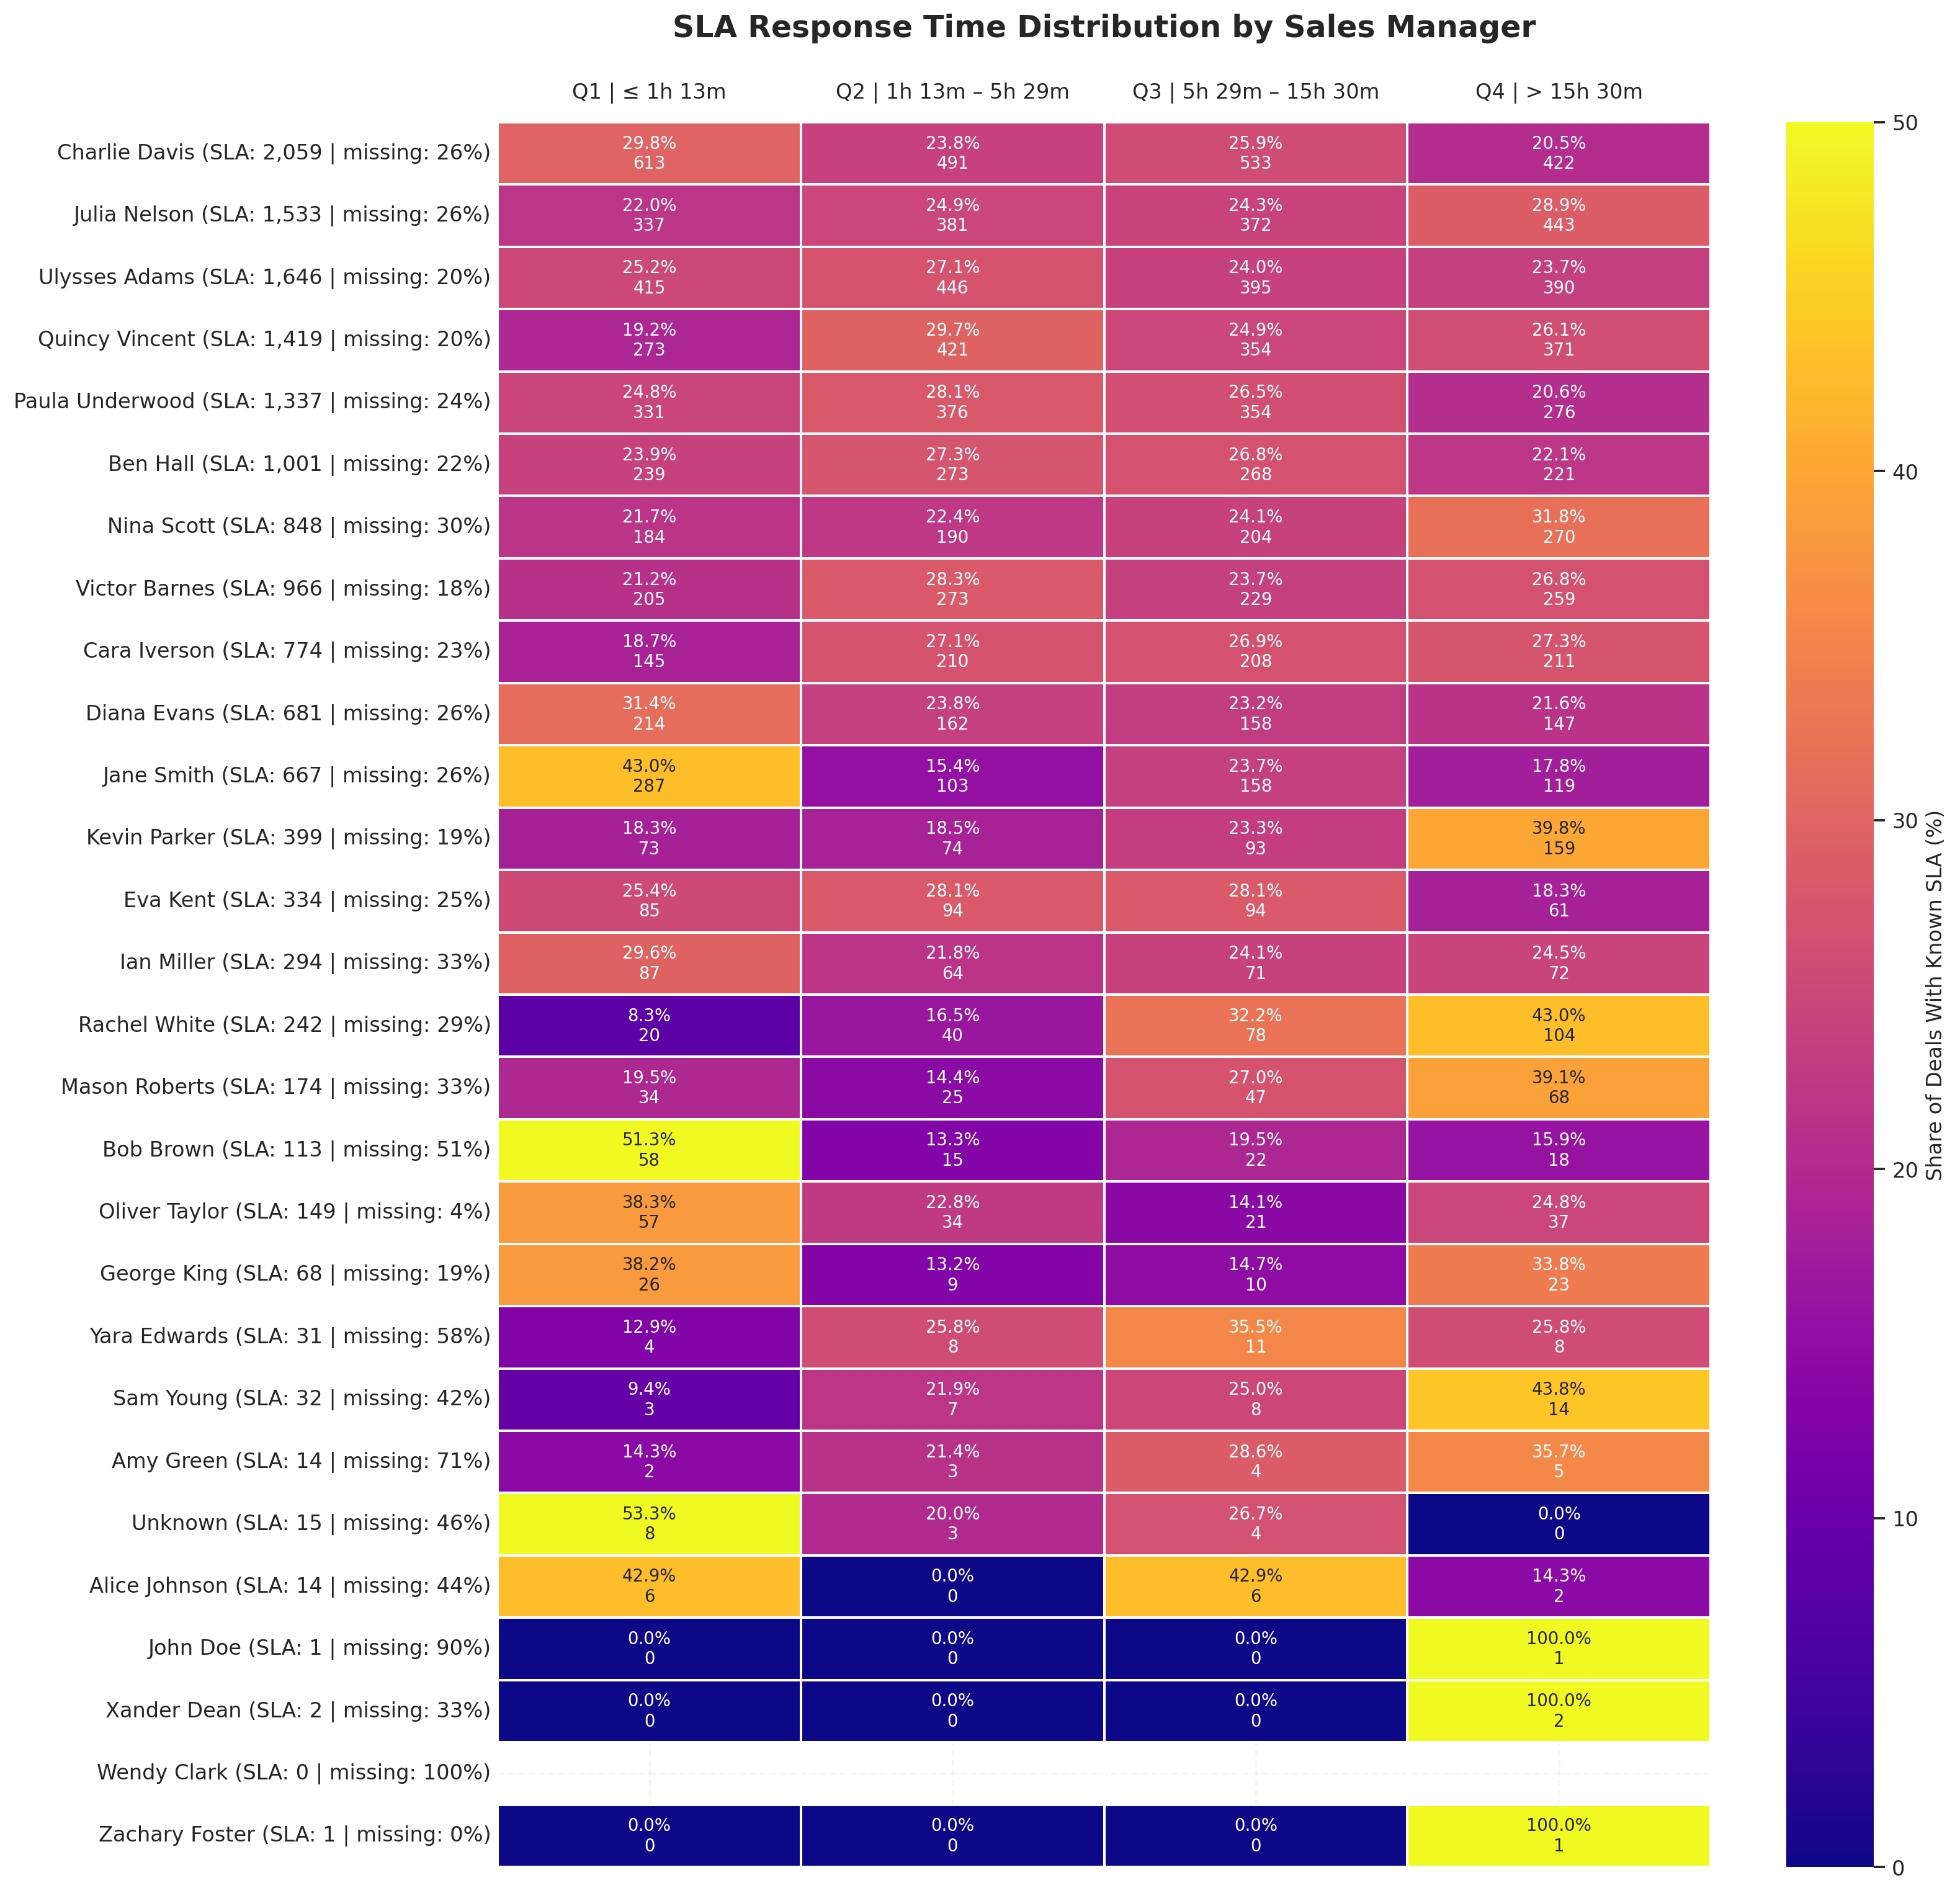

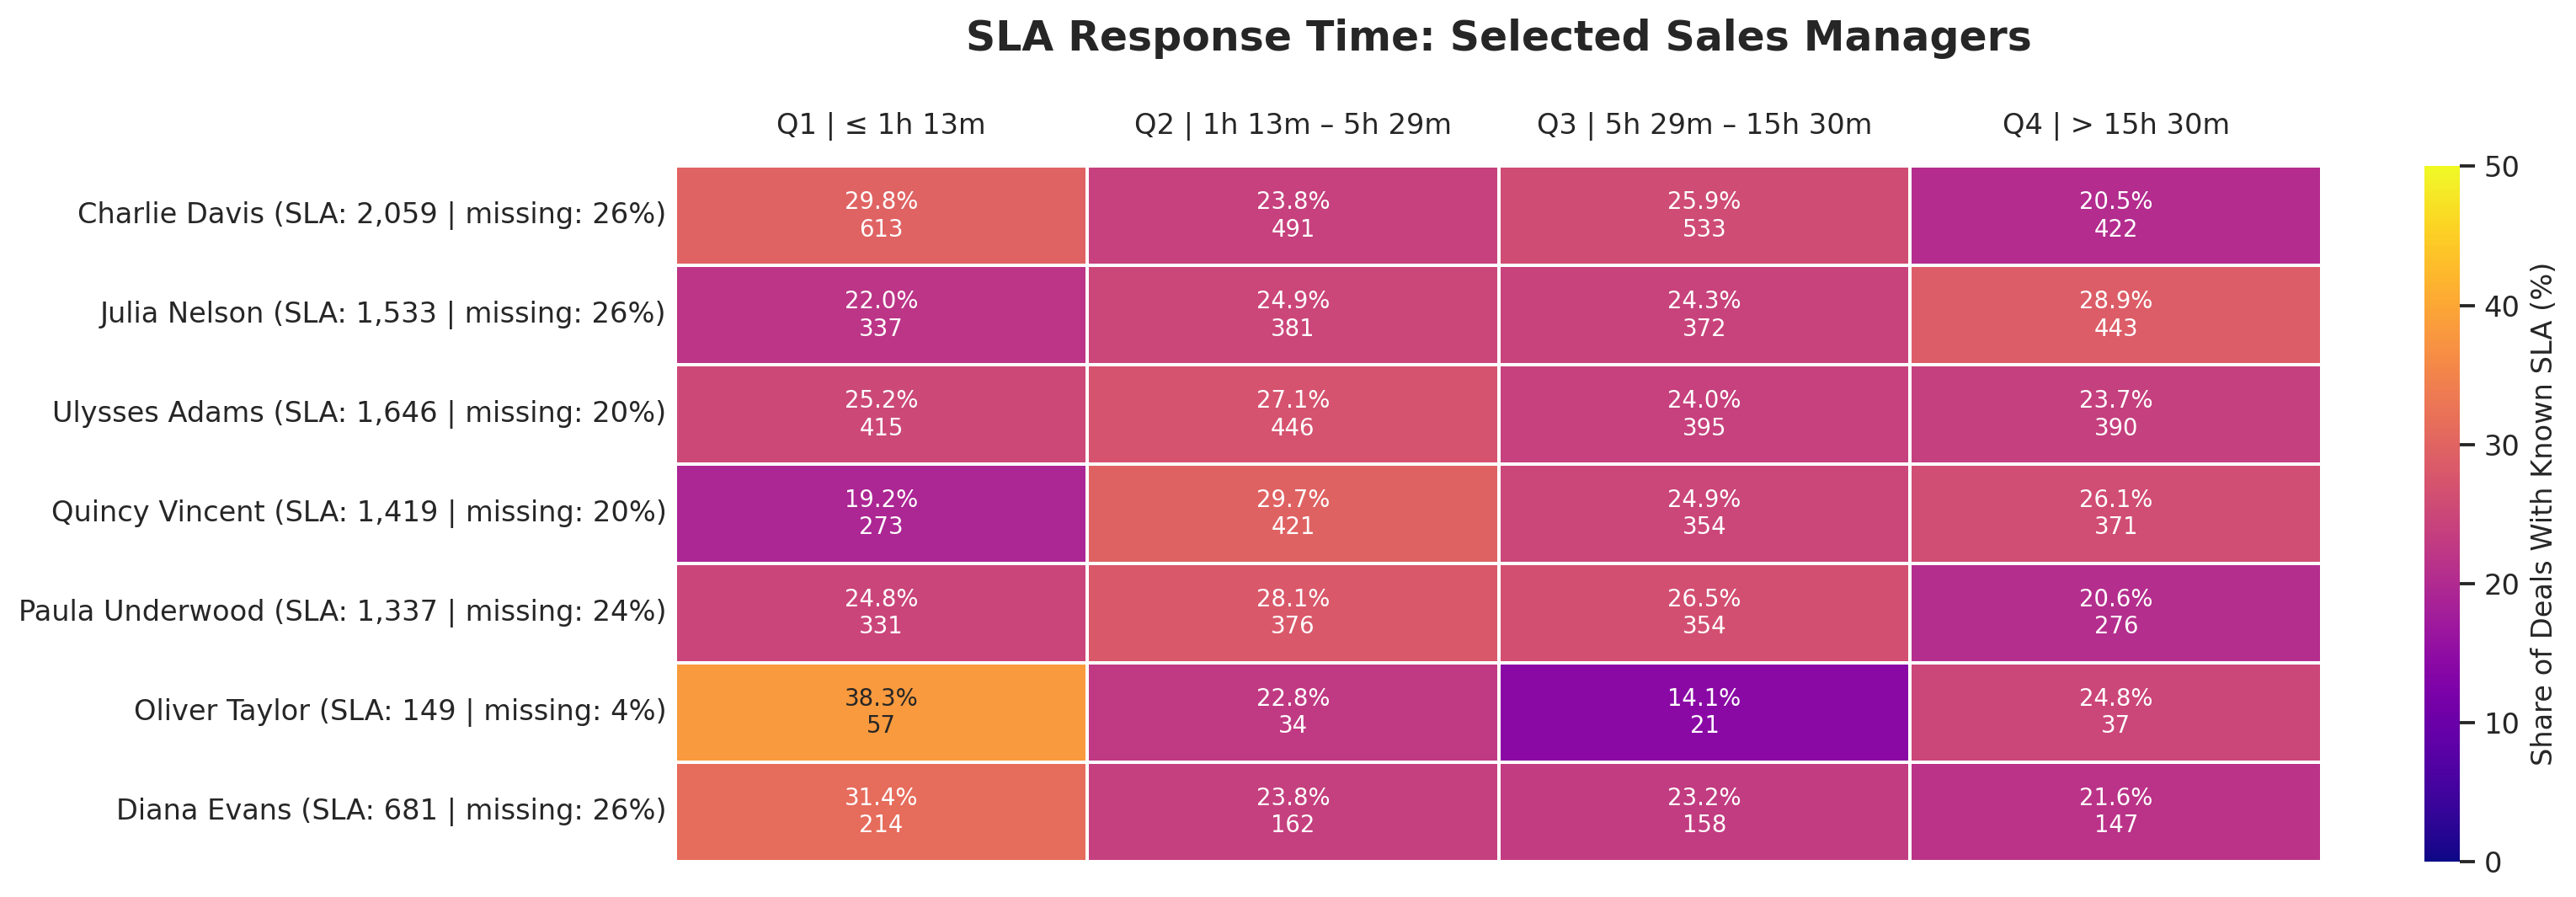

In [ ]:
# @title
for title, owners in [
    ("SLA Response Time Distribution by Sales Manager", sla_counts.index),
    ("SLA Response Time: Selected Sales Managers", selected_owners)
]:
    percentages = sla_percent.reindex(owners)
    counts = sla_counts.reindex(owners)

    annotations = pd.DataFrame(
        [
            [
                f"{pct:.1f}%\n{count:,}" if pd.notna(pct) else "N/A"
                for pct, count in zip(pct_row, count_row)
            ]
            for pct_row, count_row in zip(
                percentages.to_numpy(),
                counts.to_numpy()
            )
        ],
        index=percentages.index,
        columns=percentages.columns
    )

    row_labels = [
        f"{owner} (SLA: {int(sla_known.loc[owner]):,} | "
        f"missing: {sla_missing.loc[owner] / manager_totals.loc[owner]:.0%})"
        for owner in owners
    ]

    fig, ax = plt.subplots(
        figsize=(15, max(5, len(owners) * 0.43 + 2))
    )

    sns.heatmap(
        percentages,
        annot=annotations,
        fmt="",
        cmap=HEATMAP_CMAP,
        vmin=0,
        vmax=50,
        mask=percentages.isna(),
        linewidths=0.8,
        linecolor="white",
        cbar_kws={"label": "Share of Deals With Known SLA (%)"},
        annot_kws={"fontsize": 9},
        ax=ax
    )

    ax.set_yticklabels(row_labels, rotation=0)
    ax.xaxis.tick_top()

    ax.tick_params(
        axis="x",
        top=True,
        labeltop=True,
        bottom=False,
        labelbottom=False,
        length=0,
        pad=10
    )

    ax.tick_params(axis="y", length=0)

    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold",
        pad=45
    )

    plt.tight_layout()
    plt.show()

In [ ]:
print("MANAGERS WITH 0–3 KNOWN SLA VALUES")

display(
    manager_performance.loc[
        manager_performance["Owner"].isin(sla_known.loc[sla_known <= 3].index)
    ].assign(
        Known_SLA=lambda df: df["Owner"].map(sla_known),
        Missing_SLA=lambda df: df["Total_Deals"] - df["Known_SLA"]
    )
)

MANAGERS WITH 0–3 KNOWN SLA VALUES


,Owner,Total_Deals,Paid_Deals,Total_Sales,Conversion_Rate,Known_SLA,Missing_SLA
24,John Doe,10,0,0,0.0,1,9
25,Xander Dean,3,0,0,0.0,2,1
26,Wendy Clark,1,0,0,0.0,0,1
27,Zachary Foster,1,0,0,0.0,1,0


In [ ]:
sla_conversion = (
    deals.assign(
        SLA_Group=pd.cut(
            deals["SLA Seconds"],
            bins=sla_bins,
            labels=sla_labels,
            include_lowest=True
        ).astype("object").fillna("Missing SLA"),
        Is_Paid=deals["Stage"].eq("Payment Done")
    )
    .groupby("SLA_Group")
    .agg(
        Total_Deals=("Is_Paid", "size"),
        Paid_Deals=("Is_Paid", "sum")
    )
    .reindex(sla_labels + ["Missing SLA"])
)

In [ ]:
sla_conversion["Conversion_Rate"] = (
    sla_conversion["Paid_Deals"]
    / sla_conversion["Total_Deals"]
    * 100
).round(2)

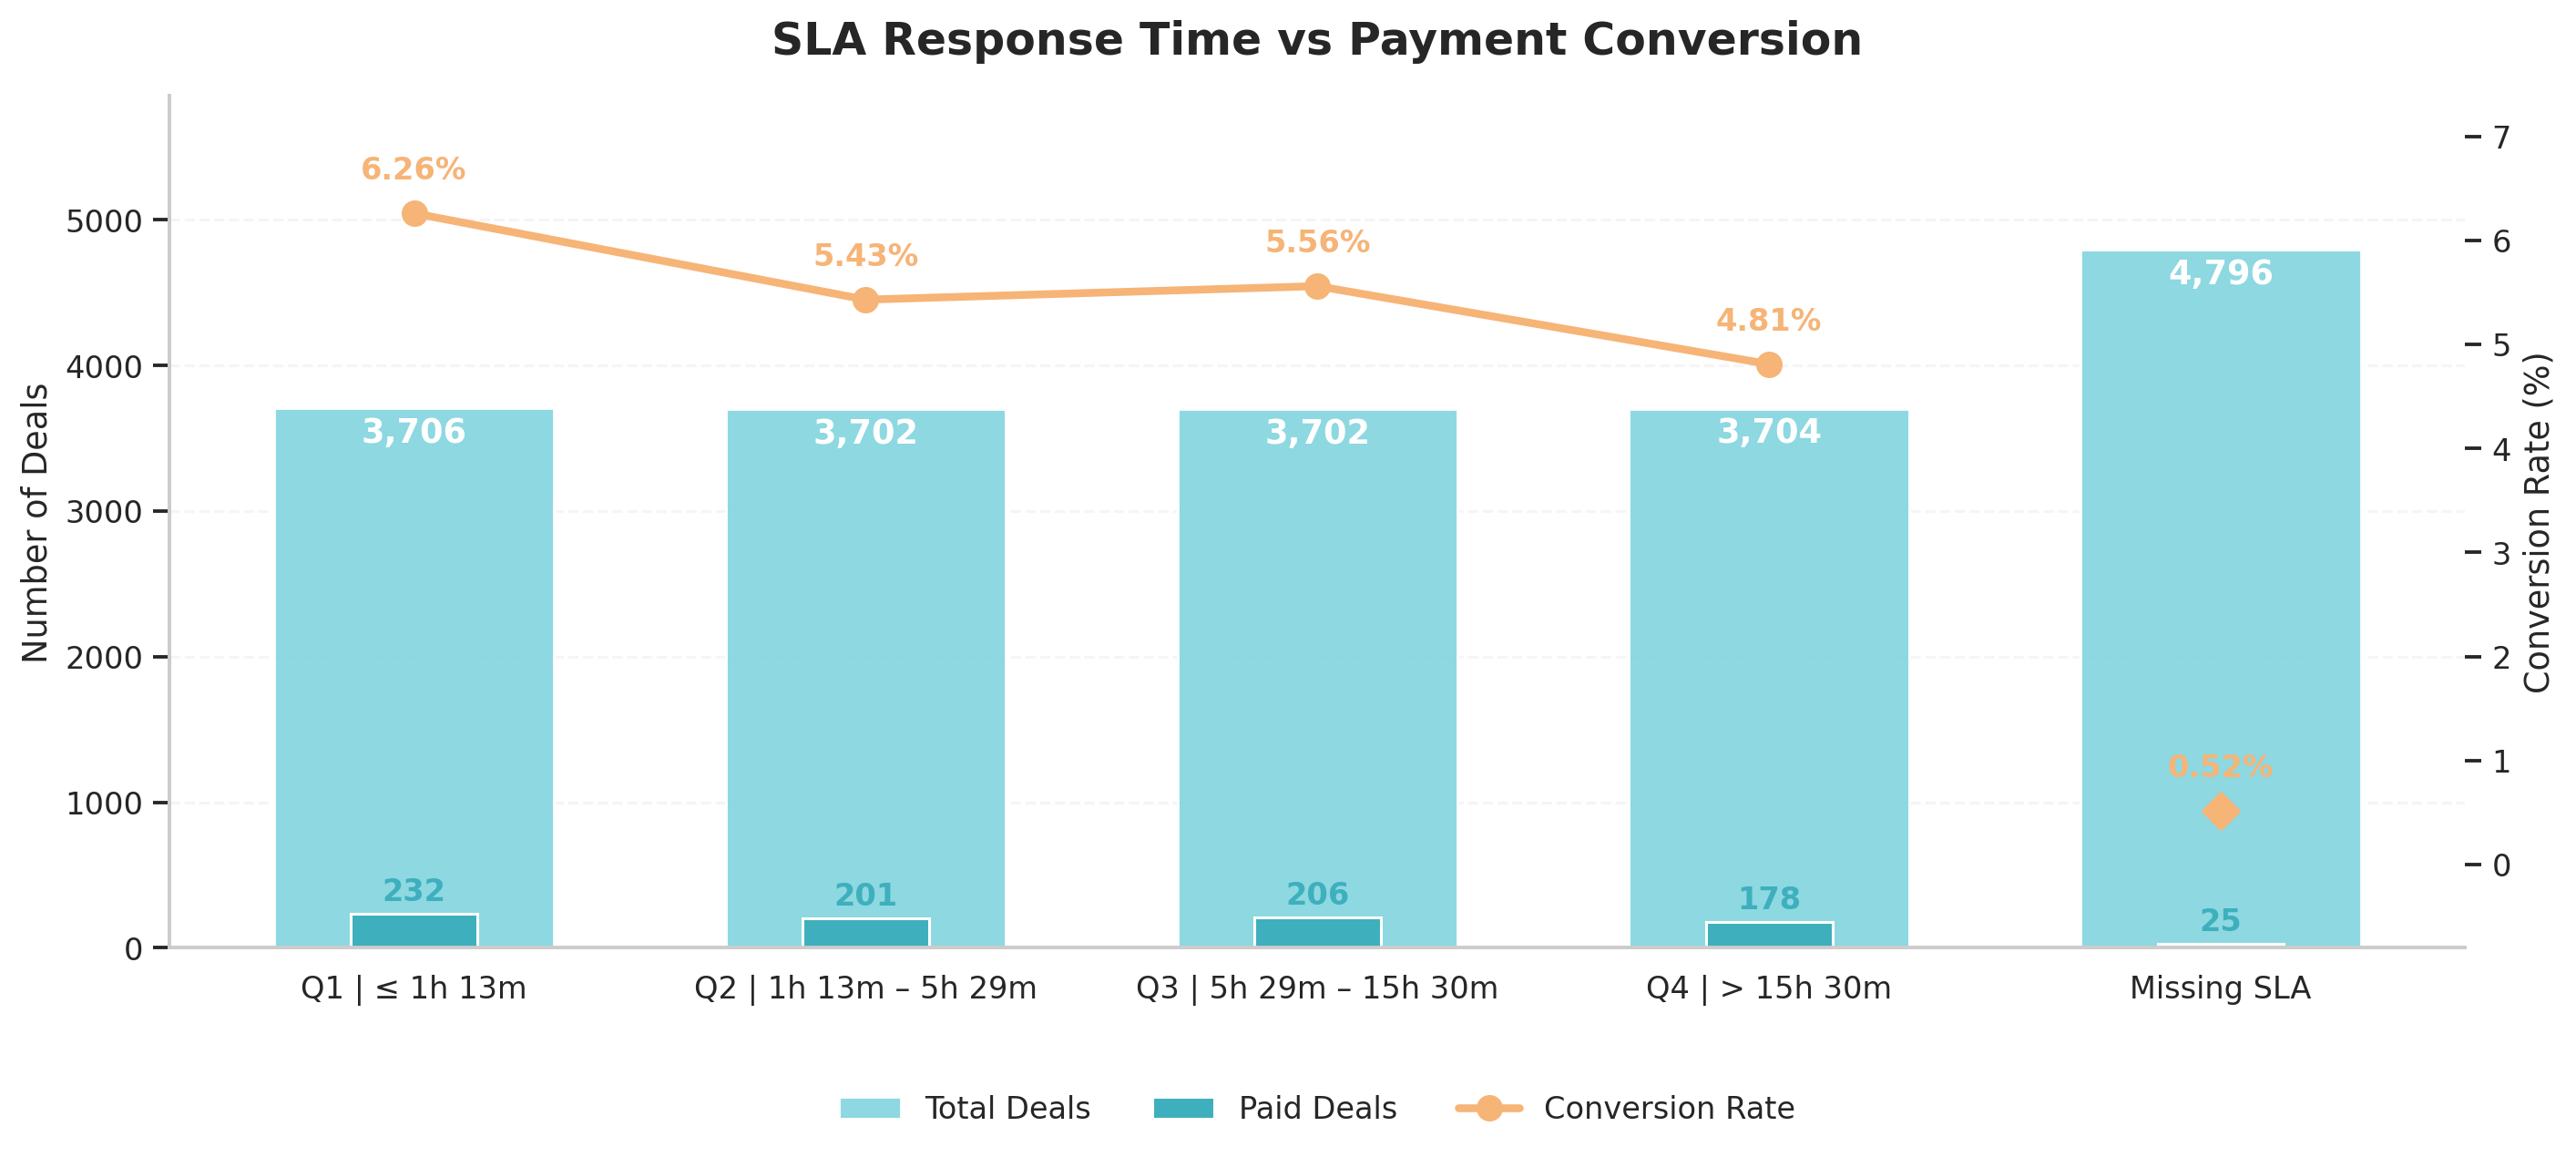

In [ ]:
x = np.arange(len(sla_conversion))

fig, ax1 = plt.subplots(figsize=(13, 6))
ax2 = ax1.twinx()

max_total = sla_conversion["Total_Deals"].max()
max_conv = sla_conversion["Conversion_Rate"].max()


total_bars = ax1.bar(
    x,
    sla_conversion["Total_Deals"],
    width=0.62,
    color=ACCENT_COLOR,
    alpha=0.92,
    label="Total Deals",
    zorder=2
)

paid_bars = ax1.bar(
    x,
    sla_conversion["Paid_Deals"],
    width=0.28,
    color=PRIMARY_COLOR,
    label="Paid Deals",
    zorder=3
)


conversion_line, = ax2.plot(
    x[:4],
    sla_conversion["Conversion_Rate"].iloc[:4],
    color=SECONDARY_COLOR,
    marker="o",
    linewidth=2.8,
    markersize=8.5,
    label="Conversion Rate",
    zorder=5
)


ax2.scatter(
    x[4],
    sla_conversion["Conversion_Rate"].iloc[4],
    color=SECONDARY_COLOR,
    marker="D",
    s=85,
    zorder=5
)


for i, row in enumerate(sla_conversion.itertuples()):
    ax1.text(
        i,
        row.Total_Deals - max_total * 0.035,
        f"{row.Total_Deals:,}",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="white",
        zorder=6
    )


    ax1.text(
        i,
        row.Paid_Deals + max_total * 0.01,
        f"{row.Paid_Deals:,}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=PRIMARY_COLOR,
        zorder=6
    )


    ax2.annotate(
        f"{row.Conversion_Rate:.2f}%",
        (i, row.Conversion_Rate),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=SECONDARY_COLOR
    )


ax1.set_title(
    "SLA Response Time vs Payment Conversion",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax1.set_xticks(x)
ax1.set_xticklabels(sla_conversion.index, fontsize=11)

ax1.set_ylabel("Number of Deals", fontsize=12)
ax2.set_ylabel("Conversion Rate (%)", fontsize=12)


ax1.set_ylim(0, max_total * 1.22)
ax2.set_ylim(-0.8, max_conv * 1.18)


ax1.grid(axis="y", alpha=0.18, linestyle="--")
ax1.grid(axis="x", visible=False)
ax2.grid(False)

ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)


ax1.legend(
    handles=[total_bars, paid_bars, conversion_line],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.14),
    ncol=3,
    frameon=False,
    fontsize=11
)

plt.tight_layout()
plt.show()

Conclusion

The analysis of `SLA Seconds` revealed an association between the speed of first contact and payment conversion. The highest conversion rate (6.26%) was observed in Q1, where managers contacted leads within approximately 1 hour and 13 minutes. Q2 and Q3 showed similar conversion rates of 5.43% and 5.56%, respectively, while Q4, representing response times exceeding 15 hours and 30 minutes, had the lowest conversion among deals with recorded SLA (4.81%). Thus, faster responses are generally associated with better conversion outcomes, although the relationship is not strictly monotonic.

A particularly notable result was observed among deals with missing SLA values. Of the 4,796 deals in this group, only 25 resulted in payment, corresponding to a conversion rate of just 0.52%. This may reflect incomplete CRM records or differences in how these deals were handled.

The SLA heatmaps showed that the five managers with the highest deal volumes have relatively similar response-time distributions. Oliver Taylor and Diana Evans also demonstrate comparable patterns, despite their substantial difference in payment conversion. Oliver has a higher share of deals in Q1 than Diana (38.3% vs. 31.4%), but also a slightly higher share in Q4 (24.8% vs. 21.6%). Consequently, response times alone cannot explain the considerable difference in their sales performance.

Four other managers — John Doe, Xander Dean, Wendy Clark, and Zachary Foster — have only 1–10 deals each and very few recorded SLA values. Their limited activity may reflect different responsibilities or particular types of deals, but the available data do not establish the reasons.

**Overall, faster first contact is associated with higher payment conversion at the aggregate level, but SLA alone does not explain the substantial differences in individual managers' performance.** Other factors, such as customer readiness to purchase, deal allocation, and differences in sales processes, may also contribute to these results.

## 4.2. Campaign and Source Performance

In [ ]:
campaign_sales = (
    deals.assign(
        Source=deals["Source"],
        Campaign=deals["Campaign"].fillna("Unknown"),
        Is_Paid=deals["Stage"].eq("Payment Done"),
        Sales_Amount=deals["Offer Total Amount"].where(
            deals["Stage"].eq("Payment Done"), 0
        )
    )
    .groupby(["Source", "Campaign"], as_index=False)
    .agg(
        Total_Deals=("Id", "size"),
        Paid_Deals=("Is_Paid", "sum"),
        Total_Sales=("Sales_Amount", "sum")
    )
)

campaign_sales["Conversion_Rate"] = (
    campaign_sales["Paid_Deals"]
    / campaign_sales["Total_Deals"]
    * 100
).round(2)

campaign_sales = campaign_sales.sort_values(
    "Total_Deals", ascending=False
).reset_index(drop=True)

print("Number of campaign combinations:", len(campaign_sales))
print("Total deals:", campaign_sales["Total_Deals"].sum())
print("Paid deals:", campaign_sales["Paid_Deals"].sum())
print("Total sales:", f"€{campaign_sales['Total_Sales'].sum():,.0f}")

display(campaign_sales.head(15))

Number of campaign combinations: 192
Total deals: 19610
Paid deals: 842
Total sales: €6,257,600


,Source,Campaign,Total_Deals,Paid_Deals,Total_Sales,Conversion_Rate
0,Google Ads,performancemax_digitalmarkt_ru_DE,2571,112,840900,4.36
1,Youtube Ads,youtube_shorts_DE,1592,53,415500,3.33
2,Tiktok Ads,12.07.2023wide_DE,1530,48,336900,3.14
3,Organic,Unknown,1466,139,1050400,9.48
4,SMM,Unknown,1284,82,551900,6.39
5,Facebook Ads,02.07.23wide_DE,942,52,396900,5.52
6,Facebook Ads,04.07.23recentlymoved_DE,733,31,199900,4.23
7,Facebook Ads,03.07.23women,595,31,256000,5.21
8,Google Ads,Dis_DE,567,30,222000,5.29
9,Facebook Ads,07.07.23LAL_DE,529,28,243500,5.29


In [ ]:
campaigns_selected = (
    campaign_sales.loc[campaign_sales["Campaign"] != "Unknown"]
    .nlargest(20, "Total_Deals")
    .reset_index(drop=True)
)

display(campaigns_selected)

,Source,Campaign,Total_Deals,Paid_Deals,Total_Sales,Conversion_Rate
0,Google Ads,performancemax_digitalmarkt_ru_DE,2571,112,840900,4.36
1,Youtube Ads,youtube_shorts_DE,1592,53,415500,3.33
2,Tiktok Ads,12.07.2023wide_DE,1530,48,336900,3.14
3,Facebook Ads,02.07.23wide_DE,942,52,396900,5.52
4,Facebook Ads,04.07.23recentlymoved_DE,733,31,199900,4.23
5,Facebook Ads,03.07.23women,595,31,256000,5.21
6,Google Ads,Dis_DE,567,30,222000,5.29
7,Facebook Ads,07.07.23LAL_DE,529,28,243500,5.29
8,Facebook Ads,12.09.23interests_Uxui_DE,514,27,229000,5.25
9,Facebook Ads,24.09.23retargeting_DE,472,17,146000,3.60


In [ ]:
sources = campaigns_selected["Source"].unique()

symbols = [
    "circle", "square", "diamond", "triangle-up",
    "pentagon", "hexagon", "star", "cross"
]

source_colors = {
    source: PALETTE[i % len(PALETTE)]
    for i, source in enumerate(sources)
}

In [ ]:
source_colors.update({
    "Youtube Ads": NEUTRAL_COLOR,
    "CRM": SECONDARY_COLOR
})

In [ ]:
fig = go.Figure()

for i, source in enumerate(sources):
    data = campaigns_selected.loc[
        campaigns_selected["Source"] == source
    ]

    fig.add_trace(
        go.Scatter(
            x=data["Total_Deals"],
            y=data["Conversion_Rate"],
            mode="markers",
            name=source,
            marker=dict(
                size=data["Total_Sales"].clip(
                    lower=campaigns_selected["Total_Sales"].max() * 0.01
                ),
                sizemode="area",
                sizeref=(
                    2 * campaigns_selected["Total_Sales"].max() / 55**2
                ),
                sizemin=9,
                color=source_colors[source],
                symbol=symbols[i % len(symbols)],
                opacity=0.85,
                line=dict(color="white", width=1.5)
            ),
            customdata=data[
                ["Campaign", "Paid_Deals", "Total_Sales"]
            ].to_numpy(),
            hovertemplate=(
                "<b>%{customdata[0]}</b>"
                f"<br>Source: {source}"
                "<br>Total Deals: %{x:,}"
                "<br>Paid Deals: %{customdata[1]:,}"
                "<br>Conversion Rate: %{y:.2f}%"
                "<br>Total Sales: €%{customdata[2]:,.0f}"
                "<extra></extra>"
            )
        )
    )

fig.update_layout(
    title=dict(
        text="<b>Top 20 Campaigns: Deal Volume, Conversion & Total Sales</b>",
        x=0.5,
        xanchor="center",
        y=0.93,
        font=dict(size=17, color="#263238")
    ),
    xaxis_title="Total Deals",
    yaxis_title="Conversion Rate (%)",
    template="plotly_white",
    height=720,
    width=1500,
    showlegend=True,
    legend=dict(
        title="Source",
        x=1.02,
        y=1,
        xanchor="left",
        yanchor="top",
        font=dict(size=12),
        itemsizing="constant"
    ),
    margin=dict(l=80, r=190, t=110, b=80),
    font=dict(size=12, color="#404B52"),
    plot_bgcolor="white",
    paper_bgcolor="white"
)

fig.update_xaxes(
    range=[0, campaigns_selected["Total_Deals"].max() * 1.08],
    dtick=250,
    showgrid=True,
    gridcolor="rgba(64, 75, 82, 0.12)",
    zeroline=False
)

fig.update_yaxes(
    range=[0, campaigns_selected["Conversion_Rate"].max() * 1.12],
    dtick=2,
    showgrid=True,
    gridcolor="rgba(64, 75, 82, 0.12)",
    zeroline=False
)

fig.show()

In [ ]:
source_sales = (
    campaign_sales
    .groupby("Source", as_index=False)
    .agg(
        Total_Deals=("Total_Deals", "sum"),
        Paid_Deals=("Paid_Deals", "sum"),
        Total_Sales=("Total_Sales", "sum")
    )
)

source_sales["Conversion_Rate"] = (
    source_sales["Paid_Deals"]
    / source_sales["Total_Deals"]
    * 100
).round(2)

source_sales = source_sales.sort_values(
    "Total_Deals", ascending=False
).reset_index(drop=True)

In [ ]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=source_sales["Total_Deals"],
        y=source_sales["Conversion_Rate"],
        mode="markers+text",
        text=source_sales["Source"],
        textposition=[
            "top right" if source == "Offline" else "top center"
            for source in source_sales["Source"]
        ],
        textfont=dict(
            size=11,
            color="#404B52"
        ),
        marker=dict(
            size=source_sales["Total_Sales"].clip(
                lower=source_sales["Total_Sales"].max() * 0.01
            ),
            sizemode="area",
            sizeref=2 * source_sales["Total_Sales"].max() / 65**2,
            sizemin=10,
            color=PRIMARY_COLOR,
            opacity=0.75,
            line=dict(color="white", width=1.5)
        ),
        customdata=source_sales[
            ["Source", "Paid_Deals", "Total_Sales"]
        ].to_numpy(),
        hovertemplate=(
            "<b>%{customdata[0]}</b>"
            "<br>Total Deals: %{x:,}"
            "<br>Paid Deals: %{customdata[1]:,}"
            "<br>Conversion Rate: %{y:.2f}%"
            "<br>Total Sales: €%{customdata[2]:,.0f}"
            "<extra></extra>"
        ),
        showlegend=False
    )
)

fig.update_layout(
    title=dict(
        text="<b>Sales Performance by Marketing Source</b>",
        x=0.5,
        xanchor="center",
        y=0.94,
        font=dict(size=17, color="#263238"),
        pad=dict(t=15)
    ),
    xaxis_title="Total Deals",
    yaxis_title="Conversion Rate (%)",
    template="plotly_white",
    height=720,
    width=1500,
    showlegend=False,
    margin=dict(l=90, r=90, t=110, b=85),
    font=dict(size=12, color="#404B52"),
    plot_bgcolor="white",
    paper_bgcolor="white"
)

fig.update_xaxes(
    range=[0, source_sales["Total_Deals"].max() * 1.15],
    showgrid=True,
    gridcolor="rgba(64, 75, 82, 0.12)",
    zeroline=False
)

fig.update_yaxes(
    range=[0, source_sales["Conversion_Rate"].max() * 1.20],
    showgrid=True,
    gridcolor="rgba(64, 75, 82, 0.12)",
    zeroline=False
)

fig.show()

Conclusion

The analysis of the Top 20 campaigns by `Total_Deals` revealed substantial differences in sales performance across campaigns and marketing sources.

**Google Ads** generated the strongest individual campaign results. `performancemax_digitalmarkt_ru_DE` led in deal volume (2,571), paid deals (112), and total sales (€840,900), despite a moderate conversion rate of 4.36%. Meanwhile, `brand_search_eng_DE` achieved the highest conversion rate among the Top 20 (9.32%), whereas `performancemax_eng_DE` converted only 0.41%. This demonstrates considerable variation even within the same source.

**Facebook Ads** showed relatively consistent conversion rates of approximately 4–5.5% across its major campaigns. Notably, two similarly named campaigns, `02.07.23wide_DE` (Facebook Ads) and `12.07.2023wide_DE` (TikTok Ads), produced different outcomes. Despite generating fewer deals (942 vs. 1,530), Facebook Ads achieved more payments (52 vs. 48) and higher total sales (€396,900 vs. €336,900), supported by a higher conversion rate (5.52% vs. 3.14%). This illustrates that campaigns with similar names can perform differently across marketing sources.

**YouTube Ads and TikTok Ads** generated substantial deal volumes but relatively low conversion rates. Results also varied among Bloggers campaigns: `BloggerShina_DE` achieved 11 payments and €108,000 in sales, while `bbo_DE` generated no payments.

Four campaigns, including two CRM webinar campaigns, produced **862 deals without a single payment**, demonstrating that a high deal volume does not necessarily lead to successful sales.

At the overall source level, **Facebook Ads and Google Ads dominated in deal volume and total sales**, while **Organic and Webinar achieved the highest conversion rates**, approximately 9.5% and 8.6%, respectively. SMM demonstrated a relatively balanced combination of deal volume and conversion, whereas CRM, Partnership, and Offline showed substantially lower conversion rates.

**Overall, sales performance varies both between campaigns within the same source and between marketing sources. High deal volume drives substantial total sales, but does not guarantee high conversion.** Evaluating campaign effectiveness therefore requires considering `Total_Deals`, `Paid_Deals`, `Conversion_Rate`, and `Total_Sales` together.

# 5. Payment and Product Analysis

## 5.1 Payment Type Analysis

In [ ]:
payment_performance = (
    deals.loc[deals["Payment Type"].notna()]
    .assign(Is_Paid=lambda df: df["Stage"].eq("Payment Done"))
    .groupby("Payment Type", as_index=False)
    .agg(
        Total_Deals=("Id", "size"),
        Paid_Deals=("Is_Paid", "sum")
    )
    .rename(columns={"Payment Type": "Payment_Type"})
)

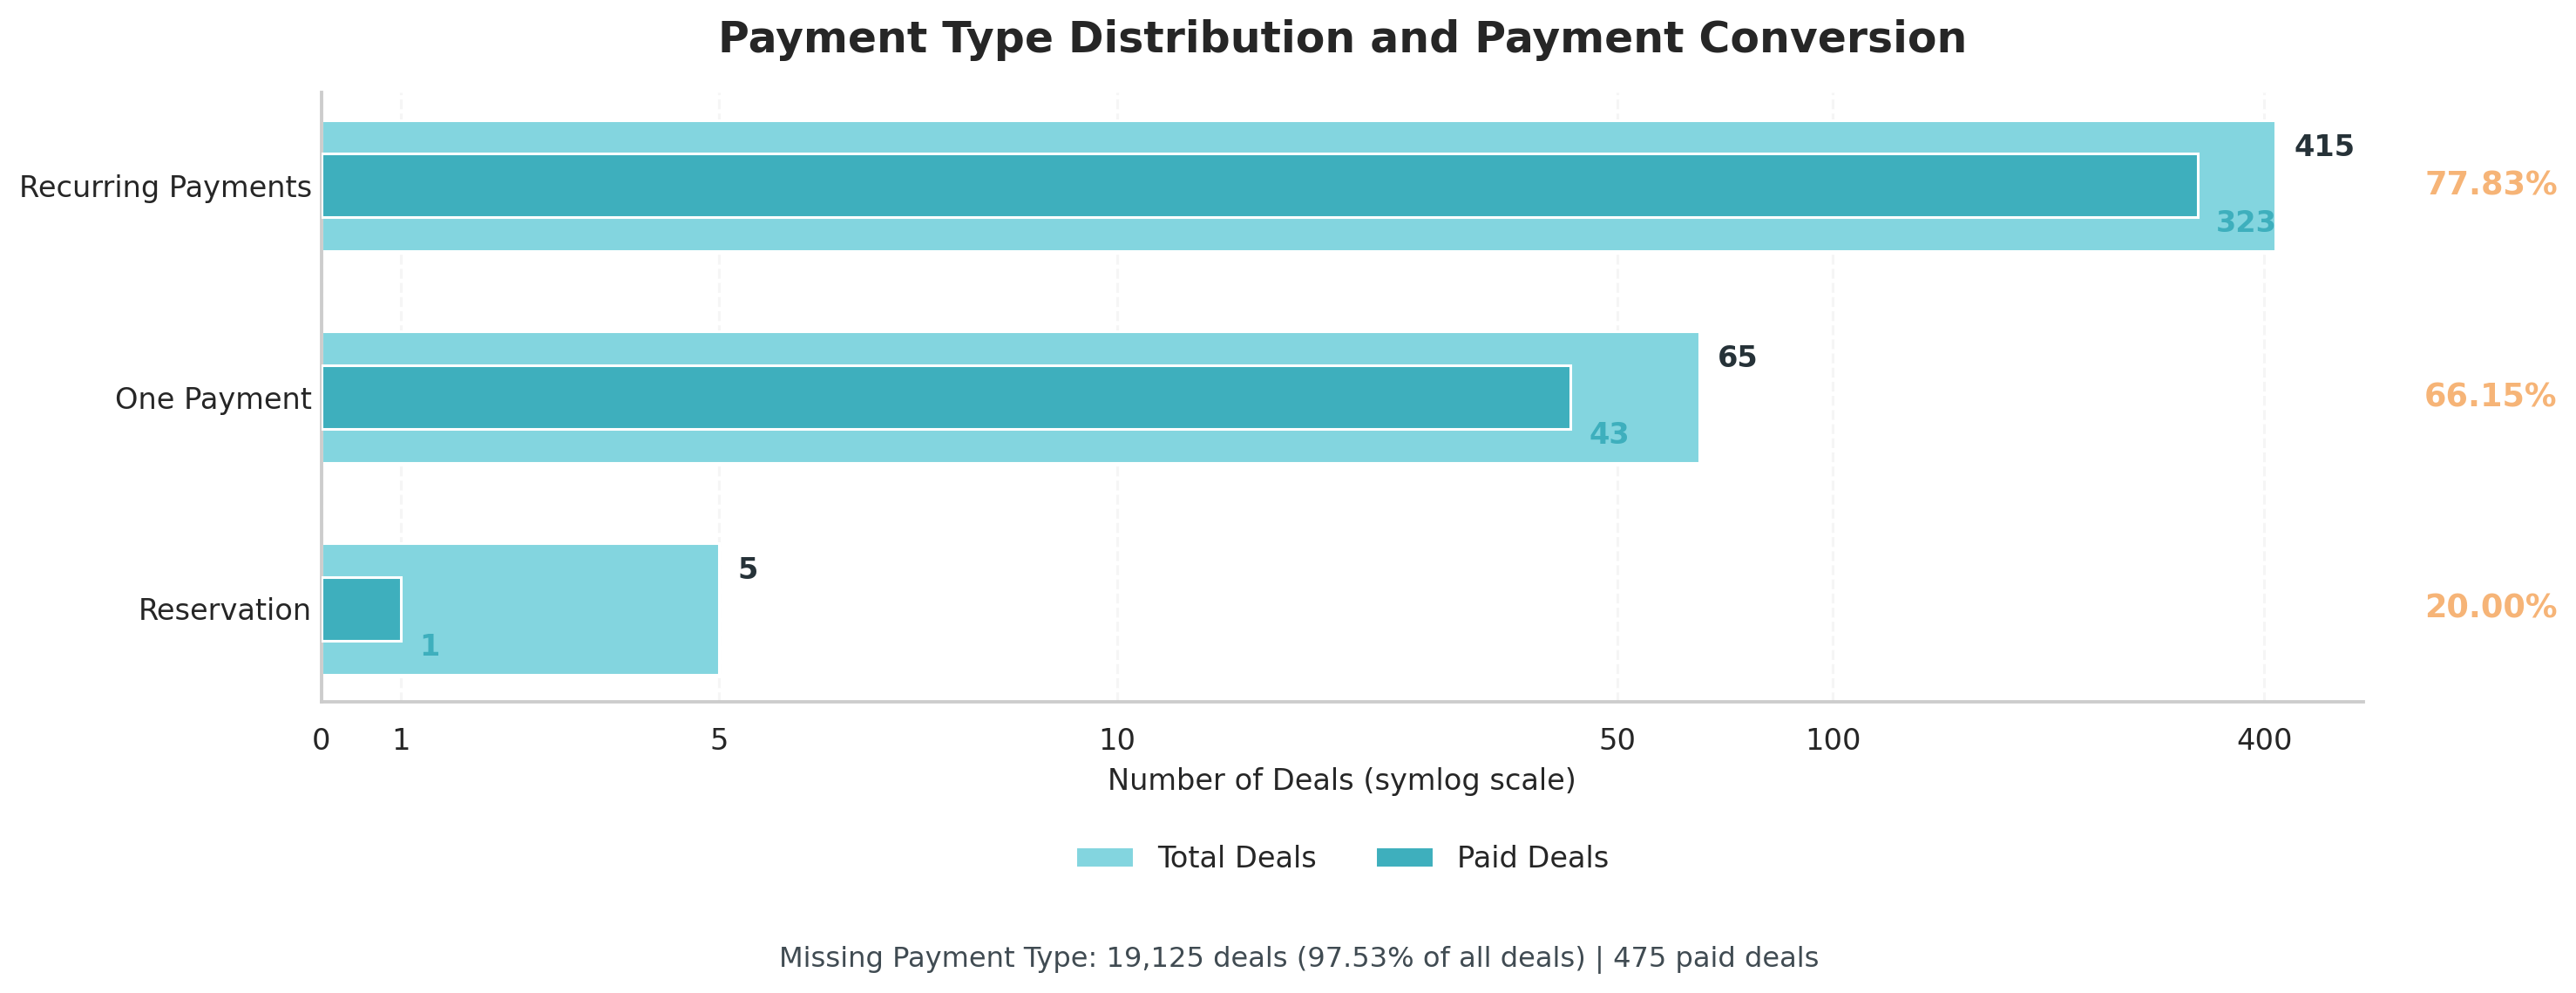

In [ ]:
payment_performance["Conversion_Rate"] = (
    payment_performance["Paid_Deals"]
    / payment_performance["Total_Deals"]
    * 100
).round(2)

payment_performance = payment_performance.sort_values(
    "Total_Deals"
).reset_index(drop=True)

missing_payment = deals["Payment Type"].isna()
missing_count = missing_payment.sum()
missing_paid = (
    missing_payment & deals["Stage"].eq("Payment Done")
).sum()

fig, ax = plt.subplots(figsize=(15, 6))

y = np.arange(len(payment_performance))

total_bars = ax.barh(
    y,
    payment_performance["Total_Deals"],
    color=ACCENT_COLOR,
    height=0.62,
    label="Total Deals",
    zorder=2
)

paid_bars = ax.barh(
    y,
    payment_performance["Paid_Deals"],
    color=PRIMARY_COLOR,
    height=0.30,
    label="Paid Deals",
    zorder=3
)

for i, row in enumerate(payment_performance.itertuples()):
    ax.annotate(
        f"{row.Total_Deals:,}",
        (row.Total_Deals, i + 0.18),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#263238"
    )

    ax.annotate(
        f"{row.Paid_Deals:,}",
        (row.Paid_Deals, i - 0.18),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=11,
        fontweight="bold",
        color=PRIMARY_COLOR
    )

    ax.text(
        1.03,
        i,
        f"{row.Conversion_Rate:.2f}%",
        transform=ax.get_yaxis_transform(),
        va="center",
        ha="left",
        fontsize=12,
        fontweight="bold",
        color=SECONDARY_COLOR
    )

ax.set_yticks(y)
ax.set_yticklabels(payment_performance["Payment_Type"], fontsize=11)

ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(0, 550)
ax.set_xticks([0, 1, 5, 10, 50, 100, 400])
ax.set_xticklabels(["0", "1", "5", "10", "50", "100", "400"])

ax.set_xlabel("Number of Deals (symlog scale)", fontsize=11)
ax.set_ylabel("")

ax.set_title(
    "Payment Type Distribution and Payment Conversion",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.grid(axis="x", alpha=0.18, linestyle="--")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)

ax.legend(
    handles=[total_bars, paid_bars],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.19),
    ncol=2,
    frameon=False,
    fontsize=11
)

fig.text(
    0.5,
    0.07,
    (
        f"Missing Payment Type: {missing_count:,} deals "
        f"({missing_count / len(deals) * 100:.2f}% of all deals) "
        f"| {missing_paid:,} paid deals"
    ),
    ha="center",
    fontsize=10.5,
    color="#404B52"
)

fig.subplots_adjust(
    left=0.16,
    right=0.87,
    top=0.83,
    bottom=0.30
)

plt.show()

Conclusion

The analysis of `Payment Type` shows that **Recurring Payments is the most common recorded payment option**, accounting for 415 deals, compared with 65 for One Payment and 5 for Reservation.

Recurring Payments also has the highest observed payment conversion rate (77.83%), followed by One Payment (66.15%) and Reservation (20.00%). However, the Reservation category contains too few observations for a reliable comparison.

A major limitation is that **97.53% of all deals have no recorded payment type**, including 475 successfully paid deals. Furthermore, `Payment Type` is recorded much more frequently for completed payments than for other deal stages. Therefore, the observed conversion differences cannot be interpreted as evidence that a particular payment method increases the likelihood of purchase.

## 5.2 Product and Education Type Performance

In [ ]:
for col in ["Product", "Education Type"]:
    print(f"\n{col.upper()}")
    print("Missing values:", deals[col].isna().sum())
    display(deals[col].value_counts(dropna=False))


PRODUCT
Missing values: 16120


,count
Product,
NaN,16120
Digital Marketing,1933
UX/UI Design,996
Web Developer,561



EDUCATION TYPE
Missing values: 16396


,count
Education Type,
NaN,16396
Morning,2819
Evening,395


In [ ]:
for col in ["Product", "Education Type"]:
    performance = (
        deals.assign(
            Category=deals[col].fillna("Missing"),
            Is_Paid=deals["Stage"].eq("Payment Done"),
            Sales_Amount=deals["Offer Total Amount"].where(
                deals["Stage"].eq("Payment Done"), 0
            )
        )
        .groupby("Category", as_index=False)
        .agg(
            Total_Deals=("Id", "size"),
            Paid_Deals=("Is_Paid", "sum"),
            Total_Sales=("Sales_Amount", "sum")
        )
    )

    performance["Conversion_Rate"] = (
        performance["Paid_Deals"]
        / performance["Total_Deals"] * 100
    ).round(2)

    print(f"\n{col.upper()} PERFORMANCE")
    display(performance.sort_values("Total_Deals", ascending=False))

    print(f"{col.upper()} COMPLETENESS BY PAYMENT STATUS")
    display(
        pd.crosstab(
            deals["Stage"].eq("Payment Done"),
            deals[col].notna(),
            normalize="index"
        ).mul(100).round(2)
    )


PRODUCT PERFORMANCE


,Category,Total_Deals,Paid_Deals,Total_Sales,Conversion_Rate
1,Missing,16120,15,0,0.09
0,Digital Marketing,1933,467,3881000,24.16
2,UX/UI Design,996,225,1800400,22.59
3,Web Developer,561,135,576200,24.06


PRODUCT COMPLETENESS BY PAYMENT STATUS


Product,False,True
Stage,,
False,85.81,14.19
True,1.78,98.22



EDUCATION TYPE PERFORMANCE


,Category,Total_Deals,Paid_Deals,Total_Sales,Conversion_Rate
1,Missing,16396,22,80000,0.13
2,Morning,2819,651,5555300,23.09
0,Evening,395,169,622300,42.78


EDUCATION TYPE COMPLETENESS BY PAYMENT STATUS


Education Type,False,True
Stage,,
False,87.24,12.76
True,2.61,97.39


In [ ]:
product_performance = (
    deals.loc[deals["Product"].notna()]
    .assign(
        Is_Paid=lambda df: df["Stage"].eq("Payment Done"),
        Sales_Amount=lambda df: df["Offer Total Amount"].where(
            df["Stage"].eq("Payment Done"), 0
        )
    )
    .groupby("Product", as_index=False)
    .agg(
        Total_Deals=("Id", "size"),
        Paid_Deals=("Is_Paid", "sum"),
        Total_Sales=("Sales_Amount", "sum")
    )
)

In [ ]:
product_performance["Conversion_Rate"] = (
    product_performance["Paid_Deals"]
    / product_performance["Total_Deals"] * 100
).round(2)

product_performance = product_performance.sort_values(
    "Total_Deals", ascending=True
).reset_index(drop=True)

In [ ]:
education_performance = (
    deals.loc[deals["Education Type"].notna()]
    .assign(
        Is_Paid=lambda df: df["Stage"].eq("Payment Done"),
        Sales_Amount=lambda df: df["Offer Total Amount"].where(
            df["Stage"].eq("Payment Done"), 0
        )
    )
    .groupby("Education Type", as_index=False)
    .agg(
        Total_Deals=("Id", "size"),
        Paid_Deals=("Is_Paid", "sum"),
        Total_Sales=("Sales_Amount", "sum")
    )
)

In [ ]:
education_performance["Conversion_Rate"] = (
    education_performance["Paid_Deals"]
    / education_performance["Total_Deals"] * 100
).round(2)

education_performance = education_performance.sort_values(
    "Total_Deals", ascending=True
).reset_index(drop=True)

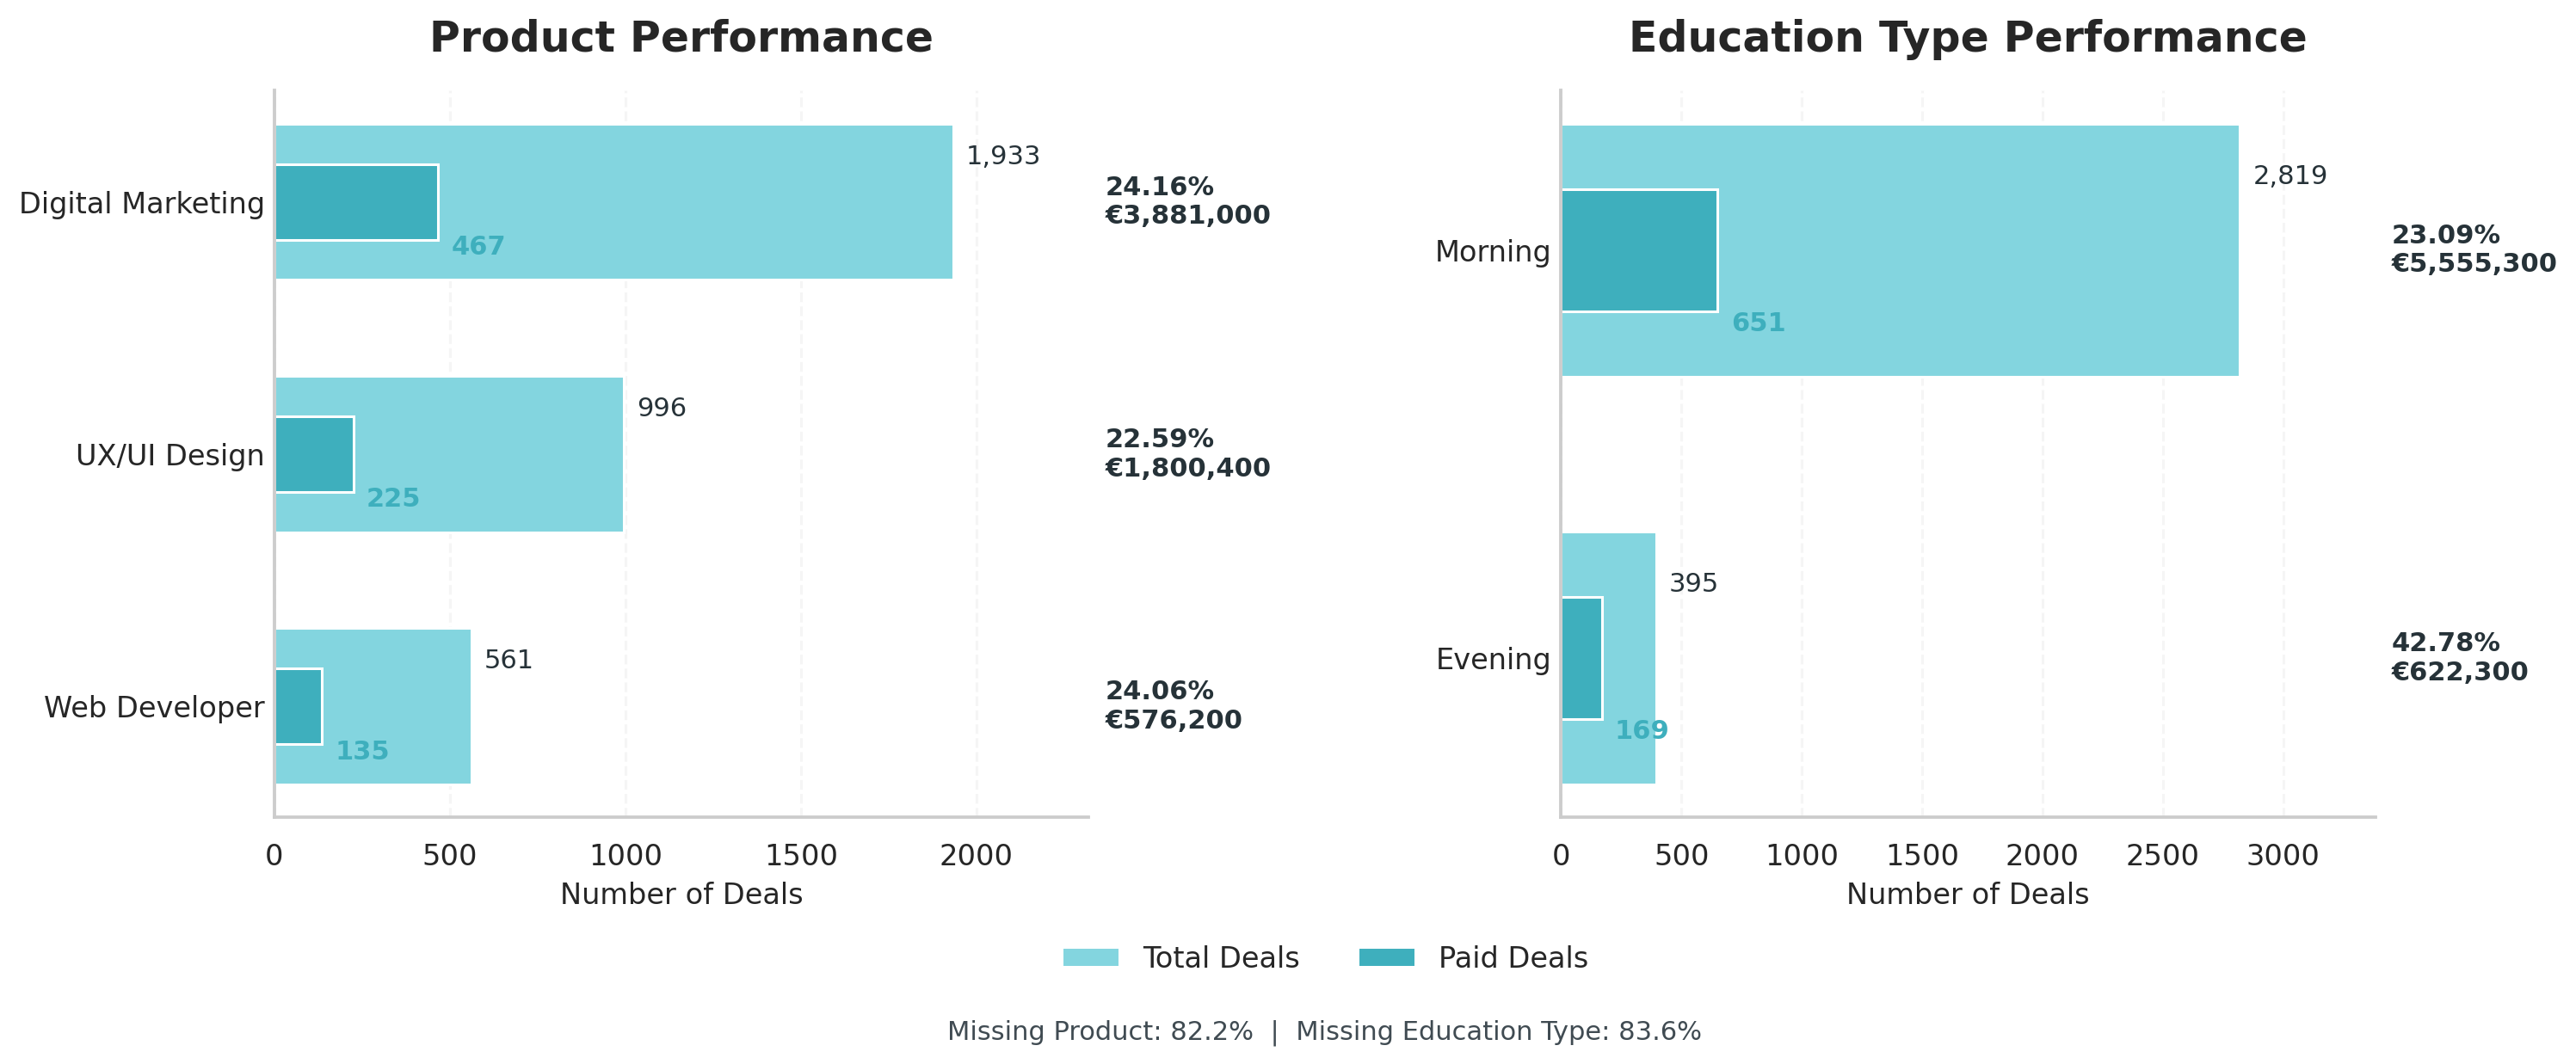

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, data, category, title in [
    (axes[0], product_performance, "Product", "Product Performance"),
    (axes[1], education_performance, "Education Type", "Education Type Performance")
]:
    y = np.arange(len(data))
    max_total = data["Total_Deals"].max()

    ax.barh(
        y,
        data["Total_Deals"],
        height=0.62,
        color=ACCENT_COLOR,
        label="Total Deals"
    )

    ax.barh(
        y,
        data["Paid_Deals"],
        height=0.30,
        color=PRIMARY_COLOR,
        label="Paid Deals"
    )

    for i, row in enumerate(data.itertuples()):
        ax.annotate(
            f"{row.Total_Deals:,}",
            (row.Total_Deals, i + 0.18),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            fontsize=10,
            color="#263238"
        )

        ax.annotate(
            f"{row.Paid_Deals:,}",
            (row.Paid_Deals, i - 0.18),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            fontsize=10,
            fontweight="bold",
            color=PRIMARY_COLOR
        )

        ax.text(
            1.02,
            i,
            f"{row.Conversion_Rate:.2f}%\n€{row.Total_Sales:,.0f}",
            transform=ax.get_yaxis_transform(),
            va="center",
            ha="left",
            fontsize=10,
            fontweight="bold",
            color="#263238"
        )

    ax.set_yticks(y)
    ax.set_yticklabels(data[category], fontsize=11)
    ax.set_xlim(0, max_total * 1.20)
    ax.set_xlabel("Number of Deals", fontsize=11)
    ax.set_ylabel("")
    ax.set_title(title, fontsize=16, fontweight="bold", pad=15)
    ax.grid(axis="x", alpha=0.18, linestyle="--")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)

    ax.spines[["top", "right"]].set_visible(False)

fig.legend(
    handles=axes[0].containers[:2],
    labels=["Total Deals", "Paid Deals"],
    loc="lower center",
    bbox_to_anchor=(0.5, 0.07),
    ncol=2,
    frameon=False,
    fontsize=11
)

fig.text(
    0.5,
    0.035,
    (
        f"Missing Product: {deals['Product'].isna().mean():.1%}  |  "
        f"Missing Education Type: {deals['Education Type'].isna().mean():.1%}"
    ),
    ha="center",
    fontsize=10,
    color="#404B52"
)

fig.subplots_adjust(
    left=0.13,
    right=0.87,
    top=0.87,
    bottom=0.23,
    wspace=0.58
)

plt.show()

Conclusion

**Digital Marketing is the leading product** in terms of deal volume (1,933), paid deals (467), and total sales (€3,881,000). UX/UI Design ranks second, followed by Web Developer. The observed conversion rates are relatively similar across all three products, ranging from 22.59% to 24.16%.

**Morning is the most popular education format**, generating significantly more deals, payments, and total sales (€5,555,300). However, Evening demonstrates a substantially higher observed conversion rate (42.78% vs. 23.09%).

It is important to consider the high proportion of missing values: **82.2% for `Product` and 83.6% for `Education Type`**. Since these fields are more frequently populated for paid deals, the calculated conversion rates may be biased. This limitation should be taken into account when interpreting the results.

# 6. Geographic Analysis

## 6.1 Geographic Data Preparation

In [ ]:
with open("/content/drive/MyDrive/Final_Project/city_data_google_en.json", "r") as json_file:
    city_data_read = json.load(json_file)

In [ ]:
def get_city_info(city):
    info = city_data_read.get(city, {})
    return pd.Series({
        'longitude': info.get('longitude', None),
        'latitude': info.get('latitude', None),
        'country': info.get('country', None),
        'city': info.get('city', None),
        'federal_state': info.get('federal_state', None)
    })

In [ ]:
deals['City'] = deals['City'].fillna('Unknown')
deals[['longitude', 'latitude', 'country', 'city', 'federal_state']] = deals['City'].apply(get_city_info)

In [ ]:
deals.head()

,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch,Demo Access,SLA Seconds,longitude,latitude,country,city,federal_state
0,5805028000056864695,Ben Hall,NaT,NaN,New Lead,NaN,/eng/test,03.07.23women,v16,women,Facebook Ads,NaN,NaN,NaN,2024-06-21 15:30:00,<NA>,<NA>,<NA>,<NA>,5805028000056849495,Unknown,NaN,False,NaN,NaN,NaN,None,None,None
1,5805028000056859489,Ulysses Adams,NaT,NaN,New Lead,NaN,/at-eng,NaN,NaN,NaN,Organic,NaN,Web Developer,Morning,2024-06-21 15:23:00,6,<NA>,0,2000,5805028000056834471,Unknown,NaN,True,NaN,NaN,NaN,None,None,None
2,5805028000056832357,Ulysses Adams,2024-06-21,D - Non Target,Lost,Non target,/at-eng,engwien_AT,b1-at,21_06_2024,Telegram posts,NaN,NaN,NaN,2024-06-21 14:45:00,<NA>,<NA>,<NA>,<NA>,5805028000056854421,Unknown,NaN,False,1603.0,NaN,NaN,None,None,None
3,5805028000056824246,Eva Kent,2024-06-21,E - Non Qualified,Lost,Invalid number,/eng,04.07.23recentlymoved_DE,bloggersvideo14com,recentlymoved,Facebook Ads,NaN,NaN,NaN,2024-06-21 13:32:00,<NA>,<NA>,<NA>,<NA>,5805028000056889351,Unknown,NaN,False,3604.0,NaN,NaN,None,None,None
4,5805028000056873292,Ben Hall,2024-06-21,D - Non Target,Lost,Non target,/eng,discovery_DE,website,NaN,Google Ads,NaN,NaN,NaN,2024-06-21 13:21:00,<NA>,<NA>,<NA>,<NA>,5805028000056876176,Unknown,NaN,False,3192.0,NaN,NaN,None,None,None


In [ ]:
deals["country"].value_counts()

,count
country,
Germany,2565
Poland,26
Austria,21
Russia,13
Ukraine,6
Netherlands,5
Kazakhstan,4
United States,4
Czechia,3


In [ ]:
deals[deals['City'] != 'Unknown'].head()

,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch,Demo Access,SLA Seconds,longitude,latitude,country,city,federal_state
32,5805028000056714532,Ulysses Adams,NaT,NaN,Registered on Webinar,NaN,/webinar,webinar1906,NaN,invitation,CRM,NaN,NaN,NaN,2024-06-20 21:08:00,<NA>,<NA>,<NA>,<NA>,5805028000044019127,Berlin,NaN,False,NaN,13.404954,52.520007,Germany,Berlin,Berlin
39,5805028000056731279,Ulysses Adams,NaT,NaN,Registered on Webinar,NaN,/webinar,NaN,NaN,NaN,Organic,NaN,NaN,NaN,2024-06-20 17:57:00,<NA>,<NA>,<NA>,<NA>,5805028000054755989,Lahnstein,NaN,False,NaN,7.609363,50.307827,Germany,Lahnstein,Rhineland-Palatinate
49,5805028000056683030,Charlie Davis,NaT,C - Low,Waiting For Payment,NaN,/eng/test,performancemax_eng_DE,_{region_name}_,NaN,Google Ads,NaN,Web Developer,Morning,2024-06-20 12:34:00,6,<NA>,1000,9000,5805028000056690015,Crailsheim,NaN,False,1239.0,10.063357,49.133735,Germany,Crailsheim,Baden-Württemberg
50,5805028000056568397,Paula Underwood,NaT,NaN,Registered on Webinar,NaN,/webinar,NaN,NaN,NaN,Organic,NaN,NaN,NaN,2024-06-20 12:17:00,<NA>,<NA>,<NA>,<NA>,5805028000020664131,Prenzlau,B1,False,NaN,13.862376,53.316844,Germany,Prenzlau,Brandenburg
53,5805028000056558351,Ulysses Adams,NaT,C - Low,Waiting For Payment,NaN,/eng,NaN,NaN,NaN,SMM,NaN,Web Developer,Morning,2024-06-20 11:16:00,6,<NA>,1000,9000,5805028000056578244,Dortmund,B1,False,589.0,7.465298,51.513587,Germany,Dortmund,North Rhine-Westphalia


In [ ]:
for city in deals['City'].unique():
    print(city)

Unknown
Berlin
Lahnstein
Crailsheim
Prenzlau
Dortmund
Stuttgart
München
Wien
Offenbach am Main
Eberbach
Görlitz
Pfedelbach
Unterhaching
Karl-Liebknecht str. 24, Hildburghausen, Thüringen
Sonneberg
Düsseldorf
-
Pirmasens
Lutherstadt Wittenberg
Gommern
Rüdesheim am Rhein
Dresden
Passau
Leipzig
Bielefeld
Karlsruhe
Hamm
Wermelskirchen
Waldbronn
Kassel
Wenzenbach
Duisburg
Witzeeze
Leinfelden-Echterdingen
Kerpen
Ahrensburg
Schwandorf
Merseburg
Dabrowa Gornicza
Pommelsbrunn
Regensburg
Herzogenrath
Mainz
Podskalie
Zinnowitz
Quedlinburg
Poland , Gdansk , Al. Grunwaldzka 7, ap. 1a
Wolfsburg
Bochum
Weilburg
Weingarten
Wiesbaden
Dillenburg
Neu-Ulm
Celle
Neu Wulmstorf
Marburg
Lauter-Bernsbach
Bonn
Riedstadt
Rosenheim
Herford
Mönchengladbach
Neuburg
Rostock
Bad Oeynhausen
Chemnitz
Diez
Leutershausen
Nürnberg
Korschenbroich
Laubach
Teublitz
Düren
Zwickau
Bremen
Vor Ebersbach 1, 77761 Schiltach
Halle
Cloppenburg
Hannover
Weißenburg in Bayern
Erbach
Leonberg
Mannheim
Jünkerath
Essen
Osterode am Harz
Vi

In [ ]:
deals['City'] = deals.City.replace('-', "Unknown")
deals['City'] = deals.City.replace('Karl-Liebknecht str. 24, Hildburghausen, Thüringen', "Hildburghausen")
deals['City'] = deals.City.replace('Poland , Gdansk , Al. Grunwaldzka 7, ap. 1a', "Gdansk")
deals['City'] = deals.City.replace('Vor Ebersbach 1, 77761 Schiltach', "Schiltach")
deals['City'] = deals.City.replace('Düsseldorf - Pirmasens', "Düsseldorf")

In [ ]:
missing_cities = deals.loc[
    deals[['latitude']].isna().all(axis=1),
    'City'
].dropna().unique()

print(f"Unique cities without geographic data: {len(missing_cities)}")
print(sorted(missing_cities))

Unique cities without geographic data: 1
['Unknown']


In [ ]:
# For Power BI
deals.to_csv(
    "Deals.csv",
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d %H:%M:%S"
)
print("Deals dataset saved successfully.")

Deals dataset saved successfully.


In [ ]:
display(
    deals.loc[
        deals["longitude"].notna(),
        ["longitude", "latitude"]
    ].head(10)
)

,longitude,latitude
32,13.404954,52.520007
39,7.609363,50.307827
49,10.063357,49.133735
50,13.862376,53.316844
53,7.465298,51.513587
58,9.182932,48.775846
64,11.581981,48.135125
67,13.404954,52.520007
74,11.581981,48.135125
81,13.404954,52.520007


## 6.2 Geographic Distribution and Sales Performance Analysis

In [ ]:
city_performance = (
    deals.loc[
        deals["city"].notna()
        & deals["latitude"].notna()
        & deals["longitude"].notna()
    ]
    .assign(
        Is_Paid=lambda df: df["Stage"].eq("Payment Done"),
        Sales_Amount=lambda df: df["Offer Total Amount"].where(
            df["Stage"].eq("Payment Done"), 0
        )
    )
    .groupby(
        ["city", "country", "latitude", "longitude"],
        as_index=False,
        dropna=False
    )
    .agg(
        Total_Deals=("Id", "size"),
        Paid_Deals=("Is_Paid", "sum"),
        Total_Sales=("Sales_Amount", "sum")
    )
)

In [ ]:
city_performance["Conversion_Rate"] = (
    city_performance["Paid_Deals"]
    / city_performance["Total_Deals"] * 100
)

city_performance = city_performance.sort_values(
    "Total_Deals", ascending=False
).reset_index(drop=True)

display(city_performance.head(20))

,city,country,latitude,longitude,Total_Deals,Paid_Deals,Total_Sales,Conversion_Rate
0,Berlin,Germany,52.520007,13.404954,263,78,635900,29.657795
1,München,Germany,48.135125,11.581981,87,27,175000,31.034483
2,Hamburg,Germany,53.548828,9.987170,78,23,170900,29.487179
3,Nürnberg,Germany,49.454288,11.074564,52,9,83400,17.307692
4,Leipzig,Germany,51.339695,12.373075,52,18,146500,34.615385
5,Düsseldorf,Germany,51.223041,6.782455,47,7,60000,14.893617
6,Frankfurt,Germany,50.110922,8.682127,34,7,53500,20.588235
7,Dresden,Germany,51.050409,13.737262,34,9,98500,26.470588
8,Dortmund,Germany,51.513587,7.465298,32,4,29500,12.500000
9,Köln,Germany,50.937531,6.960279,30,8,67500,26.666667


In [ ]:
print("Total deals:", len(deals))
print("Deals with geographic data:", city_performance["Total_Deals"].sum())
print("Paid deals with geographic data:", city_performance["Paid_Deals"].sum())
print("Unique geographic locations:", len(city_performance))
print("Total sales:", f'€{city_performance["Total_Sales"].sum():,.0f}')

Total deals: 19610
Deals with geographic data: 2674
Paid deals with geographic data: 714
Unique geographic locations: 869
Total sales: €5,136,600


In [ ]:
city_map = city_performance.dropna(
    subset=["latitude", "longitude", "city"]
).copy()

city_map = city_map.loc[city_map["Total_Deals"] > 0].copy()

city_map["size_for_plot"] = np.sqrt(city_map["Total_Deals"])

top_cities_map = city_map.nlargest(15, "Total_Deals").copy()

In [ ]:
geo_colorscale = [
    [0.00, "#24727D"],
    [0.20, COLORS["aqua"]],
    [0.45, COLORS["light_aqua"]],
    [0.70, COLORS["apricot"]],
    [1.00, "#E58C4D"]
]

fig = px.scatter_map(
    city_map,
    lat="latitude",
    lon="longitude",
    size="size_for_plot",
    color="Total_Deals",
    color_continuous_scale=geo_colorscale,
    range_color=[
        city_map["Total_Deals"].min(),
        city_map["Total_Deals"].max()
    ],
    size_max=34,
    zoom=5.1,
    center={"lat": 51.1657, "lon": 10.4515},
    map_style="carto-positron",
    custom_data=[
        "city",
        "country",
        "Total_Deals",
        "Paid_Deals",
        "Conversion_Rate",
        "Total_Sales"
    ]
)

fig.update_traces(
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        "Country: %{customdata[1]}<br>"
        "Total Deals: %{customdata[2]:,.0f}<br>"
        "Paid Deals: %{customdata[3]:,.0f}<br>"
        "Conversion Rate: %{customdata[4]:.2f}%<br>"
        "Total Sales: €%{customdata[5]:,.0f}"
        "<extra></extra>"
    ),
    opacity=0.85
)

fig.add_trace(
    go.Scattermap(
        lat=top_cities_map["latitude"],
        lon=top_cities_map["longitude"],
        mode="text",
        text=top_cities_map["city"],
        textposition="top right",
        textfont=dict(
            size=11,
            color="#263238"
        ),
        showlegend=False,
        hoverinfo="skip"
    )
)

fig.update_layout(
    title=dict(
        text="<b>Geographic Distribution of Deals by City</b>",
        x=0.5,
        xanchor="center",
        y=0.96,
        font=dict(
            size=16,
            color="#263238"
        )
    ),
    height=800,
    margin=dict(
        l=0,
        r=0,
        t=65,
        b=15
    ),
    paper_bgcolor="white",
    font=dict(
        size=11,
        color="#263238"
    ),
    coloraxis_colorbar=dict(
        title="Total Deals",
        thickness=16,
        len=0.65,
        y=0.5,
        tickfont=dict(size=10)
    )
)

fig.show()

In [ ]:
top10_cities = (
    city_performance
    .nlargest(10, "Total_Deals")
    .sort_values("Total_Deals")
)

In [ ]:
fig = go.Figure()

fig.add_trace(
    go.Bar(
        x=top10_cities["Total_Deals"],
        y=top10_cities["city"],
        orientation="h",
        name="Total Deals",
        marker_color=ACCENT_COLOR,
        width=0.65,
        text=top10_cities["Total_Deals"],
        textposition="outside",
        customdata=top10_cities[
            ["Paid_Deals", "Conversion_Rate", "Total_Sales", "country"]
        ].to_numpy(),
        hovertemplate=(
            "<b>%{y}</b><br>"
            "Country: %{customdata[3]}<br>"
            "Total Deals: %{x:,.0f}<br>"
            "Paid Deals: %{customdata[0]:,.0f}<br>"
            "Conversion Rate: %{customdata[1]:.2f}%<br>"
            "Total Sales: €%{customdata[2]:,.0f}"
            "<extra></extra>"
        )
    )
)

fig.add_trace(
    go.Bar(
        x=top10_cities["Paid_Deals"],
        y=top10_cities["city"],
        orientation="h",
        name="Paid Deals",
        marker_color=PRIMARY_COLOR,
        width=0.30,
        text=top10_cities["Paid_Deals"],
        textposition="outside",
        hovertemplate=(
            "<b>%{y}</b><br>"
            "Paid Deals: %{x:,.0f}"
            "<extra></extra>"
        )
    )
)

fig.add_trace(
    go.Scatter(
        x=[330] * len(top10_cities),
        y=top10_cities["city"],
        mode="text",
        text=top10_cities["Conversion_Rate"].map(
            lambda x: f"{x:.2f}%"
        ),
        textfont=dict(
            size=12,
            color="#263238"
        ),
        hoverinfo="skip",
        showlegend=False
    )
)

fig.add_trace(
    go.Scatter(
        x=[415] * len(top10_cities),
        y=top10_cities["city"],
        mode="text",
        text=top10_cities["Total_Sales"].map(
            lambda x: f"€{x:,.0f}"
        ),
        textfont=dict(
            size=12,
            color="#263238"
        ),
        hoverinfo="skip",
        showlegend=False
    )
)

fig.update_layout(
    title=dict(
        text="<b>Top 10 Cities by Deal Volume</b>",
        x=0.5,
        xanchor="center",
        font=dict(size=16, color="#263238")
    ),
    barmode="overlay",
    height=720,
    width=1500,
    paper_bgcolor="white",
    plot_bgcolor="white",
    font=dict(size=12, color="#263238"),
    xaxis=dict(
        title="Number of Deals",
        showgrid=True,
        gridcolor="#EAEFF1",
        zeroline=False,
        range=[0, 475],
        tickvals=list(range(0, 301, 50))
    ),
    yaxis=dict(
        title="",
        showgrid=False,
        automargin=True
    ),
    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.15,
        yanchor="top"
    ),
    margin=dict(
        l=150,
        r=40,
        t=110,
        b=100
    ),
    bargap=0.35
)

fig.add_annotation(
    x=330,
    y=1.06,
    xref="x",
    yref="paper",
    text="<b>CONVERSION</b>",
    showarrow=False,
    font=dict(size=12, color="#263238")
)

fig.add_annotation(
    x=415,
    y=1.06,
    xref="x",
    yref="paper",
    text="<b>TOTAL SALES (€)</b>",
    showarrow=False,
    font=dict(size=12, color="#263238")
)

fig.add_vline(
    x=305,
    line_width=1,
    line_color="#EAEFF1"
)

fig.show()

In [ ]:
print("GERMAN LANGUAGE LEVELS")

display(
    deals["Level of Deutsch"]
    .value_counts(dropna=False)
)

print("Missing values:", deals["Level of Deutsch"].isna().sum())
print("Missing share:", f'{deals["Level of Deutsch"].isna().mean():.2%}')

print("\nCOMPLETENESS BY PAYMENT STATUS")

display(
    pd.crosstab(
        deals["Stage"].eq("Payment Done"),
        deals["Level of Deutsch"].notna(),
        normalize="index"
    ).mul(100).round(2)
)

print("\nGEOGRAPHIC AND LANGUAGE DATA COVERAGE")

print(
    "Deals with both city and language level:",
    deals.loc[
        deals["city"].notna()
        & deals["Level of Deutsch"].notna()
    ].shape[0]
)

GERMAN LANGUAGE LEVELS


,count
Level of Deutsch,
NaN,18094
B1,996
A2,235
B2,203
C1,33
A1,29
A0,16
C2,4


Missing values: 18094
Missing share: 92.27%

COMPLETENESS BY PAYMENT STATUS


Level of Deutsch,False,True
Stage,,
False,94.17,5.83
True,49.88,50.12



GEOGRAPHIC AND LANGUAGE DATA COVERAGE
Deals with both city and language level: 1280


In [ ]:
language_city_counts = (
    deals.dropna(subset=["city", "Level of Deutsch"])
    .groupby(["city", "Level of Deutsch"])
    .size()
    .reset_index(name="Total_Deals")
)

print("Deals with city and language level:", language_city_counts["Total_Deals"].sum())
print("City-language combinations:", len(language_city_counts))
print("Combinations with at least 5 deals:", (language_city_counts["Total_Deals"] >= 5).sum())
print("Combinations with at least 10 deals:", (language_city_counts["Total_Deals"] >= 10).sum())

display(
    language_city_counts
    .sort_values("Total_Deals", ascending=False)
    .head(20)
)

Deals with city and language level: 1280
City-language combinations: 591
Combinations with at least 5 deals: 43
Combinations with at least 10 deals: 12


,city,Level of Deutsch,Total_Deals
51,Berlin,B1,69
50,Berlin,A2,27
307,Leipzig,B1,25
120,Düsseldorf,B1,25
52,Berlin,B2,24
211,Hamburg,B1,24
408,Nürnberg,B1,24
374,München,B1,14
116,Duisburg,B1,11
344,Mannheim,B1,10


In [ ]:
language_levels = sorted(
    deals["Level of Deutsch"].dropna().unique()
)

language_performance = (
    deals.loc[deals["Level of Deutsch"].isin(language_levels)]
    .assign(
        Deal_Status=lambda df: np.where(
            df["Stage"].eq("Payment Done"),
            "Paid",
            "Not Paid"
        )
    )
    .groupby(["Level of Deutsch", "Deal_Status"], as_index=False)
    .agg(Total_Deals=("Id", "size"))
)

In [ ]:
language_performance["Level of Deutsch"] = pd.Categorical(
    language_performance["Level of Deutsch"],
    categories=language_levels,
    ordered=True
)

language_performance = language_performance.sort_values(
    ["Level of Deutsch", "Deal_Status"]
).reset_index(drop=True)

In [ ]:
language_performance["Share"] = (
    language_performance["Total_Deals"]
    / language_performance.groupby("Level of Deutsch", observed=True)["Total_Deals"].transform("sum")
    * 100
)

In [ ]:
source_nodes = language_performance["Level of Deutsch"].astype(str).map(
    {level: i for i, level in enumerate(language_levels)}
)

target_nodes = language_performance["Deal_Status"].map({
    "Paid": len(language_levels),
    "Not Paid": len(language_levels) + 1
})

In [ ]:
link_colors = np.where(
    language_performance["Deal_Status"].eq("Paid"),
    COLORS["apricot"],
    COLORS["pale_aqua"]
)

In [ ]:
fig = go.Figure(
    go.Sankey(
        arrangement="fixed",
        node=dict(
            pad=22,
            thickness=22,
            line=dict(color="white", width=1),
            label=[
                f"<b>{level}</b>" for level in language_levels
            ] + ["<b>Paid</b>", "<b>Not Paid</b>"],
            color=[
                COLORS["pale_aqua"],
                COLORS["light_aqua"],
                COLORS["aqua"],
                COLORS["aqua"],
                COLORS["light_aqua"],
                COLORS["pale_aqua"],
                COLORS["lavender"],
                COLORS["apricot"],
                COLORS["light_aqua"]
            ],
            x=[0.03] * len(language_levels) + [0.97, 0.97],
            y=np.linspace(0.02, 0.96, len(language_levels)).tolist() + [0.28, 0.72],
            hovertemplate="%{label}<br>Total Deals: %{value:,.0f}<extra></extra>"
        ),
        link=dict(
            source=source_nodes,
            target=target_nodes,
            value=language_performance["Total_Deals"],
            color=link_colors,
            customdata=language_performance["Share"],
            hovertemplate=(
                "%{source.label} → %{target.label}<br>"
                "Deals: %{value:,.0f}<br>"
                "Share within level: %{customdata:.2f}%"
                "<extra></extra>"
            )
        )
    )
)

fig.update_layout(
    title=dict(
        text="<b>German Language Proficiency and Deal Outcomes</b>",
        x=0.5,
        xanchor="center",
        font=dict(size=16, color="#263238")
    ),
    width=1400,
    height=720,
    paper_bgcolor="white",
    font=dict(size=13, color="#263238"),
    margin=dict(l=100, r=100, t=90, b=50)
)

fig.show()

In [ ]:
city_language_performance = (
    deals.dropna(subset=["city", "Level of Deutsch"])
    .assign(
        Is_Paid=lambda df: df["Stage"].eq("Payment Done")
    )
    .groupby(["city", "Level of Deutsch"], as_index=False)
    .agg(
        Total_Deals=("Id", "size"),
        Paid_Deals=("Is_Paid", "sum")
    )
)

city_language_performance["Conversion_Rate"] = (
    city_language_performance["Paid_Deals"]
    / city_language_performance["Total_Deals"] * 100
)

display(
    city_language_performance
    .sort_values("Total_Deals", ascending=False)
    .head()
)

,city,Level of Deutsch,Total_Deals,Paid_Deals,Conversion_Rate
51,Berlin,B1,69,28,40.579710
50,Berlin,A2,27,5,18.518519
307,Leipzig,B1,25,9,36.000000
120,Düsseldorf,B1,25,4,16.000000
52,Berlin,B2,24,5,20.833333


In [ ]:
top10_language_cities = (
    city_language_performance
    .groupby("city")["Total_Deals"]
    .sum()
    .nlargest(10)
    .index
)

bubble_data = city_language_performance.loc[
    city_language_performance["city"].isin(top10_language_cities)
].copy()

bubble_data = bubble_data.loc[
    bubble_data["Total_Deals"] >= 5
].copy()


city_order = (
    bubble_data
    .groupby("city")["Total_Deals"]
    .sum()
    .sort_values(ascending=False)
    .index[::-1]
    .tolist()
)

In [ ]:
max_conversion = bubble_data["Conversion_Rate"].max()
max_conversion_rounded = np.ceil(max_conversion / 5) * 5

In [ ]:
fig = px.scatter(
    bubble_data,
    x="Level of Deutsch",
    y="city",
    size="Total_Deals",
    color="Conversion_Rate",
    size_max=55,
    range_color=[0, max_conversion_rounded],
    category_orders={
        "Level of Deutsch": language_levels,
        "city": city_order
    },
    color_continuous_scale=[
        [0.00, "#1F5F6B"],         # тёмный teal
        [0.50, COLORS["aqua"]],    # основной aqua из палитры
        [1.00, "#C97836"]          # тёмный warm accent
    ],
    custom_data=[
        "Total_Deals",
        "Paid_Deals",
        "Conversion_Rate"
    ]
)

fig.update_traces(
    marker=dict(
        opacity=0.88,
        line=dict(color="white", width=1)
    ),
    hovertemplate=(
        "<b>%{y} — %{x}</b><br>"
        "Total Deals: %{customdata[0]:,.0f}<br>"
        "Paid Deals: %{customdata[1]:,.0f}<br>"
        "Conversion Rate: %{customdata[2]:.2f}%"
        "<extra></extra>"
    )
)


fig.update_layout(
    title=dict(
        text="<b>German Language Proficiency and Conversion by City</b>",
        x=0.5,
        xanchor="center",
        font=dict(size=16, color="#263238")
    ),
    width=1400,
    height=720,
    paper_bgcolor="white",
    plot_bgcolor="white",
    font=dict(size=12, color="#263238"),
    margin=dict(l=140, r=100, t=90, b=80),
    showlegend=False,
    coloraxis_colorbar=dict(
        title="Conversion",
        thickness=16
    )
)


fig.update_xaxes(
    title=None,
    showgrid=True,
    gridcolor="#EAEFF1"
)

fig.update_yaxes(
    title=None,
    showgrid=True,
    gridcolor="#EAEFF1",
    categoryorder="array",
    categoryarray=city_order
)

fig.show()

Conclusion

The geographic analysis shows that **deals are primarily concentrated in Germany**, particularly in North Rhine-Westphalia and southern Germany. Berlin leads with 263 deals, 78 paid deals, and €635,900 in total sales, followed by Munich (87 deals) and Hamburg (78 deals). Among the top 10 cities, **Leipzig demonstrates the highest conversion rate (34.62%)**, followed by Munich (31.03%) and Berlin (29.66%). Dortmund (12.50%) and Düsseldorf (14.89%) show the lowest conversion rates in this group.

The analysis of German language proficiency shows that **B1 is the dominant level**, generating the largest number of deals and payments among records with known language levels. Sales performance differs across cities: B1 conversion reaches 40.58% in Berlin, 36.00% in Leipzig, and 16.00% in Düsseldorf. Overall, the results indicate that sales success varies not only geographically but also across combinations of cities and language proficiency levels.

**Data limitation:** Geographic information is available for 13.6% of deals, while `Level of Deutsch` is missing in 92.27% of records. Both fields are more frequently populated for paid deals, which may affect the observed conversion rates.